# Inferring bodies of knowledge from ceramic chaînes opératoires

*Computational network archaeology on the Funnel Beaker West and Corded Ware vessels of Kroon (2024).*

A **chaîne opératoire** is the ordered sequence of techniques a potter used, e.g.
`Wet clay > Modelling > Coiling > Pressure > Scraping > Wet smoothing > Simple incision > Leather-hard > Dry > Open firing`.
Kroon (2024) recorded one chain for each of 276 vessels from the Netherlands, made by potters of the **Corded Ware** (CW, 3000–2350 BCE) and of the **Funnel Beaker West** (FBW, 4000–2800 BCE) in three phases.

**Questions**
1. **Attribution** – given the chain of a new vessel, which body of knowledge (BoK) or culture made it?
2. **Reconstruction** – given an incomplete chain, which steps are missing?
3. **Relations** – how different are the BoKs (Cultures), and what do they share?

**Approach.** Kroon compares BoKs (Cultures) through the edge weights $p(x_{t+1}\mid x_t)$ of a network of techniques. The earlier notebook `Presentation_topic_modelling.ipynb` (in `legacy/`) treats *triplets* of consecutive techniques as words, vessels as documents and BoKs as topics, and fits two topic models: **LDA** and the **hierarchical stochastic block model** (hSBM) of Gerlach, Peixoto & Altmann (2018). 

* Sections 4–6 replicate that notebook step by step with its own functions (same names, checked and corrected) and complete the hSBM with graph-tool's inference workflow. 
* Section 7 tests how solid the results are; 
* Section 8 gives the topic models richer data — vessel form, location and find context; 
* Section 9 replaces triplets by n-grams of every length; 
* Section 10 treats the chains as networks and sequences (n-gram networks, Markov models, reconstruction).

Survival and selection, missing steps, geography and maximum entropy (with the Maximum Caliber sketch) are in the auxiliary notebook [`new_attempts_experiments.ipynb`](new_attempts_experiments.ipynb).

**Main results** (details and caveats in the sections)
- **Replication.** The legacy topic-model notebook is reproduced step by step with its own functions. Scored in-sample as there, the hSBM classifies 0.59–0.64 of the vessels correctly (legacy: 0.65), and at level 1 of the hierarchy its pseudo-document groups coincide with the four BoKs (NMI 0.92).
- **Much of that separation comes from the bootstrap.** Pseudo-documents built from *randomly permuted* labels still yield clusters that "recover" them (hSBM NMI ≈ 0.3 at the legacy setting, ≈ 0.6 with 15 vessels per document). On single vessels the hSBM groups are only weakly related to BoK (NMI ≈ 0.15), and MDL rejects the overlapping model.
- **Honest accuracy is modest.** With whole sites held out, every technique-based model — LDA, both hSBM classifiers, naive Bayes, Markov — reaches 0.50–0.54 for the four BoKs (majority 0.34; ceiling 0.73, set by identical chains in different BoKs); CW vs FBW ≈ 0.80–0.83. Vessel form alone gives 0.56 and 0.80; the chain adds information beyond form mainly for the FBW phases.
- **LDA vs hSBM.** The hSBM infers 26 topics and reproduces the cultures' triplet distributions far more closely than LDA's four (JS 0.006 vs 0.042 bits), and fold-in by description length is the principled way to place a new vessel in it. For attribution the two are equivalent; LDA's probabilities are the best calibrated.
- **Richer data (Section 8).** Given vessel form, region and grid cell as extra words, the tripartite hSBM rises from 0.52 to 0.60 with sites held out, while LDA hardly moves (0.51 → 0.53); the metadata alone give 0.56. With the site type added, the metadata alone (0.72) beat LDA and match the hSBM; none of these topic-model gains exceeds 1.5 standard errors. All the evidence is combined better by a maximum-entropy classifier (0.69 without site type; auxiliary notebook).
- **Survival and selection (proved and verified; auxiliary notebook).** A survival probability that depends on the chain cancels from attribution, and for token-wise survival the fitted topics absorb it exactly. So no survival model can raise the best accuracy for vessels selected like the training ones, and survival cannot be identified from survivors. What does help LDA is to *use* the selection instead of discarding it: the survivor proportions give a small gain, and the find context as a selection model gives a large one (≈ 0.51 → 0.77 with sites held out, under a stated independence assumption). An oracle knowing each site's composition would reach ≈ 0.95: the information is in the selection, not in the chains.
- **n-grams.** For n ≥ 2 a bag of n-grams determines the chain (proved). Accuracy hardly changes with n (≈ 0.46–0.54), while bag-of-n-gram classifiers grow more over-confident as each step is counted n times. Walks on n-gram networks are order-n Markov chains (proved); held-out, pairs and triplets suffice and longer windows memorise.
- **Sequences and reconstruction.** Pairs of steps (Kroon's edge weights) carry almost all sequential information; a hidden step is recovered exactly for 67–75 % of held-out vessels (top-3 ≈ 95 %). Kroon's Wasserstein comparison ignores which edge is which; edge-aware distances agree that CW is farthest from late FBW.

**Roadmap** — 1 Data · 2 Representation · 3 Protocol · 4 LDA · 5 hSBM · 6 LDA vs hSBM · 7 Solidity: bootstrap, cross-validation, confounders · 8 Topic models with richer data · 9 n-grams in the topic models · 10 Networks, n-gram networks and sequences · 11 Critical assessment · 12 Conclusions, data, references · *auxiliary notebook:* survival, missing steps, geography, maximum entropy

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", message="unrecognized keyword arguments")  # graph-tool

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from chaine import data, markov, distances, sbm, reconstruction, maxcal
from chaine import topic_model as tm, classifiers as clf, evaluation as ev, plotting as pl
from chaine.data import BOKS

pl.setup()
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 110)
SEED = 0                                   # one seed for the split, the bootstrap, LDA and the hSBM
STOP_K = 5                                 # <- STOP TRIPLETS: the STOP_K most frequent training triplets are deleted
                                           #    before fitting (legacy: 5). STOP_K = 0 keeps every triplet; they are
                                           #    informative (4.1) and the choice moves accuracy by about 1 point (7.4).
RUN_SBM = sbm.graph_tool_available()       # Sections 5-7 need graph-tool (conda-forge)
print("graph-tool available:", RUN_SBM)

graph-tool available: True


In [2]:
# Helpers defined in this notebook (legacy-style overlays; small numerical utilities)
from collections import Counter
from scipy.special import logsumexp
from scipy.stats import chi2_contingency, chisquare
EMP_COLOR, MODEL_COLOR = "#2a78d6", "#eb6834"      # as in the legacy notebook: C0 = empirical, C1 = model

def overlay_distributions(empirical, inferred, vocab, cultures, model_labels, title, js=None, token="triplet"):
    """Legacy-style comparison (Presentation_topic_modelling.ipynb, cells 18, 25, 80): for every culture the
    empirical distribution p(w | culture) and an inferred word distribution, drawn as overlapping
    semi-transparent horizontal bars over the full vocabulary, in vocabulary order."""
    y = np.arange(len(vocab))
    fig, axes = plt.subplots(1, len(cultures), sharey=True,
                             figsize=(4.0 * len(cultures) + 3.2, 0.14 * len(vocab) + 1.9))
    for i, (ax, c) in enumerate(zip(axes, cultures)):
        ax.barh(y, empirical[i], height=0.85, color=EMP_COLOR, alpha=0.5, label=f"empirical, {c}")
        ax.barh(y, inferred[i], height=0.85, color=MODEL_COLOR, alpha=0.5, label=model_labels[i])
        ax.set_title(pl.label(c) + ("" if js is None else f"\nJS = {js[i]:.3f} bits"), fontsize=10)
        ax.set_xlabel("probability"); ax.grid(axis="y", visible=False)
        ax.legend(loc="lower right", fontsize=7.5)
    axes[0].set_yticks(y, [pl.short(w) for w in vocab], fontsize=6.5)
    axes[0].set_ylim(len(vocab) - 0.5, -0.5)
    axes[0].set_ylabel(token)
    fig.suptitle(title, y=1.0, fontsize=11)
    fig.tight_layout()
    return fig

def softmax_rows(L):
    """Row-wise softmax of log-scores, computed stably."""
    return np.exp(L - logsumexp(L, axis=1, keepdims=True))

## 1 · Data

### 1.1 Chains and metadata
Source: Kroon (2024), DANS [doi:10.17026/AR/FAXIOW](https://doi.org/10.17026/AR/FAXIOW) (CC-BY-4.0); `scripts/prepare_data.py` builds `data/clean/`. The chains come from *Appendix C – Macroscopy paths*, which carries a vessel ID for each chain, so every vessel can be joined to its site and vessel form. The per-BoK files used in the legacy notebooks (`CW.csv`, …) contain exactly the same chains without IDs. One vessel (ID 79, CW) belongs to a site missing from Kroon's site table; it keeps its site ID for grouping.

In [3]:
df = data.load_vessels()
grammar = data.load_grammar(extra_chains=df["steps"])
vocab = sorted({x for s in df["steps"] for x in s})
y_bok = df["bok"].astype(str).to_numpy()
summary = df.groupby("bok", observed=True).agg(
    vessels=("vessel_id", "size"), sites=("site_id", "nunique"),
    distinct_chains=("chain", "nunique"), mean_length=("n_steps", "mean"))
summary.index = [pl.label(b) for b in summary.index]
print(f"{len(df)} vessels, {df['chain'].nunique()} distinct chains, {len(vocab)} distinct techniques")
summary

276 vessels, 101 distinct chains, 20 distinct techniques


,vessels,sites,distinct_chains,mean_length
CW · Corded Ware,89,65,48,10.461
EFG · FBW early,62,8,28,10.210
MI · FBW middle,95,14,55,10.611
LFG · FBW late,30,7,12,10.200


**How to read it.**
- *Shown:* for each BoK, the number of vessels, of find sites and of distinct chains, and the mean chain length (in steps).
- *Numbers:* CW has 89 vessels from 65 sites, mostly one or two per barrow. The FBW phases have 30–95 vessels from only 7–14 sites. Chains have about the same length in every BoK (10.2–10.6 steps), so length tells nothing about the BoK.
- *Evidence:* vessels of one site are correlated, so the effective sample size lies between the number of sites and the number of vessels. For early and late FBW that is between 8 and 62, and between 7 and 30.
- *Caveat:* late FBW has 30 vessels and 12 distinct chains, so every per-class number for it is noisy.

**The four labels form a hierarchy, not four peer cultures.** EFG, MI and LFG are the early, middle and late phases of FBW (the legacy `FBW.csv` is exactly their union, 62 + 95 + 30 = 187 vessels).

### 1.2 How much can a chain tell us? The ceiling
The 276 vessels have only 101 distinct chains, and identical chains occur in different BoKs. The best possible rule predicts, for each distinct chain, its most frequent label; its accuracy is a hard **ceiling** for every chain-only method.

In [4]:
distinct = {chain: set(b.astype(str)) for chain, b in df.groupby("chain")["bok"]}
shared = pd.DataFrame(0, index=BOKS, columns=BOKS)
for labels in distinct.values():
    for a in labels:
        for b in labels:
            shared.loc[a, b] += 1
ceiling = {"BoK (4 classes)": data.bayes_ceiling(df, "bok"),
           "culture (CW vs FBW)": data.bayes_ceiling(df, "culture")}
majority = {"BoK (4 classes)": df["bok"].value_counts(normalize=True).max(),
            "culture (CW vs FBW)": df["culture"].value_counts(normalize=True).max()}
print("Distinct chains shared between BoKs (diagonal = distinct chains in the BoK):")
display(shared)
pd.DataFrame({"majority baseline": majority, "chain-only ceiling": ceiling})

Distinct chains shared between BoKs (diagonal = distinct chains in the BoK):


,CW,EFG,MI,LFG
CW,48,10,15,6
EFG,10,28,16,10
MI,15,16,55,8
LFG,6,10,8,12


,majority baseline,chain-only ceiling
BoK (4 classes),0.344,0.732
culture (CW vs FBW),0.678,0.888


**How to read it.**
- *First table:* the diagonal counts the distinct chains used in each BoK; an off-diagonal entry counts the distinct chains found in *both* BoKs.
- *Second table:* the accuracy of always guessing the largest class (majority), and the best accuracy of any rule that maps a chain to a BoK (ceiling).
- *Numbers:* of the 48 distinct CW chains, 15 also occur in middle FBW and 10 in early FBW; late FBW shares 10 of its 12 chains with early FBW. A vessel carrying a shared chain cannot be attributed with certainty from the chain, whatever the model. Hence the ceilings: 0.73 for four BoKs and 0.89 for CW vs FBW, against 0.34 and 0.68 for the majority rule.
- *Caveat:* the ceiling holds for the chain alone. Evidence that is not the chain (form, place, context) can go beyond it.

### 1.3 Confounders: vessel form and burial context

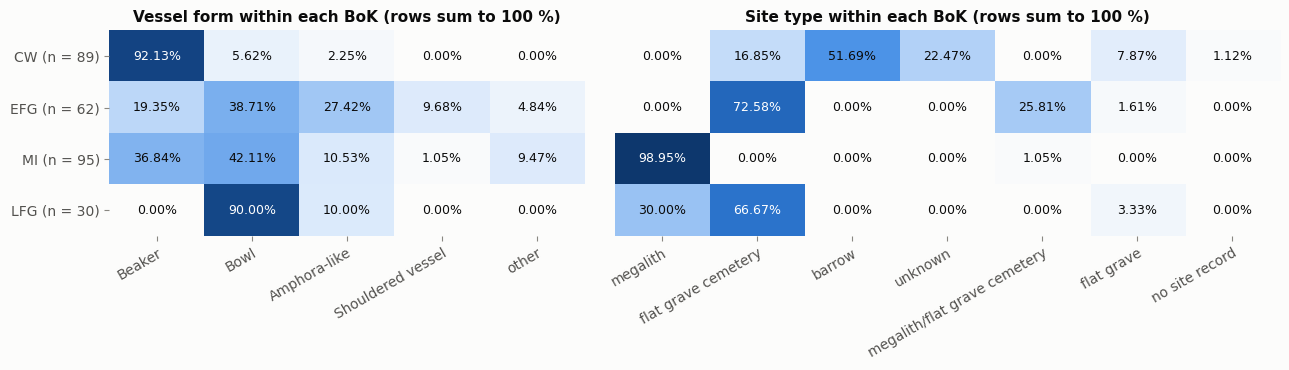

other forms: Collared flask 3, Jug 3, Bucket shape 3, Misc 2, Biberon 1
vessels per site type: megalith 103, flat grave cemetery 80, barrow 46, unknown 20, megalith/flat grave cemetery 17, flat grave 9, no site record 1


In [5]:
def shares(column, keep, missing):
    """Share of each category within each BoK, counting every vessel: categories outside `keep` are pooled
    as "other" and vessels without a value are shown as `missing`, so each row sums to 1."""
    x = df[column].fillna(missing)
    x = x.where(x.isin(keep + [missing]), "other")
    n = pd.crosstab(df["bok"], x).reindex(BOKS)
    n = n[[c for c in keep + ["other", missing] if c in n.columns]]
    return n.div(n.sum(axis=1), axis=0), n

forms = df["vessel_type"].value_counts().index[:4].tolist()        # the four commonest forms; the rest is "other"
sites = df["site_type"].value_counts().index.tolist()               # every site type, "unknown" included
vt, vt_n = shares("vessel_type", forms, "no record")
st, st_n = shares("site_type", sites, "no site record")
assert np.allclose(vt.sum(axis=1), 1) and np.allclose(st.sum(axis=1), 1) and vt_n.values.sum() == st_n.values.sum() == len(df)

rows = [f"{b} (n = {k})" for b, k in vt_n.sum(axis=1).items()]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
pl.heatmap(axes[0], vt.values, rows, vt.columns, fmt="{:.2%}", vmin=0, vmax=1)
axes[0].set_title("Vessel form within each BoK (rows sum to 100 %)")
pl.heatmap(axes[1], st.values, [""] * len(rows), st.columns, fmt="{:.2%}", vmin=0, vmax=1)
axes[1].set_title("Site type within each BoK (rows sum to 100 %)"); axes[1].tick_params(axis="y", left=False)
for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")
fig.tight_layout(); pl.save(fig, "confounders"); plt.show()
other = df["vessel_type"][~df["vessel_type"].isin(forms)].value_counts()
print("other forms:", ", ".join(f"{f} {k}" for f, k in other.items()))
print("vessels per site type:", ", ".join(f"{s} {k}" for s, k in st_n.sum(axis=0).items()))

Every vessel is counted, so each row sums to 100 %.
- *Form:* 92 % of CW vessels are beakers and 90 % of late-FBW vessels are bowls. Early and middle FBW mix bowls (39 %, 42 %), beakers (19 %, 37 %) and amphora-like vessels (27 %, 11 %). "Other" pools five rare forms: 12 vessels (collared flask, jug and bucket shape 3 each, misc 2, biberon 1), 9 of them middle FBW.
- *Context:* 94 of the 95 middle-FBW vessels come from megaliths. CW comes from barrows (46), flat graves and flat-grave cemeteries (22) and "unknown" sites (20); early and late FBW come mostly from flat-grave cemeteries.
- *"Unknown"* is Kroon's own label (Appendix B): 20 CW vessels from 15 sites, kept in museum collections (inventory numbers from 1880 to 1962) without a recorded find context.
- *"No site record"* is vessel 79 (CW, context "Graf VII no 3"): its site 39 is missing from Kroon's site table and from the rest of the DANS deposit.
- *Consequence:* form alone separates CW from late FBW, and context alone separates middle FBW from the rest. Every accuracy below must be compared with these one-variable baselines (7.3, 7.5).

- **Form:** a classifier can score by recognising *how beakers are made* rather than *who made them*.
- **Context:** phase and burial context cannot be separated.
- **Clustering:** early and late FBW come from only 8 and 7 sites; vessels of one cemetery are not independent draws, so evaluation must hold out **whole sites**.

### 1.4 Where the vessels come from
Find spots from Kroon's site table (Appendix B): one marker per location and BoK, colour and shape by BoK, marker area proportional to the number of vessels. Open markers flag positions that the source marks as approximate. Hover over a marker for the site(s), site type, vessel counts and forms. The map is interactive in Jupyter and VS Code; static viewers such as GitHub's do not display it.

CW vessels come from many sites in Drenthe and Gelderland; the FBW phases come from few sites — the middle phase almost only from megaliths in Drenthe — the clustering by site noted in 1.3.

In [6]:
import plotly.graph_objects as go

geo = df.dropna(subset=["longitude", "latitude"])
approximate = geo["approximate_position"].astype(str).str.lower().eq("true")
SYMBOL = {"CW": "circle", "EFG": "square", "MI": "triangle-up", "LFG": "diamond"}

hover, approx_at = {}, {}                         # one description per location (sites may share coordinates)
for (lon, lat), g in geo.groupby(["longitude", "latitude"]):
    sites = "<br>".join(sorted({f"{n} (site {i})" for n, i in zip(g["site_name"], g["site_id"])}))
    counts = g["bok"].astype(str).value_counts().reindex(BOKS).dropna().astype(int)
    forms = g["vessel_type"].value_counts()
    approx_at[(lon, lat)] = bool(approximate[g.index].any())
    hover[(lon, lat)] = (f"<b>{sites}</b><br>{g['region'].iloc[0]} · {', '.join(sorted(g['site_type'].unique()))}"
                         f"<br>vessels: {' · '.join(f'{b} {k}' for b, k in counts.items())}"
                         f"<br>forms: {', '.join(f'{f} {k}' for f, k in forms.items())}"
                         f"<br>{lat:.3f}° N, {lon:.3f}° E ({'approximate' if approx_at[(lon, lat)] else 'exact'} position)")

points = geo.groupby(["longitude", "latitude", "bok"], observed=True).size().rename("n").reset_index()
points["approx"] = [approx_at[k] for k in zip(points["longitude"], points["latitude"])]
points["hover"] = [hover[k] for k in zip(points["longitude"], points["latitude"])]

fig = go.Figure()
for b in BOKS:
    for is_approx in (False, True):
        q = points[(points["bok"] == b) & (points["approx"] == is_approx)].sort_values("n", ascending=False)
        fig.add_trace(go.Scattergeo(
            lon=q["longitude"], lat=q["latitude"], mode="markers", name=pl.label(b),
            legendgroup=b, showlegend=not is_approx, text=q["hover"], customdata=q["n"],
            hovertemplate="%{text}<extra>" + b + ": %{customdata} vessels</extra>",
            marker=dict(size=7 * np.sqrt(q["n"]), color=pl.COLORS[b], opacity=0.85,
                        symbol=SYMBOL[b] + ("-open" if is_approx else ""),
                        line=dict(width=1.8 if is_approx else 0.8, color=pl.COLORS[b] if is_approx else "white"))))
fig.add_trace(go.Scattergeo(lon=[None], lat=[None], mode="markers", name="open marker: approximate position",
                            marker=dict(symbol="circle-open", size=10, color=pl.INK["muted"], line=dict(width=1.8))))
fig.update_geos(projection_type="mercator", resolution=50, lonaxis_range=[4.9, 7.4], lataxis_range=[51.8, 53.5],
                showland=True, landcolor="#f0efec", showocean=True, oceancolor="#e3edf7", showlakes=True,
                lakecolor="#e3edf7", showrivers=True, rivercolor="#c9dcef", showcountries=True,
                countrycolor=pl.INK["muted"], coastlinecolor=pl.INK["muted"], showframe=False)
fig.update_layout(height=680, margin=dict(l=0, r=0, t=50, b=70), paper_bgcolor=pl.INK["surface"],
                  font=dict(color=pl.INK["secondary"]),
                  legend=dict(orientation="h", x=0.5, xanchor="center", y=-0.02, yanchor="top"),
                  title=dict(text=f"Find spots of {len(geo)} vessels at {geo.groupby(['longitude', 'latitude']).ngroups} locations",
                             font=dict(color=pl.INK["primary"])))
fig.show(renderer="plotly_mimetype+notebook_connected")
missing = df[df["longitude"].isna()]
print(f"{geo['site_id'].nunique()} sites, {int(approximate.groupby(geo['site_id']).first().sum())} with approximate positions; "
      f"not shown (no coordinates): vessels {', '.join(missing['vessel_id'])} (sites {', '.join(missing['site_id'])})")

85 sites, 41 with approximate positions; not shown (no coordinates): vessels 54, 79, 146 (sites 130, 39, 66)


**How to read it.** 273 of the 276 vessels have coordinates, at 85 of the 88 sites. CW vessels come from Drenthe (53) and Gelderland (28), mostly one barrow each. The FBW phases are concentrated in a few large cemeteries and megaliths in Drenthe and Overijssel. 41 positions are approximate (open markers), so read the map at the scale of tens of kilometres, not as distances between neighbouring sites.

## 2 · Representation: triplets as words

The legacy notebooks treat a chain as a bag of **triplets**, sliding windows of three consecutive steps (exactly the `clustered_paths_*.csv` files; `tests/test_core.py` checks the equality).

In [7]:
example = df["steps"].iloc[0]
print(" > ".join(example))
for g in data.ngrams(example, 3):
    print("   ", data.token(g))
bags = df.drop_duplicates("chain")["steps"].map(lambda s: tuple(sorted(data.ngrams(s, 3))))
print(f"\n{bags.nunique()} distinct triplet bags for {len(bags)} distinct chains")

Wet clay > Modelling > Coiling > Pressure > Scraping > Wet smoothing > Simple incision > Leather-hard > Dry > Open firing
    (Wet clay, Modelling, Coiling)
    (Modelling, Coiling, Pressure)
    (Coiling, Pressure, Scraping)
    (Pressure, Scraping, Wet smoothing)
    (Scraping, Wet smoothing, Simple incision)
    (Wet smoothing, Simple incision, Leather-hard)
    (Simple incision, Leather-hard, Dry)
    (Leather-hard, Dry, Open firing)

101 distinct triplet bags for 101 distinct chains


A bag of triplets determines the chain here (the triplets overlap like the pieces of a de Bruijn path), so little order is lost. The price is statistical: every interior step appears in up to **three** triplets, so the words of a document are strongly dependent. Models that treat them as independent evidence (LDA, naive Bayes, the SBM classifiers) count each step about three times and tend to be **over-confident** — checked with calibration metrics throughout. Section 9 repeats the analysis with n-grams of every length.

## 3 · One protocol for every model

The legacy notebook fitted its models on (almost) all vessels and then classified the same vessels. With 276 vessels from 88 sites, *how* the data are split matters more than which model is used. Write the data as $\mathcal D=\{(x_i,c_i,s_i)\}_{i=1}^{276}$: chain, BoK, site.

1. **Split by site.** Vessels of one site share potters, burial customs and recording, so a test vessel must have no site-mates in training.
   - The 88 sites are dealt into 5 folds $F_1,\dots,F_5$ (`StratifiedGroupKFold`). Each fold is a set of *whole sites* and holds about a fifth of every BoK's vessels.
   - The **test sample** of fold $f$ is $\mathcal D_f=\{i: s_i\in F_f\}$, the vessels of its held-out sites. The training sample is $\mathcal T_f=\mathcal D\setminus\mathcal D_f$.
2. **Learn everything on $\mathcal T_f$ only:** vocabulary, stop triplets, pseudo-documents, topics and partitions, priors. The test vessels are only scored.
3. **Bootstrap inside each BoK, balanced.** Let $\mathcal T_{f,c}$ be the $n_c$ training vessels of BoK $c$. Pseudo-document $j=1,\dots,100$ of BoK $c$ concatenates the triplets of $g$ vessels drawn uniformly *with replacement* from $\mathcal T_{f,c}$:
$$\tilde d_{c,j}=x_{i_1}\oplus\dots\oplus x_{i_g},\qquad i_1,\dots,i_g\overset{\text{iid}}{\sim}\mathrm{Unif}(\mathcal T_{f,c}).$$
   Every BoK gets the same number of pseudo-documents (100), whatever $n_c$. Each training vessel therefore appears $100g/n_c$ times on average: at $g=7$, about 10 times for CW and middle FBW and 26 times for late FBW. Test vessels are never pooled; each enters alone, by fold-in.
4. **Score the test vessels**, $p(c\mid x_i)$ for $i\in\mathcal D_f$.

**One split to show the steps, cross-validation for the numbers.**
- Sections 4–6 run steps 1–4 on one fold (fold 1 of seed 0): 224 training vessels from 71 sites, and 52 test vessels from the 17 held-out sites.
- Section 7 *cross-validates*. Every fold is the test sample once, so each vessel is predicted exactly once by a model that never saw its site. Three seeds (new folds, pseudo-documents and samplers) give 3 × 276 = 828 predictions; these are the numbers that count.
- For comparison, Section 7 also holds out single vessels instead of sites, and the topic models are also scored **in-sample**, as in the legacy notebook.

Every score goes into one registry `R`, always with the same metrics (explained below the split).

In [8]:
train_idx, test_idx = ev.splits(df, "site", 5, SEED)[0]
train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
y_train, y_test = train_df["bok"].astype(str).to_numpy(), test_df["bok"].astype(str).to_numpy()
R = ev.Results()
pd.DataFrame({"training": train_df["bok"].value_counts().reindex(BOKS),
              "held-out sites": test_df["bok"].value_counts().reindex(BOKS)}).T.assign(
    sites=[train_df["site_id"].nunique(), test_df["site_id"].nunique()])

bok,CW,EFG,MI,LFG,sites
training,71,52,74,27,71
held-out sites,18,10,21,3,17


These are the vessels of each BoK in the training part and in the held-out sites of the single split used in Sections 4–6; the last column counts sites. Only 3 late-FBW vessels are held out, so per-class results on this split are anecdotal. The numbers that count are the cross-validated ones of Section 7.

**How to read the scores** (every table from here on). Each model gives each vessel a probability for each of the four BoKs.

| score | what it measures | reference values |
|---|---|---|
| accuracy | share of vessels whose most probable BoK is the true one | majority rule 0.34; chain-only ceiling 0.73 |
| balanced accuracy | mean over BoKs of the share of that BoK's vessels classified correctly; small BoKs count as much as large ones | any one-BoK rule 0.25 |
| macro-F1 | mean over BoKs of F1, the harmonic mean of precision and recall | majority rule 0.13 |
| log-loss | mean of $-\ln p(\text{true BoK})$; confident mistakes cost the most | uniform guess $\ln4=1.39$; class proportions ≈ 1.31–1.33 |
| Brier | mean squared distance between the probability vector and the one-hot truth | uniform guess 0.75 |
| ECE | predictions binned by confidence (10 bins); weighted mean of $\lvert$accuracy − confidence$\rvert$ | 0 = the probabilities mean what they say |

- $n$ counts predictions: in cross-validation 276 vessels × 3 seeds = 828.
- **Noise.** Resampling whole sites, one cross-validated accuracy is uncertain by about ± 0.04–0.05, and so is a difference between two models (computed in 7.3). Changing the seed moves accuracies by only ≈ 0.01, so the seeds are not the relevant uncertainty.

## 4 · Topic model I: LDA, replicated step by step

**Model** (Blei et al. 2003): documents $d$ (vessels), words $w$ (triplets), $K$ topics,
$$\theta_d\sim\mathrm{Dir}(\alpha),\quad \phi_k\sim\mathrm{Dir}(\beta),\quad z_{dn}\sim\mathrm{Cat}(\theta_d),\quad w_{dn}\sim\mathrm{Cat}(\phi_{z_{dn}}),$$
fitted by collapsed Gibbs sampling, $p(z=k\mid\cdot)\propto(n_{dk}+\alpha)\,\frac{n_{kw}+\beta}{n_k+V\beta}$.

Each step calls the function of the legacy notebook with the same name (`src/chaine/topic_model.py`); every docstring states what was checked and what was corrected. Legacy settings are kept: 5 stop triplets, pseudo-documents of $g=7$ vessels (the legacy variable `resampled_5` actually used `group_size=7`), 100 per culture, $K=4$, $\alpha=\beta=1$, 200 Gibbs iterations. The number of stop triplets is a single switch, `STOP_K` in the setup cell (marked with `#`): `STOP_K = 0` keeps every triplet. It stays at the legacy 5 so that Sections 4–6 replicate the legacy notebook; 4.1 and 7.4 show what the choice costs.

### 4.1 Documents, vocabulary and stop triplets

In [9]:
all_docs = tm.load_pottery_data(df)                                     # legacy cell 2
train_docs = [all_docs[i] for i in train_idx]
test_docs = [all_docs[i] for i in test_idx]
vocab_full, _ = tm.extract_vocabulary(train_docs)                       # legacy cell 2
train_c, removed = tm.remove_common_triplets(train_docs, k=STOP_K)      # legacy cell 3; STOP_K: setup cell
test_c, _ = tm.remove_common_triplets(test_docs, k=STOP_K, fit_docs=train_docs)
vocabulary, _ = tm.extract_vocabulary(train_c)
vocab_index = {w: i for i, w in enumerate(vocabulary)}
print(f"vocabulary: {len(vocab_full)} triplets, {len(vocabulary)} after removing the {STOP_K} most frequent")
tm.stop_triplet_test(train_docs, removed, BOKS) if removed else None

vocabulary: 93 triplets, 88 after removing the 5 most frequent


,chi2,p_value,share CW,share EFG,share MI,share LFG
triplet,,,,,,
"(Wet clay, Modelling, Coiling)",11.292,1.025e-02,0.972,0.923,0.811,0.926
"(Modelling, Coiling, Pressure)",11.292,1.025e-02,0.972,0.923,0.811,0.926
"(Burnishing, Dry, Open firing)",60.966,3.654e-13,0.324,0.827,0.824,0.926
"(Leather-hard, Burnishing, Dry)",63.003,1.341e-13,0.282,0.827,0.770,0.926
"(Coiling, Pressure, Wet smoothing)",10.579,1.423e-02,0.549,0.481,0.459,0.185


- *Shown:* the five most frequent triplets, which the legacy pipeline removes as "stop words". For each: the χ² statistic and p-value of the test "used equally often by all four BoKs", and the share of each BoK's training vessels that contain it.
- *Numbers:*
  - The two opening triplets (wet clay → modelling → coiling → pressure) are in 81–97 % of the vessels of every BoK. They carry almost no information: p = 0.01, but the shares differ by at most 16 points.
  - The two burnishing triplets are in 28–32 % of CW vessels and 77–93 % of FBW vessels (p ≈ 10⁻¹³), so they carry strong information.
  - The fifth triplet is rarer in late FBW (19 % against 46–55 %).
- *Caveat:* removing them throws away the best CW-vs-FBW signal among the five. The cost in accuracy is small (0.01–0.02, 7.4), because burnishing also appears in other triplets.

The legacy choice is kept here, to replicate it. But a frequent triplet is not necessarily an uninformative one: the two burnishing triplets above are frequent *and* informative. So: what is the whole vocabulary, which triplets carry information about the BoK, and is it right to delete the others?

**Information of a triplet.** Let $Y_w\in\{0,1\}$ say whether a vessel contains triplet $w$. Its information about the BoK $C$ is the mutual information
$$I(Y_w;C)=\sum_{y\in\{0,1\}}\sum_{c}p(y,c)\,\log_2\frac{p(y,c)}{p(y)\,p(c)}\ \text{bits},\qquad 0\le I(Y_w;C)\le H(C)\approx1.9\ \text{bits},$$
estimated on the training vessels.
- With few vessels the estimate is biased upwards, and more so for rare triplets. We subtract its mean under 999 random relabellings of the vessels ("MI − chance").
- We test it with the permutation p-value, corrected for testing all triplets at once: the Benjamini–Hochberg $q$-value, with $q<0.05$ counted as informative.

whole vocabulary: 96 triplets in the 276 vessels, 93 of them in the training vessels; 3 occur only in held-out vessels (1.1% of the held-out tokens)


,triplets,tokens,stop_triplets
class,,,
informative (q < 0.05),27,1445,5
no evidence of information,20,349,0
too rare to judge (< 5 vessels),46,78,0


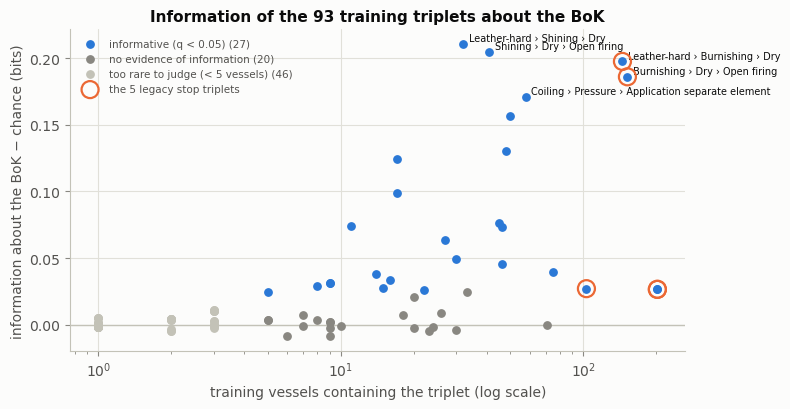

vessels  \
most informative     (Leather-hard, Shining, Dry)                                  32   
                     (Shining, Dry, Open firing)                                   41   
                     (Leather-hard, Burnishing, Dry)                              145   
                     (Burnishing, Dry, Open firing)                               152   
                     (Coiling, Pressure, Application separate element)             58   
                     (Pressure, Application separate element, Wet smoothing)       50   
legacy stop triplets (Burnishing, Dry, Open firing)                               152   
                     (Coiling, Pressure, Wet smoothing)                           103   
                     (Leather-hard, Burnishing, Dry)                              145   
                     (Modelling, Coiling, Pressure)                               202   
                     (Wet clay, Modelling, Coiling)                               202   

                                                                              MI (bits)  \
most informative     (Leather-hard, Shining, Dry)                                 0.221   
                     (Shining, Dry, Open firing)                                  0.215   
                     (Leather-hard, Burnishing, Dry)                              0.207   
                     (Burnishing, Dry, Open firing)                               0.196   
                     (Coiling, Pressure, Application separate element)            0.181   
                     (Pressure, Application separate element, Wet smoothing)      0.166   
legacy stop triplets (Burnishing, Dry, Open firing)                               0.196   
                     (Coiling, Pressure, Wet smoothing)                           0.037   
                     (Leather-hard, Burnishing, Dry)                              0.207   
                     (Modelling, Coiling, Pressure)                               0.037   
                     (Wet clay, Modelling, Coiling)                               0.037   

                                                                              MI − chance (bits)  \
most informative     (Leather-hard, Shining, Dry)                                          0.211   
                     (Shining, Dry, Open firing)                                           0.205   
                     (Leather-hard, Burnishing, Dry)                                       0.198   
                     (Burnishing, Dry, Open firing)                                        0.186   
                     (Coiling, Pressure, Application separate element)                     0.171   
                     (Pressure, Application separate element, Wet smoothing)               0.156   
legacy stop triplets (Burnishing, Dry, Open firing)                                        0.186   
                     (Coiling, Pressure, Wet smoothing)                                    0.027   
                     (Leather-hard, Burnishing, Dry)                                       0.198   
                     (Modelling, Coiling, Pressure)                                        0.027   
                     (Wet clay, Modelling, Coiling)                                        0.027   

                                                                                  q  \
most informative     (Leather-hard, Shining, Dry)                             0.006   
                     (Shining, Dry, Open firing)                              0.006   
                     (Leather-hard, Burnishing, Dry)                          0.006   
                     (Burnishing, Dry, Open firing)                           0.006   
                     (Coiling, Pressure, Application separate element)        0.006   
                     (Pressure, Application separate element, Wet smoothing)  0.006   
legacy stop triplets (Burnishing, Dry, Open firing)                           0.006   
                   

In [ ]:
def triplet_information(docs, n_perm=999, seed=SEED):
    """For every triplet: in how many vessels it occurs, the mutual information (bits) between its presence and
    the BoK, that information minus its mean under random relabelling of the vessels (the small-sample bias),
    the permutation p-value, and the Benjamini–Hochberg q-value over all triplets."""
    words = sorted({t for d in docs for t in d["triplets"]})
    col = {w: j for j, w in enumerate(words)}
    Y = np.zeros((len(docs), len(words)))
    for i, d in enumerate(docs):
        Y[i, [col[t] for t in set(d["triplets"])]] = 1
    labels = np.array([BOKS.index(d["culture"]) for d in docs])

    def mi(lab):
        C = np.eye(len(BOKS))[lab]
        n11, n_c = Y.T @ C, C.sum(0)                                   # vessels with w in BoK c; vessels in BoK c
        joint = np.stack([n_c - n11, n11]) / len(lab)                  # p(absent/present, c), per triplet
        expected = joint.sum(2, keepdims=True) * (n_c / len(lab))      # p(absent/present) p(c)
        with np.errstate(divide="ignore", invalid="ignore"):
            return np.where(joint > 0, joint * np.log2(joint / expected), 0.0).sum((0, 2))

    obs = mi(labels)
    rng = np.random.default_rng(seed)
    null = np.array([mi(rng.permutation(labels)) for _ in range(n_perm)])
    p = (1 + (null >= obs).sum(0)) / (1 + n_perm)
    rank = np.argsort(p)
    q = np.empty_like(p)
    q[rank] = np.minimum.accumulate((p[rank] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    return pd.DataFrame({"vessels": Y.sum(0).astype(int), "MI (bits)": obs, "MI − chance (bits)": obs - null.mean(0),
                         "p": p, "q": np.minimum(q, 1)}, index=words)

whole = sorted({t for d in all_docs for t in d["triplets"]})
test_only = sorted(set(whole) - set(vocab_full))
unseen = np.mean([t not in set(vocab_full) for d in test_docs for t in d["triplets"]])
print(f"whole vocabulary: {len(whole)} triplets in the 276 vessels, {len(vocab_full)} of them in the training vessels; "
      f"{len(test_only)} occur only in held-out vessels ({unseen:.1%} of the held-out tokens)")

info = triplet_information(train_docs)
info["class"] = np.select([info["vessels"] < 5, info["q"] < 0.05],
                          ["too rare to judge (< 5 vessels)", "informative (q < 0.05)"], "no evidence of information")
info["legacy stop triplet"] = info.index.isin(removed)
display(info.groupby("class").agg(triplets=("vessels", "size"), tokens=("vessels", "sum"),
                                  stop_triplets=("legacy stop triplet", "sum")))

fig, ax = plt.subplots(figsize=(8, 4.2))
for cls, color in [("informative (q < 0.05)", pl.COLORS["CW"]), ("no evidence of information", pl.INK["muted"]),
                   ("too rare to judge (< 5 vessels)", pl.INK["axis"])]:
    s = info[info["class"] == cls]
    ax.scatter(s["vessels"], s["MI − chance (bits)"], s=28, color=color, label=f"{cls} ({len(s)})", zorder=3)
stop = info[info["legacy stop triplet"]]
ax.scatter(stop["vessels"], stop["MI − chance (bits)"], s=150, facecolors="none", edgecolors=pl.COLORS["EFG"],
           linewidths=1.6, label="the 5 legacy stop triplets", zorder=4)
for w, r in info.nlargest(5, "MI − chance (bits)").iterrows():
    ax.annotate(pl.short(w), (r["vessels"], r["MI − chance (bits)"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.axhline(0, color=pl.INK["axis"], lw=1); ax.set_xscale("log")
ax.set_xlabel("training vessels containing the triplet (log scale)"); ax.set_ylabel("information about the BoK − chance (bits)")
ax.set_title(f"Information of the {len(info)} training triplets about the BoK"); ax.legend(fontsize=7.5, loc="upper left")
fig.tight_layout(); plt.show()
info["rank"] = info["MI − chance (bits)"].rank(ascending=False).astype(int)
cols = ["vessels", "MI (bits)", "MI − chance (bits)", "q", "rank", "class"]
pd.concat({"most informative": info.nsmallest(6, "rank")[cols], "legacy stop triplets": stop.join(info["rank"])[cols]})

**How to read it.**
- *Whole vocabulary:* 96 distinct triplets in the 276 vessels. The models use the 93 that occur in training vessels. The 3 that occur only in held-out vessels make up 1.1 % of the held-out tokens. A model fitted without them knows nothing about them; adding them to the vocabulary would give them nearly the same smoothed probability under every topic, i.e. almost no effect (Lemma below).
- *Table:* the 93 training triplets fall into three classes:
  - informative ($q<0.05$): 27 triplets, carrying 1445 of the 1872 training tokens;
  - no evidence of information: 20 triplets (349 tokens);
  - too rare to judge (fewer than 5 vessels): 46 triplets (78 tokens).
- *Figure:* information against the number of vessels containing the triplet. The most informative triplets are the CW-vs-FBW contrasts: shining (0.21 bits), burnishing (0.20) and separately applied elements (0.17).
- *The legacy stop triplets are all informative.* The two burnishing triplets rank 3rd and 4th of 93. The other three rank 23rd–24th (0.03 bits): weak but real — for example, middle FBW opens with wet clay → modelling → coiling less often than the other BoKs. Frequency is not lack of information.

**Is it right to delete the less informative triplets?**

**Lemma (a word without information cancels).** If $p(w\mid c)$ is the same for every BoK (naive Bayes), or $\phi_k(w)$ is the same for every topic (LDA), deleting $w$ from a vessel does not change its attribution.

*Proof.*
- *Naive Bayes:* $p(c\mid x)\propto\pi_c\prod_n p(w_n\mid c)$. Each occurrence of $w$ multiplies every class by the same factor, which the normalisation removes.
- *LDA fold-in:* the topic mixture of a vessel with $N$ tokens is the fixed point of $\theta_k(N+K\alpha)=\sum_n r_{nk}+\alpha$, with responsibilities $r_{nk}=\theta_k\phi_k(w_n)/\sum_j\theta_j\phi_j(w_n)$. An occurrence of $w$ has $r_{nk}=\theta_k$: it adds $\theta_k$ to the right-hand side and, through $N$, $\theta_k$ to the left. The two cancel, so the fixed point is the same with or without $w$. $\square$

So deleting a triplet that truly carries no information is harmless at prediction time, and deleting an informative one throws evidence away. Deletion can still change the *fit*, because every topic must spend probability on frequent words. But "uninformative" is itself estimated from 224 vessels. The deletion must therefore be decided inside each training fold, and its value measured rather than assumed (7.4).

### 4.2 Bootstrap pseudo-documents and the document-term matrix
These are the pseudo-documents of Section 3, step 3: within each BoK, from the training vessels only, 100 per BoK, each pooling $g$ vessels drawn with replacement. Below, $g=3,7,15$; the legacy corpus is $g=7$.

In [10]:
resampled = {g: tm.create_resampled_documents(train_c, group_size=g, num_new_docs=100, seed=SEED)
             for g in [3, 7, 15]}                                       # legacy cell 5
tm.dataset_summary({"training vessels": train_c,
                    **{f"resampled, g = {g}": d for g, d in resampled.items()}}, vocab_index)   # legacy cell 6

,documents,vocabulary,non-zero entries,density,mean triplets / document,documents per culture
dataset,,,,,,
training vessels,224,88,1068,0.054,4.768,"{'CW': 71, 'EFG': 52, 'MI': 74, 'LFG': 27}"
"resampled, g = 3",400,88,4319,0.123,13.943,"{'CW': 100, 'EFG': 100, 'MI': 100, 'LFG': 100}"
"resampled, g = 7",400,88,7344,0.209,32.395,"{'CW': 100, 'EFG': 100, 'MI': 100, 'LFG': 100}"
"resampled, g = 15",400,88,10583,0.301,69.828,"{'CW': 100, 'EFG': 100, 'MI': 100, 'LFG': 100}"


- *Shown:* the training vessels and the three bootstrap corpora (100 pseudo-documents per BoK, each pooling $g$ vessels of one BoK). Columns: number of documents, vocabulary size, non-zero entries of the document–term matrix, density, mean triplets per document, documents per BoK.
- *Numbers:* a real vessel has 4.8 triplets after stop-word removal (density 0.05); a $g=7$ pseudo-document has 32 (density 0.21). Pooling makes documents look rich, but the vocabulary stays at 88: no triplet is created, only repeated.
- *Caveat:* the BoK sizes 71, 52, 74 and 27 all become 100. Each late-FBW vessel is copied about 26 times, each CW or middle-FBW vessel about 10 times (7.1).

In [11]:
# can you write some samples of resampled documents for group_size=7 and group_size=25, and show the first 5 documents of each?
resampled_7 = tm.create_resampled_documents(train_c, group_size=7, num_new_docs=3, seed=SEED)
resampled_25 = tm.create_resampled_documents(train_c, group_size=25, num_new_docs=3, seed=SEED)

print("Resampled documents for group_size=7:")
for i, doc in enumerate(resampled_7):
    print(f"Document {i+1}: {doc}")

print("\nResampled documents for group_size=25:")
for i, doc in enumerate(resampled_25):
    print(f"Document {i+1}: {doc}")

Resampled documents for group_size=7:
Document 1: {'vessel_id': 'RESAMPLED_CW_1', 'original_vessels': ['314', '160', '142', '84', '86', '16', '50'], 'culture': 'CW', 'triplets': ['(Pressure, Wet smoothing, Simple incision)', '(Wet smoothing, Simple incision, Leather-hard)', '(Simple incision, Leather-hard, Dry)', '(Leather-hard, Dry, Open firing)', '(Pressure, Wet smoothing, Simple incision)', '(Wet smoothing, Simple incision, Simple impression)', '(Simple incision, Simple impression, Leather-hard)', '(Simple impression, Leather-hard, Shining)', '(Leather-hard, Shining, Dry)', '(Shining, Dry, Open firing)', '(Pressure, Wet smoothing, Simple incision)', '(Wet smoothing, Simple incision, Simple impression)', '(Simple incision, Simple impression, Leather-hard)', '(Simple impression, Leather-hard, Shining)', '(Leather-hard, Shining, Dry)', '(Shining, Dry, Open firing)', '(Dry, Open firing, Smudging)', '(Pressure, Wet smoothing, Leather-hard)', '(Wet smoothing, Leather-hard, Burnishing)', '

**Reusable bootstrap corpora.** The next cell writes the pseudo-documents to `data/derived/`, with every triplet kept. The stop triplets are removed later, inside each model, so any `STOP_K` can be applied to these files.
- `pseudo_documents_training_split.csv`: the corpora of this section ($g=3,7,15$), built from the training vessels of the split of Section 3. They can be evaluated on its held-out sites.
- `pseudo_documents_all_vessels.csv`: the same construction ($g=7$) from all 276 vessels, like the legacy `bootstrap_documents_*.csv`. Use it for description only: no vessel is left to test on.

Columns: `source`, `g`, `seed`, `pseudo_document`, `bok`, `vessels` (the $g$ vessel IDs, `;`-separated, repeats possible), `n_triplets`, `triplets` (`|`-separated).

In [ ]:
def pseudo_table(docs, source, g, seed):
    pdocs = tm.create_resampled_documents(docs, group_size=g, num_new_docs=100, seed=seed)
    return pd.DataFrame({"source": source, "g": g, "seed": seed, "pseudo_document": [d["vessel_id"] for d in pdocs],
                         "bok": [d["culture"] for d in pdocs], "vessels": [";".join(d["original_vessels"]) for d in pdocs],
                         "n_triplets": [d["num_triplets"] for d in pdocs], "triplets": [" | ".join(d["triplets"]) for d in pdocs]})

out_dir = ROOT / "data" / "derived"
out_dir.mkdir(exist_ok=True)
split_docs = pd.concat([pseudo_table(train_docs, "training vessels of the split of Section 3", g, SEED) for g in [3, 7, 15]])
all_vessel_docs = pseudo_table(all_docs, "all 276 vessels (description only)", 7, SEED)
split_docs.to_csv(out_dir / "pseudo_documents_training_split.csv", index=False)
all_vessel_docs.to_csv(out_dir / "pseudo_documents_all_vessels.csv", index=False)
# the same draws as the corpora above: only the stop triplets differ
assert all(split_docs.query("g == @g")["vessels"].tolist() == [";".join(d["original_vessels"]) for d in resampled[g]] for g in [3, 7, 15])
print(f"wrote {len(split_docs)} + {len(all_vessel_docs)} pseudo-documents to {out_dir.relative_to(ROOT)}/")
split_docs.head(3)

wrote 1200 + 400 pseudo-documents to data/derived/


,source,g,seed,pseudo_document,bok,vessels,n_triplets,triplets
0,training vessels of the split of Section 3,3,0,RESAMPLED_CW_1,CW,314;160;142,26,"(Wet clay, Modelling, Coiling) | (Modelling, Coiling, Pressure) | (Coiling, Pressure, Wet smoothing) | (Pr..."
1,training vessels of the split of Section 3,3,0,RESAMPLED_CW_2,CW,84;86;16,24,"(Wet clay, Modelling, Coiling) | (Modelling, Coiling, Pressure) | (Coiling, Pressure, Wet smoothing) | (Pr..."
2,training vessels of the split of Section 3,3,0,RESAMPLED_CW_3,CW,50;15;66,25,"(Wet clay, Modelling, Coiling) | (Modelling, Coiling, Pressure) | (Coiling, Pressure, Wet smoothing) | (Pr..."


In [12]:
corpus = resampled[7]                        # the corpus of Sections 4-6, for LDA and hSBM alike
corpus_culture = np.array([d["culture"] for d in corpus])
X, _ = tm.build_dtm_with_external_vocab(corpus, vocab_index)                        # legacy cell 6
lda_model = tm.LDA_manual(n_topics=4, alpha=1, beta=1, n_iter=200, random_state=SEED).fit(X, vocabulary)  # cells 14, 17
top = lda_model.get_top_words(vocabulary, n_words=4)
pd.DataFrame({f"topic {k}": [f"{pl.short(w)}  ({p:.2f})" for w, p in t] for k, t in enumerate(top)})

,topic 0,topic 1,topic 2,topic 3
0,Pressure › Wet smoothing › Leather-hard (0.17),Pressure › Application separate element › Wet smoothing (0.20),Simple impression › Leather-hard › Burnishing (0.16),Shining › Dry › Open firing (0.09)
1,Wet smoothing › Leather-hard › Burnishing (0.10),Coiling › Pressure › Application separate element (0.20),Wet smoothing › Simple impression › Leather-hard (0.13),Pressure › Scraping › Wet smoothing (0.09)
2,Leather-hard › Dry › Open firing (0.09),Wet smoothing › Leather-hard › Burnishing (0.15),Pressure › Wet smoothing › Simple impression (0.06),Coiling › Pressure › Scraping (0.09)
3,Wet smoothing › Leather-hard › Dry (0.08),Application separate element › Wet smoothing › Leather-hard (0.11),Dry › Open firing › Smudging (0.05),Leather-hard › Shining › Dry (0.08)


**How to read it.**
- *Shown:* for each LDA topic, its four most probable triplets with $\phi_k(w)$, the probability of the triplet under the topic.
- *Numbers:* the probabilities are small (0.05–0.20), so each topic is spread over many of the 88 triplets. By the matching of 4.3:
  - topic 3 is CW (shining, scraping);
  - topic 1 is late FBW (separately applied elements, 0.20 each);
  - topic 2 is middle FBW (simple impression → burnishing);
  - topic 0 is early FBW (smoothing → leather-hard → burnishing).
- *Caveat:* top words show what is frequent in a topic, not what distinguishes it from the others. Specific triplets are compared in the overlays of 4.3 and in 5.3.

### 4.3 Which topic is which culture?
The legacy notebook compared each topic $\phi_k$ with each culture's empirical triplet distribution by the Jensen–Shannon (JS) divergence, gave each culture its closest topic (`matching_empirical`), and overlaid the two distributions (cell 18; reproduced below over the full vocabulary). Done independently per culture, two cultures can claim the same topic; the corrected version finds the best **one-to-one** assignment (Hungarian algorithm).

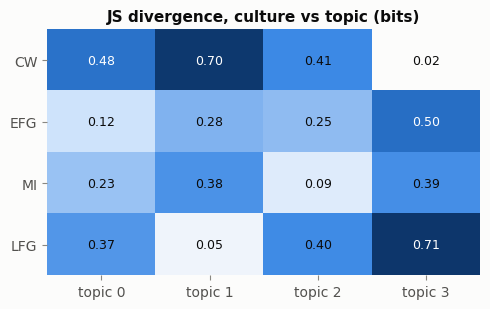

legacy argmin mapping : {'CW': 3, 'EFG': 0, 'MI': 2, 'LFG': 1}
one-to-one mapping    : {'CW': 3, 'EFG': 0, 'MI': 2, 'LFG': 1}


In [13]:
empirical = tm.get_empirical_word_distribution(train_c, vocabulary, BOKS)
legacy_map, J = tm.matching_empirical(empirical, lda_model.topic_word_dist, BOKS, one_to_one=False)  # cell 24
culture_mapping, _ = tm.matching_empirical(empirical, lda_model.topic_word_dist, BOKS)
fig, ax = plt.subplots(figsize=(5, 3.2))
pl.heatmap(ax, J, BOKS, [f"topic {k}" for k in range(4)], fmt="{:.2f}")
ax.set_title("JS divergence, culture vs topic (bits)")
fig.tight_layout(); plt.show()
print("legacy argmin mapping :", legacy_map)
print("one-to-one mapping    :", culture_mapping)


- *Heatmap:* the Jensen–Shannon divergence (bits) between each culture's empirical triplet distribution (rows) and each topic (columns). 0 means identical, 1 means no overlap.
- *Numbers:* each culture has one clearly closest topic: CW–topic 3 (0.02), late FBW–topic 1 (0.05), middle FBW–topic 2 (0.09), early FBW–topic 0 (0.12). The second-closest is at least 0.13 farther. The legacy rule (closest topic per culture) and the one-to-one matching therefore give the same assignment.
- *Caveat:* the legacy rule can give two cultures the same topic (it did in the legacy run). Only one-to-one matching guarantees a classifier that can predict all four BoKs.

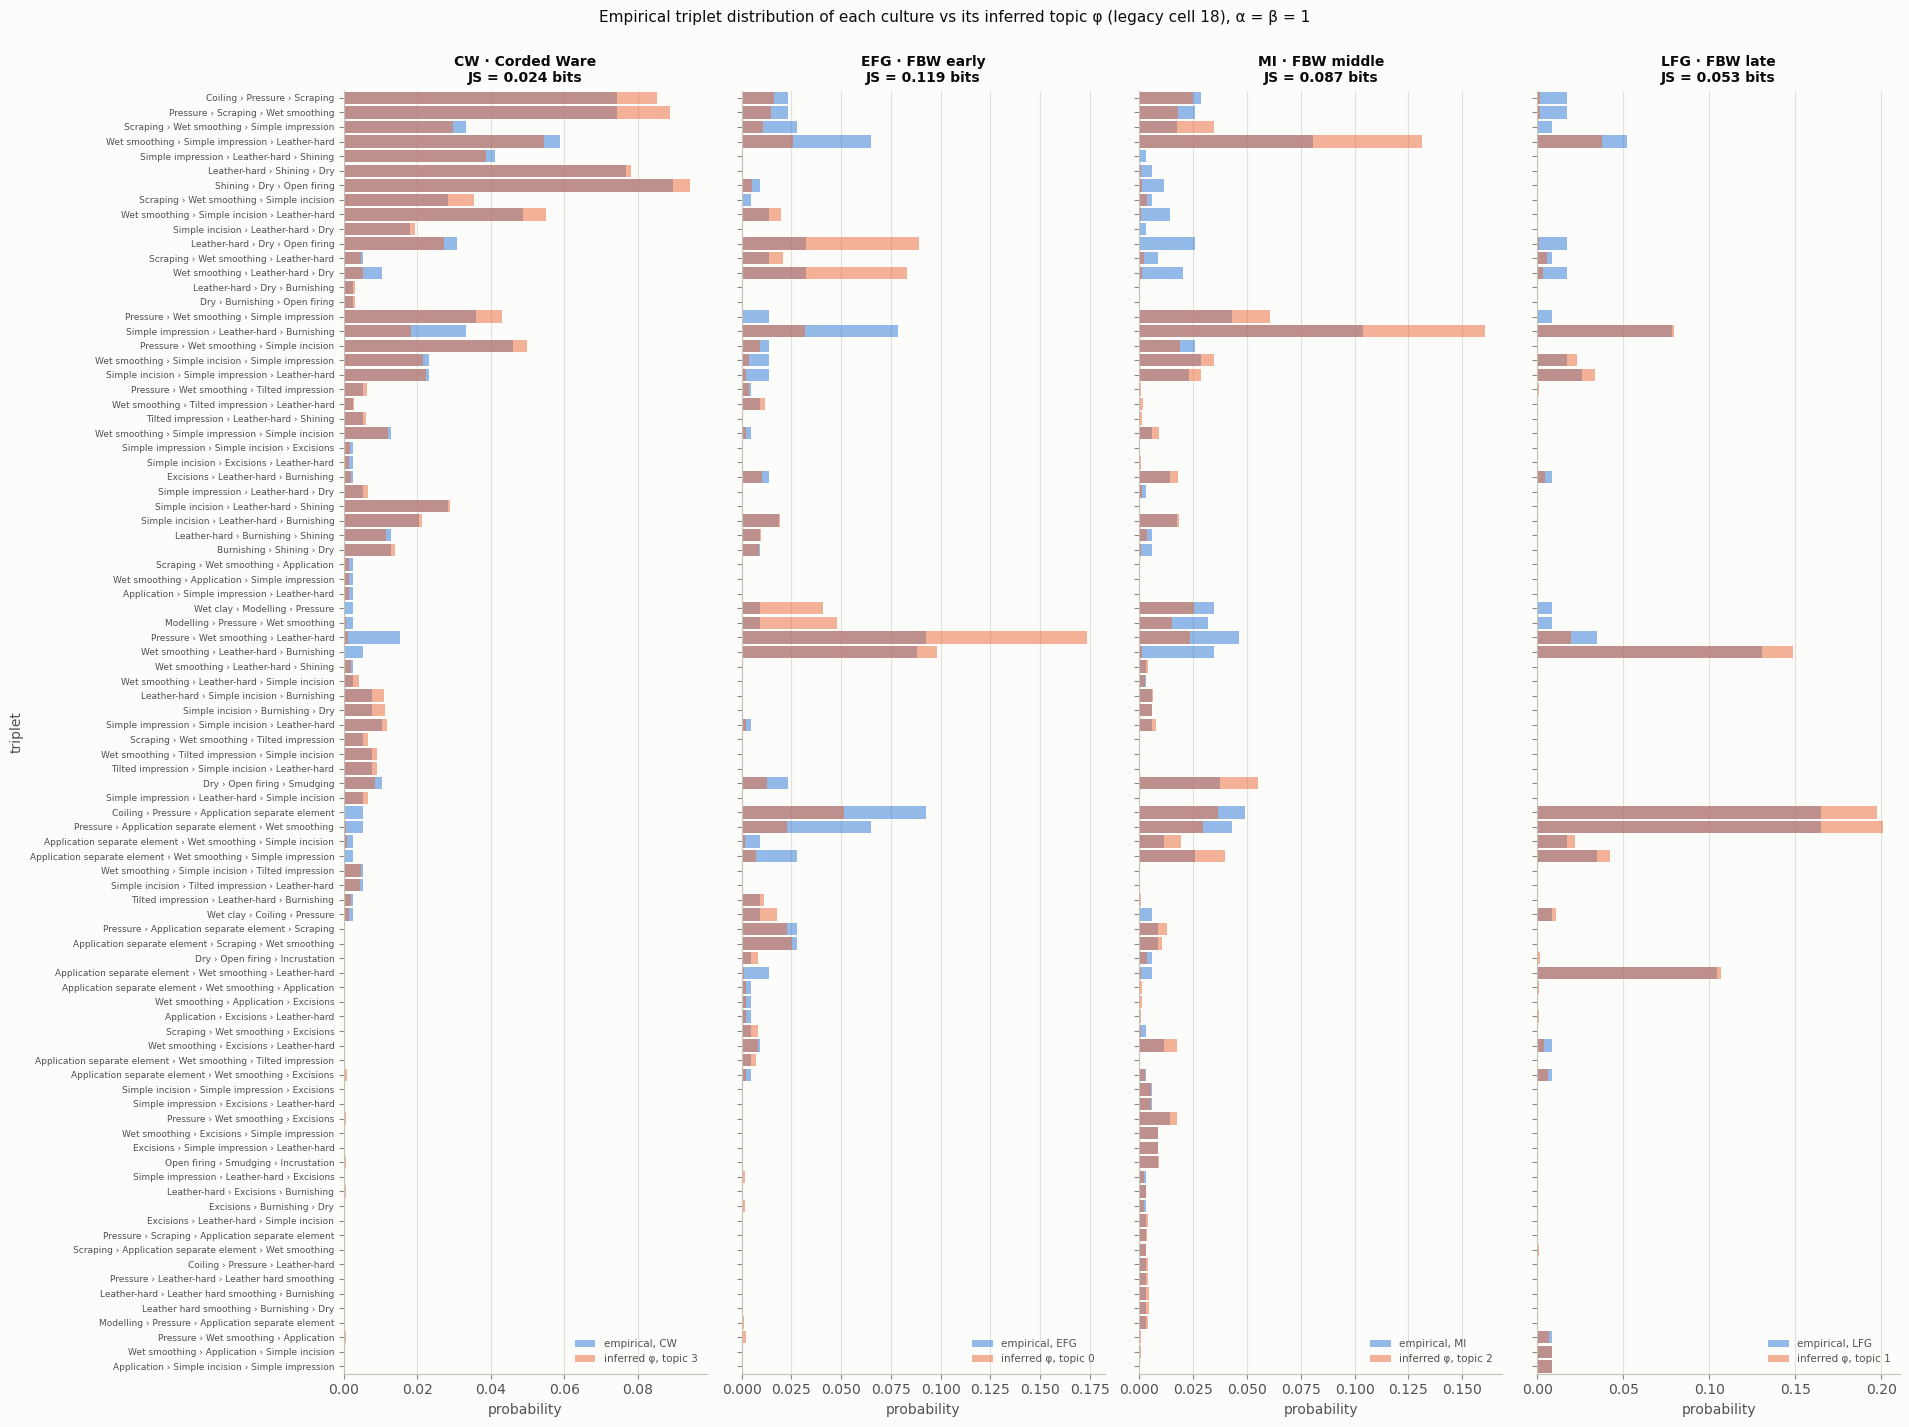

In [14]:
phi_matched = lda_model.topic_word_dist[[culture_mapping[c] for c in BOKS]]
js_matched = [tm.js_divergence(e, m) for e, m in zip(empirical, phi_matched)]
fig = overlay_distributions(empirical, phi_matched, vocabulary, BOKS,
                            [f"inferred φ, topic {culture_mapping[c]}" for c in BOKS],
                            "Empirical triplet distribution of each culture vs its inferred topic φ (legacy cell 18), α = β = 1",
                            js=js_matched)
plt.show()

One topic per culture fits CW and late FBW well (JS ≈ 0.02–0.05 bits) and the early and middle FBW phases worse (≈ 0.09–0.12): their vessels share most techniques, and four topics cannot separate them cleanly.

**The same LDA with α = 0.1 and β = 0.5**, one of the best-fitting settings of the grid in 4.6. A smaller α favours pseudo-documents dominated by a single topic; a smaller β favours topics concentrated on fewer triplets.

In [ ]:
# USING DIFFERENT HYPERPARAMETERS (α = 0.1, β = 0.5) FOR LDA
corpus_mod_a_b = resampled[7]                        # the corpus of Sections 4-6, for LDA and hSBM alike
corpus_culture_mod_a_b = np.array([d["culture"] for d in corpus_mod_a_b])
X_mod_a_b, _ = tm.build_dtm_with_external_vocab(corpus_mod_a_b, vocab_index)                        # legacy cell 6
alph, bet = 0.1, 0.5
lda_model_mod_a_b = tm.LDA_manual(n_topics=4, alpha=alph, beta=bet, n_iter=200, random_state=SEED).fit(X_mod_a_b, vocabulary)  # cells 14, 17
top_mod_a_b = lda_model_mod_a_b.get_top_words(vocabulary, n_words=4)
pd.DataFrame({f"topic {k}": [f"{pl.short(w)}  ({p:.2f})" for w, p in t] for k, t in enumerate(top_mod_a_b)})

,topic 0,topic 1,topic 2,topic 3
0,Pressure › Wet smoothing › Leather-hard (0.09),Coiling › Pressure › Application separate element (0.17),Simple impression › Leather-hard › Burnishing (0.11),Shining › Dry › Open firing (0.09)
1,Coiling › Pressure › Application separate element (0.08),Pressure › Application separate element › Wet smoothing (0.17),Wet smoothing › Simple impression › Leather-hard (0.09),Leather-hard › Shining › Dry (0.08)
2,Wet smoothing › Leather-hard › Burnishing (0.08),Wet smoothing › Leather-hard › Burnishing (0.13),Pressure › Wet smoothing › Simple impression (0.05),Coiling › Pressure › Scraping (0.08)
3,Simple impression › Leather-hard › Burnishing (0.08),Application separate element › Wet smoothing › Leather-hard (0.11),Pressure › Wet smoothing › Leather-hard (0.04),Pressure › Scraping › Wet smoothing (0.08)


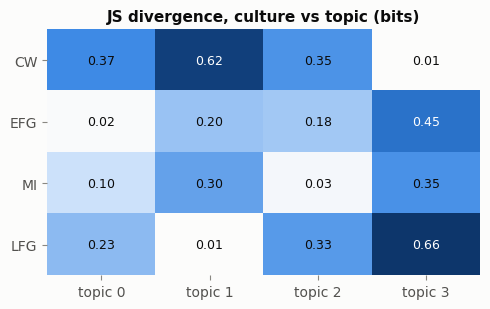

legacy argmin mapping : {'CW': 3, 'EFG': 0, 'MI': 2, 'LFG': 1}
one-to-one mapping    : {'CW': 3, 'EFG': 0, 'MI': 2, 'LFG': 1}


In [ ]:
empirical_mod_a_b = tm.get_empirical_word_distribution(train_c, vocabulary, BOKS)
legacy_map_mod_a_b, J_mod_a_b = tm.matching_empirical(empirical_mod_a_b, lda_model_mod_a_b.topic_word_dist, BOKS, one_to_one=False)  # cell 24
culture_mapping_mod_a_b, _ = tm.matching_empirical(empirical_mod_a_b, lda_model_mod_a_b.topic_word_dist, BOKS)
fig, ax = plt.subplots(figsize=(5, 3.2))
pl.heatmap(ax, J_mod_a_b, BOKS, [f"topic {k}" for k in range(4)], fmt="{:.2f}")
ax.set_title("JS divergence, culture vs topic (bits)")
fig.tight_layout(); plt.show()
print("legacy argmin mapping :", legacy_map_mod_a_b)
print("one-to-one mapping    :", culture_mapping_mod_a_b)

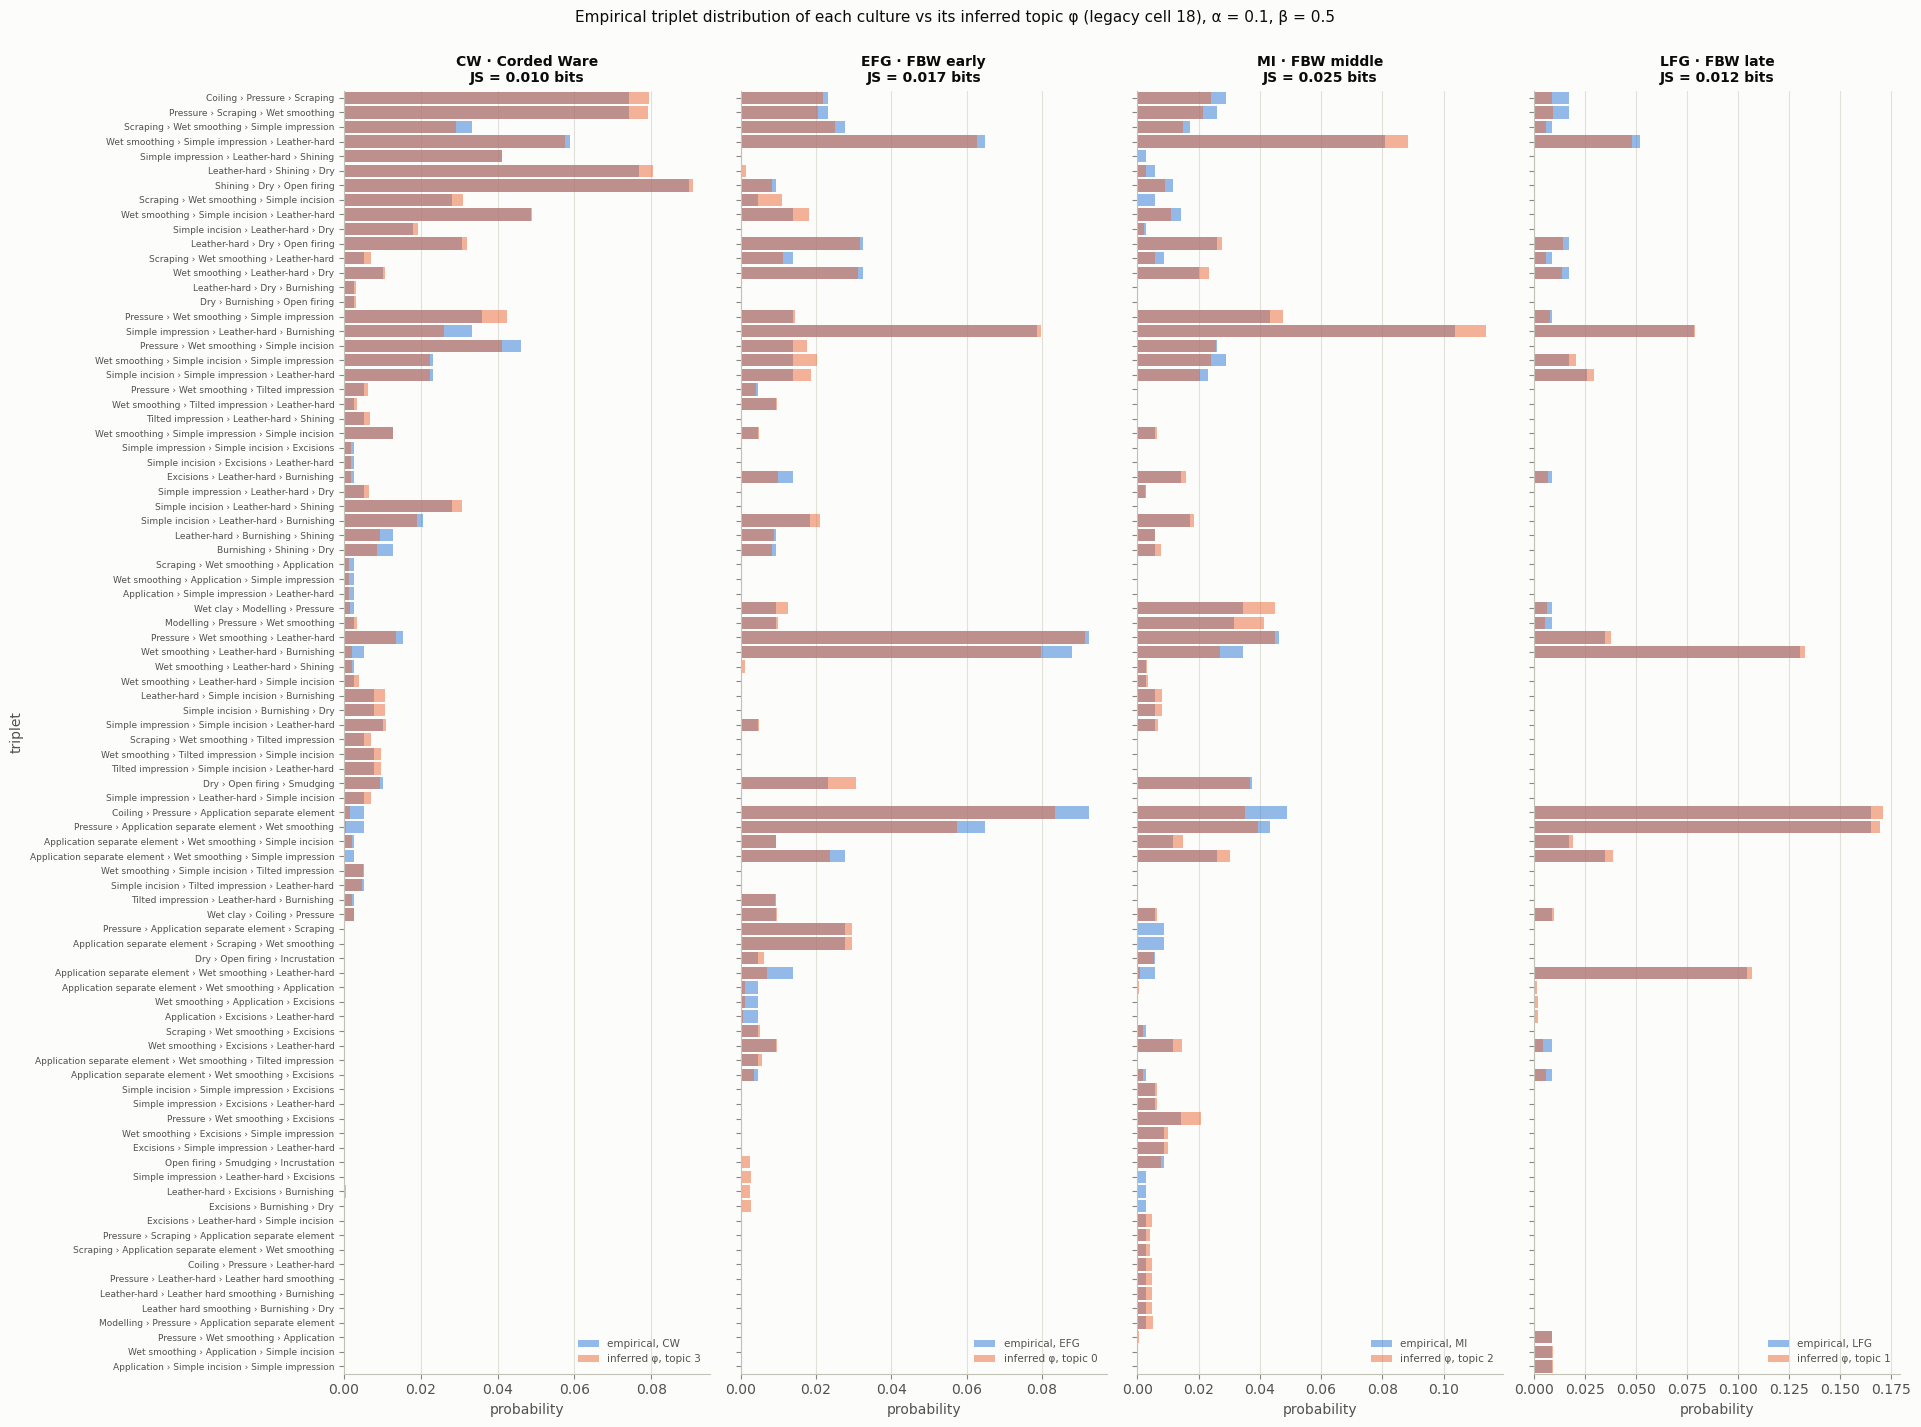

In [ ]:
phi_matched_mod_a_b = lda_model_mod_a_b.topic_word_dist[[culture_mapping_mod_a_b[c] for c in BOKS]]
js_matched_mod_a_b = [tm.js_divergence(e, m) for e, m in zip(empirical_mod_a_b, phi_matched_mod_a_b)]
fig = overlay_distributions(empirical_mod_a_b, phi_matched_mod_a_b, vocabulary, BOKS,
                            [f"inferred φ, topic {culture_mapping_mod_a_b[c]}" for c in BOKS],
                            f"Empirical triplet distribution of each culture vs its inferred topic φ (legacy cell 18), α = {alph}, β = {bet}",
                            js=js_matched_mod_a_b)
plt.show()

**How to read it.** The same corpus and matching as above, with α = 0.1 and β = 0.5 instead of α = β = 1.
- *Top words:* sharper. Topic 1 (late FBW) is dominated by separately applied elements (0.17 each); topic 3 (CW) by shining and scraping.
- *Fit:* each culture's matched topic is 2–7 times closer to its empirical triplet distribution (JS 0.010–0.025 bits, against 0.02–0.12 with α = β = 1), and the one-to-one assignment is unchanged.
- *But a better fit is not a better prediction.* On the held-out sites this setting scores 0.42 against 0.40 (grid of 4.6, 52 vessels, within noise). With a small α each pseudo-document is explained by essentially one topic, so the topics become the average triplet distributions of the four BoKs — exactly what the pooled pseudo-documents were built from.

### 4.4 Topic mixtures of the pseudo-documents
The legacy document–topic heatmap (cell 19): $\theta$ of every pseudo-document (left) and its mean per culture, $p(\text{topic}\mid\text{culture})$ (right); and how well the dominant topic of a pseudo-document recovers its culture (normalised mutual information, NMI: 0 = unrelated, 1 = identical).

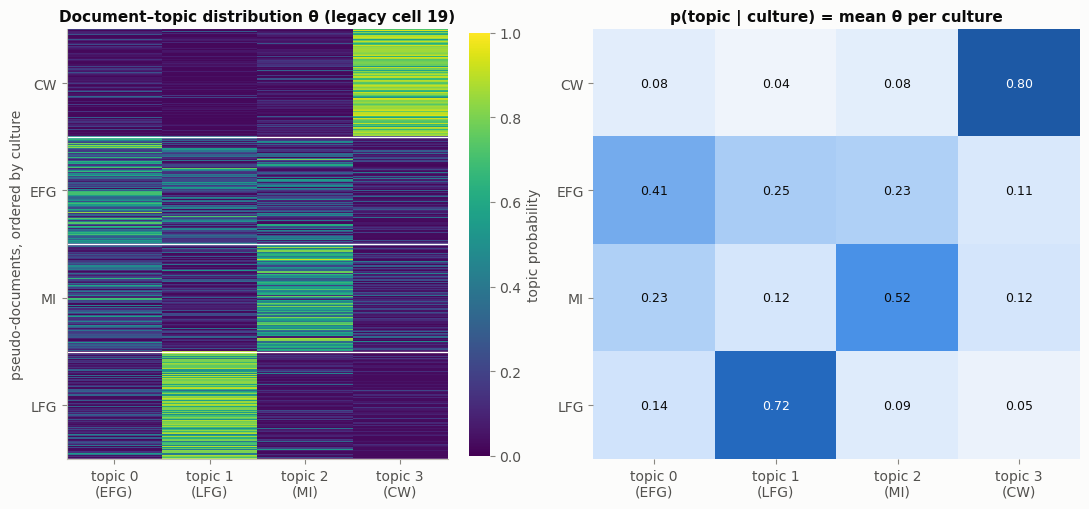

NMI(dominant topic, culture) on the pseudo-documents: 0.64


In [18]:
theta = lda_model.doc_topic_dist
p_topic_culture_lda = np.array([theta[corpus_culture == c].mean(0) for c in BOKS])
topic_names = [f"topic {k}\n({[c for c in BOKS if culture_mapping[c] == k][0]})" for k in range(4)]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [1, 1.15]})
im = axes[0].imshow(theta, aspect="auto", cmap="viridis", vmin=0, vmax=1, interpolation="none")   # legacy cell 19
for c in BOKS:
    axes[0].axhline(np.where(corpus_culture == c)[0].max() + 0.5, color="white", lw=1)
axes[0].set_yticks([np.where(corpus_culture == c)[0].mean() for c in BOKS], BOKS)
axes[0].set_xticks(range(4), topic_names); axes[0].grid(False)
axes[0].set_ylabel("pseudo-documents, ordered by culture"); axes[0].set_title("Document–topic distribution θ (legacy cell 19)")
cb = fig.colorbar(im, ax=axes[0], fraction=0.05); cb.set_label("topic probability"); cb.outline.set_visible(False)
pl.heatmap(axes[1], p_topic_culture_lda, BOKS, topic_names, fmt="{:.2f}", vmin=0, vmax=1)
axes[1].set_title("p(topic | culture) = mean θ per culture")
fig.tight_layout(); plt.show()
nmi_lda = sbm.agreement(theta.argmax(1), corpus_culture)["NMI"]
print(f"NMI(dominant topic, culture) on the pseudo-documents: {nmi_lda:.2f}")


- *Shown:* the topic proportions $\theta_d$ of the 400 pseudo-documents, grouped by culture.
- *NMI:* the normalised mutual information between each document's dominant topic and its culture: 0 when the two partitions are unrelated, 1 when they are identical. At 0.64, the dominant topic usually, but not always, names the culture.
- *Caveat:* these are the training pseudo-documents, built by pooling vessels of one culture. Pooling alone produces NMI ≈ 0.2 even with meaningless labels (7.1).

Each culture's pseudo-documents are dominated by its own topic, but the FBW phases borrow from each other's topics — the same overlap seen above.

### 4.5 Cross-check with gensim
The legacy notebook also fitted gensim's variational LDA (cells 8–10). If both inference algorithms find the same topics on the same corpus, the topics are a property of the data rather than of the sampler.

In [19]:
try:
    from gensim import corpora
    from gensim.models import LdaModel
    dictionary = corpora.Dictionary([d["triplets"] for d in corpus])       # legacy cell 8
    bow = [dictionary.doc2bow(d["triplets"]) for d in corpus]
    gensim_lda = LdaModel(bow, id2word=dictionary, num_topics=4, alpha=1.0, eta=1.0,
                          iterations=1000, passes=20, random_state=SEED)  # legacy cell 9, same priors as above
    phi_gensim = np.zeros((4, len(vocabulary)))
    for k, row in enumerate(gensim_lda.get_topics()):
        for j, p in enumerate(row):
            phi_gensim[k, vocab_index[dictionary[j]]] = p
    pairing, Jg = tm.matching_empirical(lda_model.topic_word_dist, phi_gensim, list(range(4)))
    print("Gibbs topic -> gensim topic:", pairing)
    print("JS between paired topics (bits):", np.round([Jg[k, pairing[k]] for k in range(4)], 3),
          "| smallest JS between unpaired topics:", round(min(Jg[k, j] for k in range(4) for j in range(4) if j != pairing[k]), 3))
except ImportError:
    print("gensim not installed: cross-check skipped")

Gibbs topic -> gensim topic: {0: 3, 1: 2, 2: 1, 3: 0}
JS between paired topics (bits): [0.078 0.014 0.033 0.003] | smallest JS between unpaired topics: 0.272


Paired topics differ by 0.003–0.08 bits while unpaired topics differ by at least 0.27: variational and Gibbs inference find the same four topics.

### 4.6 Hyperparameters: fit criterion vs prediction
The legacy grid (cell 25) scored each $(\alpha,\beta)$ by the JS divergence between each culture and its matched topic (`lda_best_fit`). That criterion is computed on the training corpus; next to it is the accuracy on the held-out sites.

In [20]:
grid = [(0.1, 0.5), (0.1, 1.0), (0.1, 2.0), (0.3, 0.5), (0.5, 1.0), (0.5, 2.0), (1.0, 0.5), (1.0, 1.0), (2.0, 2.0)]
rows = []
for a, b in grid:
    m = tm.LDA_manual(4, a, b, n_iter=100, random_state=SEED).fit(X, vocabulary)
    mapping, Jab = tm.matching_empirical(empirical, m.topic_word_dist, BOKS)
    s = ev.scores(y_test, tm.lda_culture_proba(m, test_c, vocabulary, mapping, BOKS))
    js = [Jab[i, mapping[c]] for i, c in enumerate(BOKS)]
    rows.append({"alpha": a, "beta": b, **{f"JS {c}": x for c, x in zip(BOKS, js)}, "mean JS": np.mean(js),
                 "held-out accuracy": s["accuracy"], "held-out log-loss": s["log_loss"]})
lda_best_fit = pd.DataFrame(rows).set_index(["alpha", "beta"])
lda_best_fit

JS CW  JS EFG  JS MI  JS LFG  mean JS  held-out accuracy  \
alpha beta                                                             
0.1   0.5   0.012   0.025  0.029   0.013    0.020              0.423   
      1.0   0.012   0.022  0.026   0.017    0.019              0.423   
      2.0   0.013   0.031  0.026   0.025    0.024              0.442   
0.3   0.5   0.017   0.039  0.031   0.027    0.029              0.462   
0.5   1.0   0.019   0.041  0.045   0.032    0.034              0.404   
      2.0   0.018   0.058  0.031   0.034    0.035              0.385   
1.0   0.5   0.030   0.143  0.180   0.058    0.103              0.288   
      1.0   0.025   0.086  0.058   0.050    0.055              0.404   
2.0   2.0   0.046   0.188  0.124   0.084    0.111              0.481   

            held-out log-loss  
alpha beta                     
0.1   0.5               1.560  
      1.0               1.596  
      2.0               1.521  
0.3   0.5               1.260  
0.5   1.0               1.319  
      2.0               1.280  
1.0   0.5               1.406  
      1.0               1.275  
2.0   2.0               1.262

The fit criterion prefers small $\alpha$ (mean JS ≈ 0.02 against 0.05–0.11), but held-out accuracy does not follow it. With 52 held-out vessels, differences in accuracy below about ±0.14 (two binomial standard errors) are noise, and the Gibbs sampler adds its own randomness (100 iterations here, 200 in 4.2). An in-sample fit criterion is not a model-selection criterion; Section 7 uses cross-validation instead.

### 4.7 Classifying new vessels
`classify_new_vessel` (legacy cells 28–31) folds a vessel in — its topic mixture $\theta$ with the topics fixed — and returns the culture of its dominant topic. (The legacy version looked the mapping up the wrong way round and always returned "Topic_k".) First a few held-out vessels, then all of them; the pipeline is also run in-sample, as in the legacy notebook.

In [21]:
examples = []
for d in test_c[::10]:
    r = tm.classify_new_vessel(d["triplets"], lda_model, vocabulary, culture_mapping)
    examples.append({"vessel": d["vessel_id"], "true": d["culture"], "predicted": r["predicted_culture"],
                     "max probability": r["max_probability"], "confidence": r["confidence"]})
display(pd.DataFrame(examples).set_index("vessel"))

p_lda = tm.lda_culture_proba(lda_model, test_c, vocabulary, culture_mapping, BOKS)
# the cross-validation pipeline of Section 7 is exactly this procedure:
assert np.allclose(p_lda, clf.LDAPipeline(remove_top=STOP_K, seed=SEED).fit(train_df).predict_proba(test_df))
R.add("LDA", "held-out sites", y_test, p_lda)
R.add("LDA", "in-sample (legacy protocol)", y_bok, clf.LDAPipeline(remove_top=STOP_K, seed=SEED).fit(df).predict_proba(df))
R.table(models=["LDA"])

,true,predicted,max probability,confidence
vessel,,,,
13,CW,CW,0.624,High
150,CW,EFG,0.434,Medium
19,EFG,MI,0.406,Medium
104,MI,LFG,0.380,Low
247,MI,CW,0.393,Low
106,LFG,LFG,0.586,Medium


n  accuracy  balanced_acc  macro_F1  \
model protocol                                                             
LDA   held-out sites                52      0.50         0.525     0.471   
      in-sample (legacy protocol)  276      0.58         0.596     0.566   

                                   log_loss  brier    ECE  
model protocol                                             
LDA   held-out sites                  1.232  0.672  0.141  
      in-sample (legacy protocol)     1.131  0.599  0.086

**How to read it.**
- *First table:* six held-out vessels (every tenth) with the BoK predicted by the legacy `classify_new_vessel`, its probability, and the legacy confidence label (High ≥ 0.6, Medium ≥ 0.4, Low < 0.4). Two of the six are right, and the largest probability is 0.62: LDA rarely commits strongly.
- *Second table:* the same LDA scored on the 52 held-out vessels, and on all 276 vessels it was fitted on, as in the legacy notebook.
- *Evidence:* with 52 vessels, one standard error of accuracy is ≈ 0.07, so 0.50 vs 0.58 is only suggestive on this split. Cross-validation over all vessels gives 0.51 (7.3), confirming the gap.
- *Caveat:* in-sample scores reward memorising the training data. Only held-out scores estimate performance on a new site.

The `assert` above checks that the pipeline used for cross-validation in Section 7 gives exactly these predictions.

## 5 · Topic model II: the hierarchical SBM with sbmtm and graph-tool

**Model** (Gerlach, Peixoto & Altmann 2018). The corpus is a bipartite multigraph: document nodes, word nodes, one edge per occurrence of a word in a document. A nested, degree-corrected stochastic block model partitions document nodes and word nodes into groups, and groups into groups at higher levels. Word groups are the **topics**; a document's share of edges into each word group, $p(t\mid d)$, plays the role of $\theta_d$. The partition $b$ minimises the **description length**
$$S(b) = -\log P(A\mid b) - \log P(b),$$
the number of nats needed to encode the network with the model (Peixoto 2014, 2017). The number of groups at every level is inferred, not fixed as $K$ in LDA.

The fit uses the legacy code `sbmtm.py` (vendored unchanged) on **the same pseudo-documents** as LDA (4.2). Beyond the legacy notebook, graph-tool's inference workflow is completed: several initialisations and a refinement of the partition (5.1), posterior uncertainty of the partition (5.4), the placement of new vessels by description length (5.5), and a test of the overlapping model (7.2).

### 5.1 Fitting: several starts and refinement
`sbmtm.fit` runs `minimize_nested_blockmodel_dl` once and truncates the hierarchy. That gives a good partition but not necessarily the best: graph-tool recommends several initialisations and merge–split MCMC sweeps at zero temperature (Peixoto 2020) to lower the description length further.

In [22]:
if RUN_SBM:
    tokens = [d["triplets"] for d in corpus]
    rows = []
    for s in range(3):
        m = sbm.fit_hsbm(tokens, seed=s)                 # sbmtm: make_graph(counts=True) + fit(overlap=False)
        before, after = sbm.refine(m, sweeps=50)         # merge-split sweeps at beta = inf
        rows.append({"seed": s, "S after sbmtm.fit (nats)": before, "S after refinement (nats)": after,
                     **{f"level {h['level']}": f"{h['doc_groups']} doc / {h['word_groups']} word groups"
                        for h in sbm.hierarchy(m) if h["doc_groups"] > 1}})
        if s == SEED:
            hsbm = m
    g = hsbm.g
    print(f"network: {hsbm.get_D()} document nodes, {hsbm.get_V()} word nodes, "
          f"{g.num_edges()} distinct edges, {int(g.ep['count'].a.sum())} tokens")
    display(pd.DataFrame(rows).set_index("seed"))

network: 400 document nodes, 88 word nodes, 7344 distinct edges, 12958 tokens


,S after sbmtm.fit (nats),S after refinement (nats),level 0,level 1
seed,,,,
0,17609.134,17404.837,11 doc / 26 word groups,4 doc / 5 word groups
1,17789.090,17532.998,4 doc / 23 word groups,NaN
2,17775.701,17533.144,4 doc / 23 word groups,NaN


Refinement lowers the description length by 200–260 nats for every start, and the starts disagree on the finer levels (seed 0 finds 11 document groups at level 0 and 4 at level 1; seeds 1 and 2 find 4 at level 0). A single call of `sbmtm.fit` should not be read as *the* partition. Seed 0 has the lowest description length and is used below — the same model the cross-validation pipeline builds. The standard hierarchy plot of Gerlach et al. (`sbmtm.plot`, graph-tool's `draw_hierarchy`), pseudo-documents on one side, triplets on the other, groups of groups in the middle:

l: 0, N: 488, B: 37
l: 1, N: 37, B: 9
l: 2, N: 9, B: 2
l: 3, N: 2, B: 2
l: 4, N: 2, B: 1


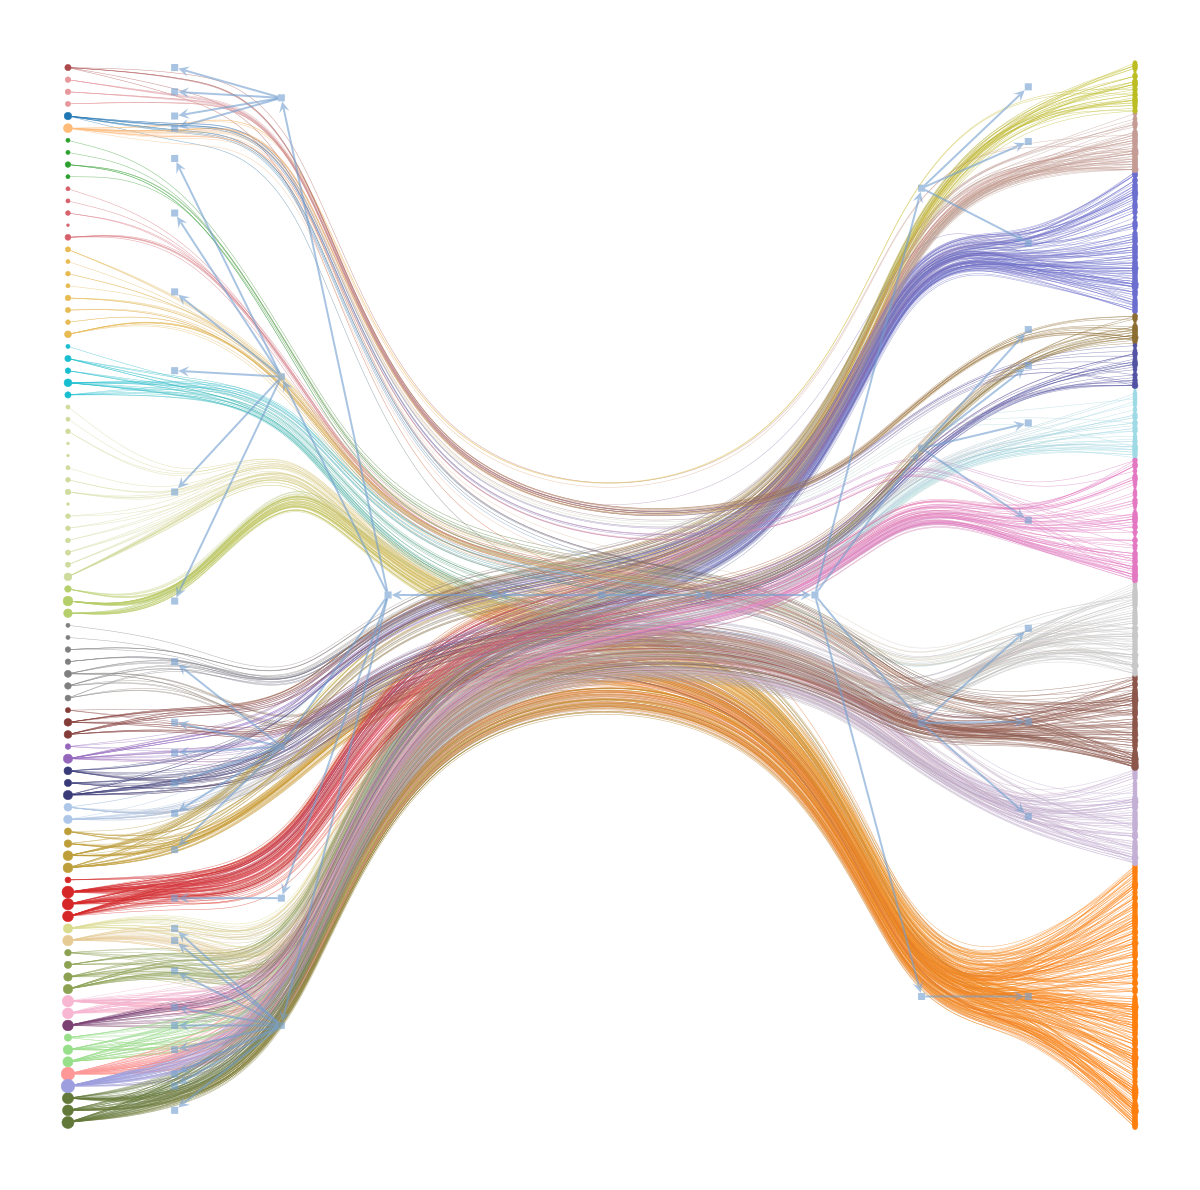

In [23]:
if RUN_SBM:
    hsbm.print_summary()
    path = ROOT / "figures" / "hsbm_hierarchy.png"
    hsbm.plot(filename=str(path), nedges=1000)
    display(Image(filename=str(path), width=520))

**How to read it.**
- *Printed lines:* graph-tool's summary of the nested partition: at level $l$, $N$ nodes are grouped into $B$ groups. On the LEFT the triplets on the RIGHT the resampled documents.

  - Level 0: the 488 nodes (400 pseudo-documents + 88 triplets) form 37 groups (11 document groups + 26 topics).
  - Level 1 groups these 37 into 9 (4 + 5).
  - Level 2 groups those into 2 — documents and triplets, which never mix — and the top level joins the two.
- *Figure:* the same tree, with pseudo-documents on one side, triplets on the other and the nested groups in between.

### 5.2 Document groups and cultures, level by level
The legacy notebook counted cultures per document cluster at level 0 (cell 49). Contingency tables and agreement with the cultures at every level of the hierarchy:

In [24]:
if RUN_SBM:
    rows, tables = [], {}
    for h in sbm.hierarchy(hsbm):
        if h["doc_groups"] == 1:
            continue
        part = sbm.doc_partition(hsbm, h["level"])
        tables[h["level"]] = pd.crosstab(pd.Series(part, name=f"group, level {h['level']}"),
                                         pd.Series(corpus_culture, name="culture"))[BOKS]
        rows.append({**h, **sbm.agreement(part, corpus_culture)})
    display(pd.DataFrame(rows).set_index("level"))
    for level, table in tables.items():
        display(table.T)

,doc_groups,word_groups,NMI,ARI
level,,,,
0,11,26,0.716,0.582
1,4,5,0.922,0.930


"group, level 0",0,1,2,3,4,5,6,7,8,9,10
culture,,,,,,,,,,,
CW,99,1,0,0,0,0,0,0,0,0,0
EFG,0,17,53,22,6,1,1,0,0,0,0
MI,0,1,1,0,30,34,34,0,0,0,0
LFG,0,0,0,0,0,0,0,16,46,27,11


"group, level 1",0,1,2,3
culture,,,,
CW,99,1,0,0
EFG,0,92,8,0
MI,0,2,98,0
LFG,0,0,0,100


**How to read it.**
- *First table:* the agreement between document groups and cultures at each level: NMI (4.4) and the adjusted Rand index ARI (0 = chance agreement, 1 = identical partitions).
- *Contingency tables:* rows are cultures, columns are document groups; entries count pseudo-documents (100 per culture).
- *Numbers:*
  - At level 1, CW, middle FBW and late FBW are 98–100 % in their own group, and early FBW 92 % (8 of its documents sit in the middle-FBW group): ARI 0.93.
  - At level 0, CW stays whole while each FBW phase splits into 3–4 sub-groups (early FBW 17 / 53 / 22 / 6).
- *Caveat:* these are pseudo-documents of known culture. Part of the separation is produced by the pooling (7.1).

The pseudo-documents separate almost perfectly by culture, reproducing the legacy observation that "the documents are nicely separated between cultures". Section 7.1 measures how much of this separation the pooling produces by itself.

### 5.3 Topics and what the cultures share
`sbmtm.topics` lists the most probable triplets of each word group, $p(w\mid t)$. Averaging the documents' topic mixtures gives each culture's topic weights $p(t\mid c)$, and $p(w\mid c)=\sum_t p(w\mid t)\,p(t\mid c)$ is the model's triplet distribution for the culture. This replaces legacy cells 64–69 ("combination of topics"), which averaged rows of the group *membership* $p(t\mid w)$ — for a non-overlapping SBM 0/1 indicators — against a binarised empirical matrix, i.e. compared sets of words rather than distributions.

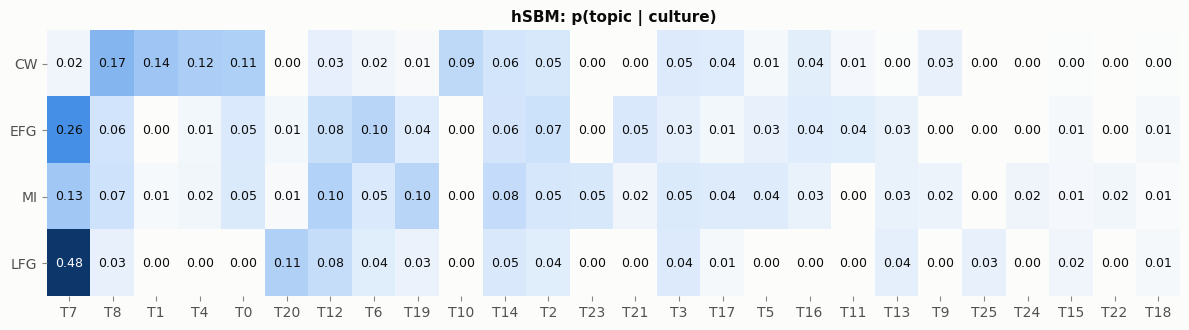

,most probable triplets,specificity (max / mean over cultures),most used by
topic,,,
T7,Coiling › Pressure › Application separate element | Pressure › Application separate element › Wet smoothing,2.166,LFG
T8,Coiling › Pressure › Scraping | Pressure › Scraping › Wet smoothing,2.079,CW
T1,Leather-hard › Shining › Dry | Simple impression › Leather-hard › Shining,3.760,CW
T4,Shining › Dry › Open firing | Scraping › Wet smoothing › Simple incision,3.180,CW
T0,Pressure › Wet smoothing › Simple incision | Wet smoothing › Simple incision › Leather-hard,2.141,CW
T20,Application separate element › Wet smoothing › Leather-hard,3.343,LFG
T12,Simple impression › Leather-hard › Burnishing,1.438,MI
T6,Pressure › Wet smoothing › Leather-hard,1.908,EFG
T19,Wet clay › Modelling › Pressure | Modelling › Pressure › Wet smoothing,2.272,MI


In [64]:
if RUN_SBM:
    topics = hsbm.topics(l=0, n=2)                                  # sbmtm
    p_t_c, p_w_c_hsbm = sbm.culture_topic_mixture(hsbm, corpus_culture, BOKS)
    order = np.argsort(-p_t_c.max(0))
    fig, ax = plt.subplots(figsize=(12, 3.4))
    pl.heatmap(ax, p_t_c[:, order], BOKS, [f"T{k}" for k in order], fmt="{:.2f}", vmin=0)
    ax.set_title("hSBM: p(topic | culture)"); fig.tight_layout(); plt.show()
    display(pd.DataFrame({
        "topic": [f"T{k}" for k in order],
        "most probable triplets": [" | ".join(pl.short(w) for w, _ in topics[k]) for k in order],
        "specificity (max / mean over cultures)": (p_t_c.max(0) / p_t_c.mean(0))[order],
        "most used by": [BOKS[i] for i in p_t_c[:, order].argmax(0)],
    }).set_index("topic"))

**How to read it.**
- *Heatmap:* $p(\text{topic}\mid\text{culture})$, how much of each culture's triplet use goes to each of the 26 hSBM topics. Columns are sorted by their largest entry.
- *Table:* for each topic:
  - its most probable triplets;
  - its *specificity*, the largest $p(\text{topic}\mid\text{culture})$ divided by its mean over the four cultures: 1 for a topic used equally by all, 4 for a topic used by one culture only;
  - the culture that uses it most.
- *Numbers:* five topics are used by one culture only (specificity 4.0): incision → shining (T10, CW), excisions (T22, T23) and smudging → incrustation (T24) in middle FBW, and applied decoration (T25) in late FBW. The topics with the largest shares are moderately specific (≈ 2): handles (T7, late FBW) and scraping (T8, CW).
- *Caveat:* a highly specific small topic rests on few triplets and few vessels.

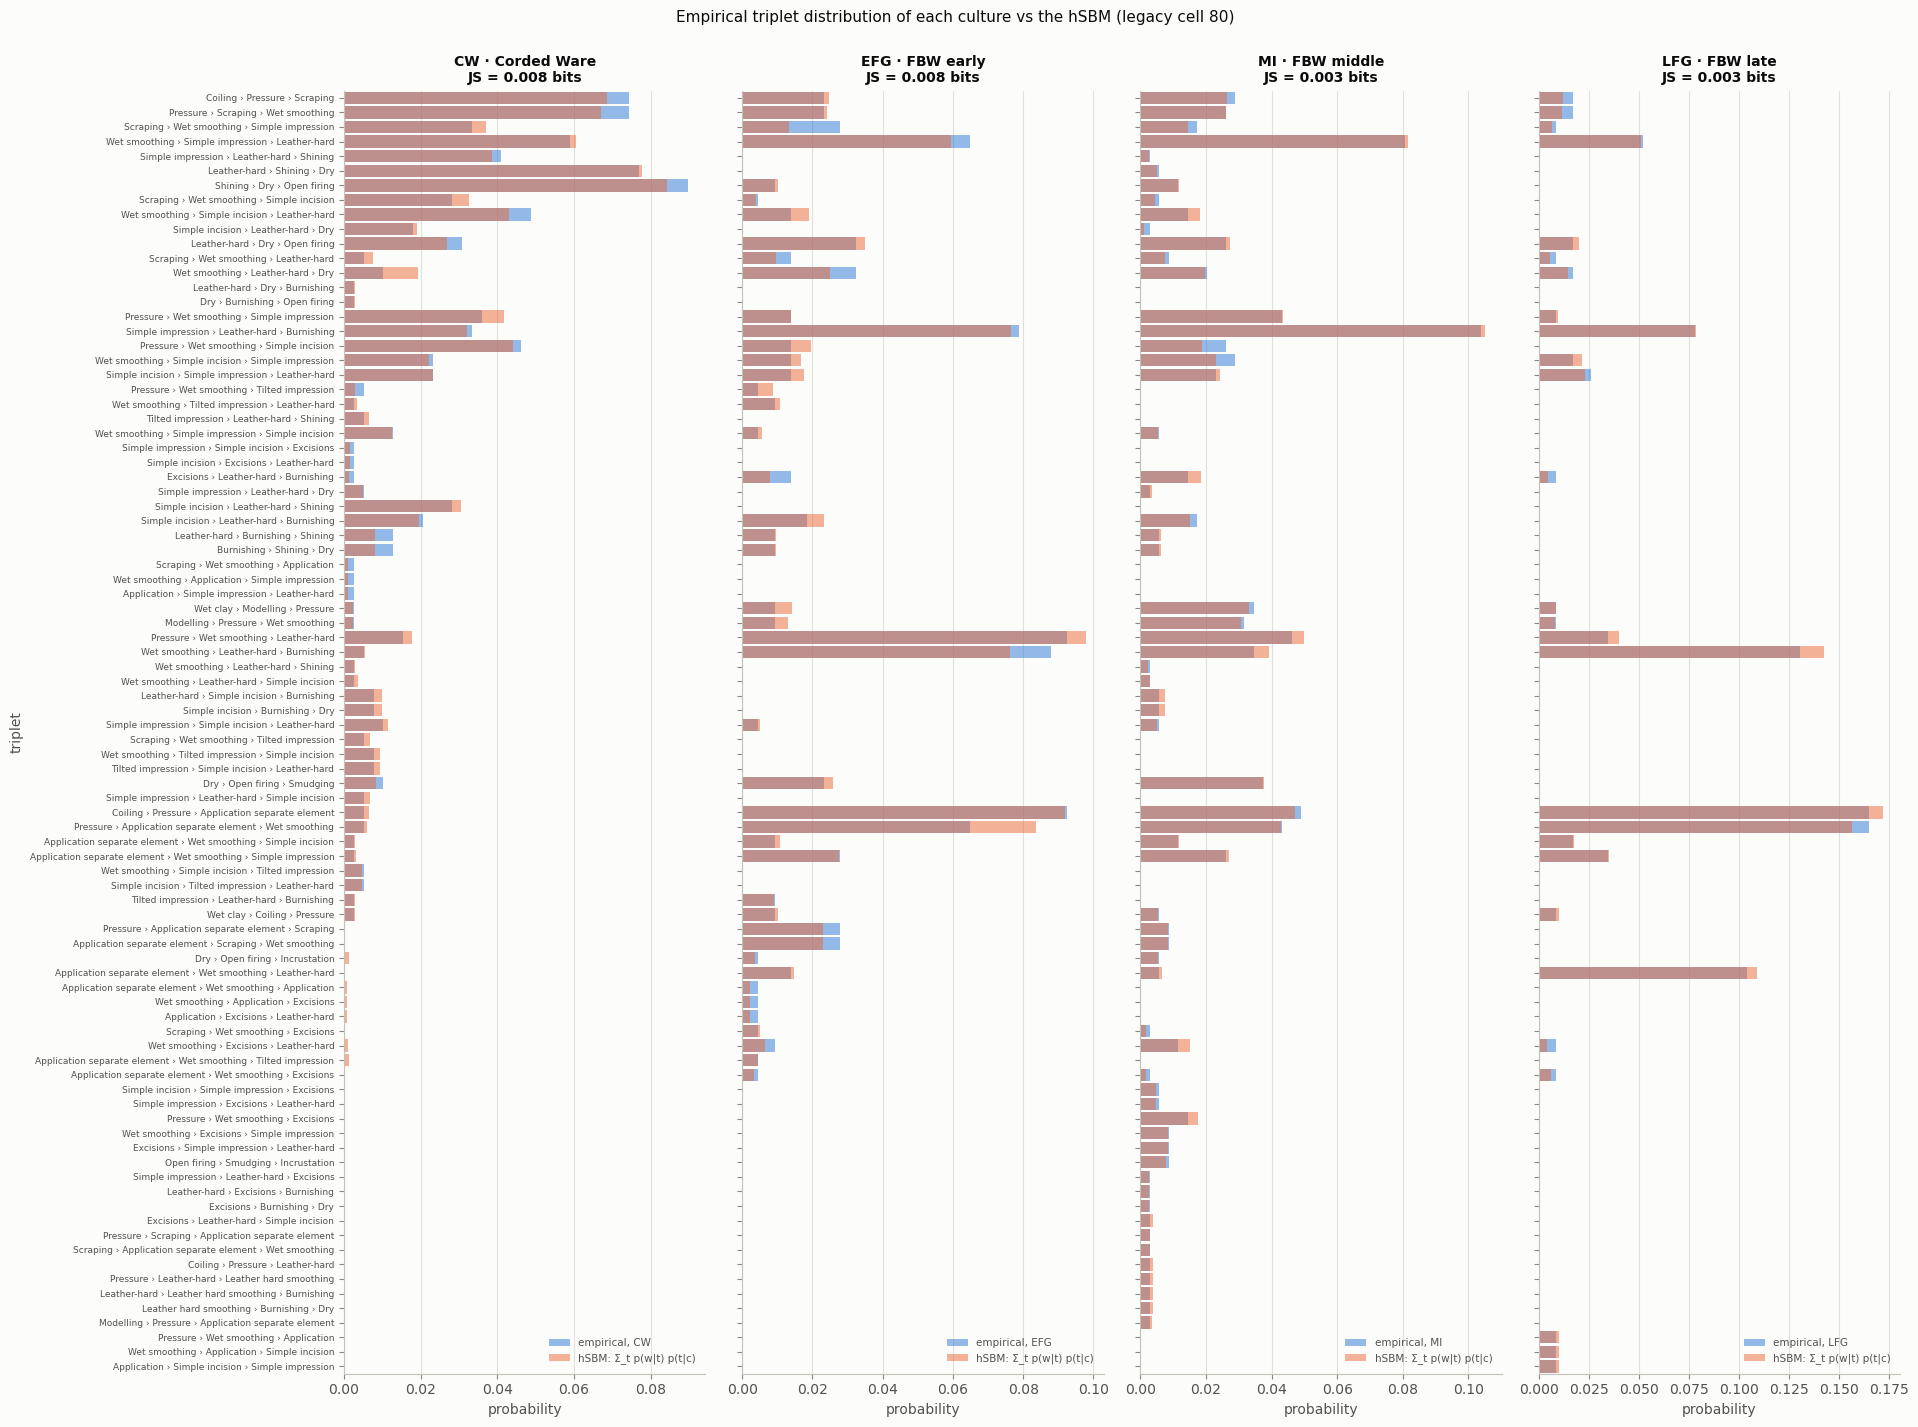

In [26]:
if RUN_SBM:
    position = {w: i for i, w in enumerate(hsbm.words)}
    p_w_c_sbm = np.zeros((len(BOKS), len(vocabulary)))
    for j, w in enumerate(vocabulary):
        if w in position:
            p_w_c_sbm[:, j] = p_w_c_hsbm[:, position[w]]
    js_sbm = [tm.js_divergence(e, m) for e, m in zip(empirical, p_w_c_sbm)]
    fig = overlay_distributions(empirical, p_w_c_sbm, vocabulary, BOKS, ["hSBM: Σ_t p(w|t) p(t|c)"] * len(BOKS),
                                "Empirical triplet distribution of each culture vs the hSBM (legacy cell 80)", js=js_sbm)
    plt.show()

With 26 topics the hSBM reproduces each culture's triplet distribution closely (mean JS ≈ 0.006 bits, against 0.042 for LDA's four topics; Section 6), at the price of many more parameters. Shared and specific topics: separately applied elements (handles, knobs) are FBW-wide and dominate the late phase; scraping, shining and simple incision are CW-specific; the simple impression → burnishing topic is shared by the three FBW phases (the pure burnishing triplets were removed as stop triplets in 4.1).

### 5.4 How certain is the partition? Posterior sampling
A single partition hides its uncertainty. graph-tool samples the posterior $P(b\mid A)\propto e^{-S(b)}$ by MCMC (`mcmc_equilibrate`) and aligns the group labels of the samples (`PartitionModeState`, Peixoto 2021). The marginal probability of each group for each node is the proper "soft membership" of a non-overlapping SBM — uncertainty about a node's group, not mixed membership (which is what the overlapping model of legacy cell 36 is about; see 7.2).

200 posterior samples: description length 17417 ± 15 nats; posterior entropy of the partition 100.0 nats
nodes whose group is uncertain (max marginal < 0.9): 91 of 400 pseudo-documents, 20 of 88 triplets


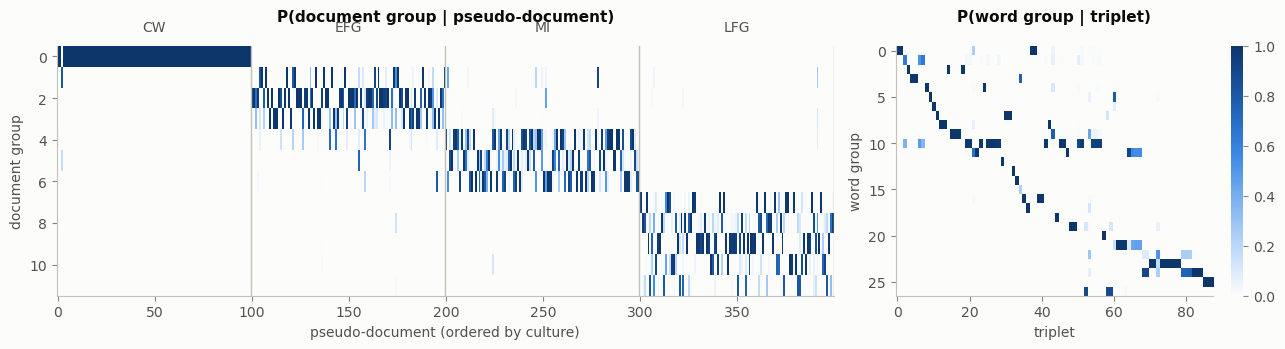

In [27]:
if RUN_SBM:
    pmode, dl = sbm.sample_partitions(hsbm, n_samples=200)
    doc_marg, word_marg = sbm.posterior_marginals(hsbm, pmode)
    print(f"200 posterior samples: description length {dl.mean():.0f} ± {dl.std():.0f} nats; "
          f"posterior entropy of the partition {pmode.posterior_entropy():.1f} nats")
    print(f"nodes whose group is uncertain (max marginal < 0.9): {(doc_marg.max(1) < 0.9).sum()} of "
          f"{len(doc_marg)} pseudo-documents, {(word_marg.max(1) < 0.9).sum()} of {len(word_marg)} triplets")
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
    axes[0].imshow(doc_marg.T, aspect="auto", cmap=pl.SEQ, vmin=0, vmax=1, interpolation="none")
    for c in BOKS:
        idx = np.where(corpus_culture == c)[0]
        axes[0].axvline(idx.max() + 0.5, color=pl.INK["axis"], lw=1)
        axes[0].text(idx.mean(), -1.2, c, ha="center", color=pl.INK["secondary"])
    axes[0].set_xlabel("pseudo-document (ordered by culture)"); axes[0].set_ylabel("document group")
    axes[0].set_title("P(document group | pseudo-document)", pad=18); axes[0].grid(False)
    im = axes[1].imshow(word_marg.T, aspect="auto", cmap=pl.SEQ, vmin=0, vmax=1, interpolation="none")
    axes[1].set_xlabel("triplet"); axes[1].set_ylabel("word group"); axes[1].set_title("P(word group | triplet)", pad=18)
    axes[1].grid(False); fig.colorbar(im, ax=axes[1], fraction=0.05).outline.set_visible(False)
    fig.tight_layout(); plt.show()

**How to read it.**
- *Numbers:*
  - 200 partitions sampled from the posterior have description lengths of 17417 ± 15 nats, close to the refined optimum (17405 nats, 5.1): the optimum is a typical partition, not an outlier.
  - The posterior entropy of 100 nats means that about $e^{100}$ partitions are plausible, almost all differing only in where a few nodes go.
  - 91 of the 400 pseudo-documents and 20 of the 88 triplets have no group with marginal probability ≥ 0.9.
- *Figure:* each column is a node and each row a group; dark means probability near 1.

The uncertain pseudo-documents move between the level-0 sub-groups *of their own culture*: the culture-level structure is certain, its subdivision is not. The words are almost all firmly assigned to one topic.

### 5.5 Classifying new vessels: two ways
**(a) Legacy cluster classifier** (cells 77, 84): name each document cluster after its majority culture (`compute_word_cluster_matrix`), score a new vessel by the likelihood of its triplets under each cluster (`classify_vessel_simple`).

**(b) Fold-in by description length** — the corrected version of the legacy `infer_new_doc_membership` (cell 86, never run): add the vessel as a new document node with its triplet edges, keep every other node's group fixed, and compute the description length $S_r$ of the whole hierarchy with the new node in each document group $r$. Then
$$P(r\mid\text{vessel}) \propto e^{-(S_r-\min_r S_r)},\qquad p(\text{culture}\mid\text{vessel})=\sum_r P(r\mid\text{vessel})\,p(\text{culture}\mid r).$$
This is the conditional posterior graph-tool's own MCMC samples from, so the classifier uses the fitted model itself rather than a word-count summary of it.

In [28]:
if RUN_SBM:
    test_tokens = [d["triplets"] for d in test_c]
    sbm_nb = sbm.SBMClassifier().fit(tokens, list(corpus_culture), BOKS, model=hsbm)
    print("document clusters (legacy naming):", sbm_nb.names)
    sbm_fi = sbm.SBMFoldInClassifier().fit(tokens, list(corpus_culture), BOKS, model=hsbm)
    dS, groups = next(sbm._fold_in_delta_s(hsbm, test_tokens[:1]))      # example: first held-out vessel
    P = np.exp(-(dS - dS.min())); P /= P.sum()
    print(f"\nvessel {test_c[0]['vessel_id']} (true: {test_c[0]['culture']}), four most probable groups:")
    display(pd.DataFrame({"S_r - min S (nats)": dS - dS.min(), "P(r | vessel)": P,
                          **{f"p({c} | r)": sbm_fi.p_class_given_group[:, i] for i, c in enumerate(BOKS)}},
                         index=[f"group {r}" for r in groups]).sort_values("P(r | vessel)", ascending=False).head(4))

document clusters (legacy naming): ['CW (C0, 99/99)', 'EFG (C1, 17/19)', 'EFG (C2, 53/54)', 'EFG (C3, 22/22)', 'MI (C4, 30/36)', 'MI (C5, 34/35)', 'MI (C6, 34/35)', 'LFG (C7, 16/16)', 'LFG (C8, 46/46)', 'LFG (C9, 27/27)', 'LFG (C10, 11/11)']

vessel 13 (true: CW), four most probable groups:


,S_r - min S (nats),P(r | vessel),p(CW | r),p(EFG | r),p(MI | r),p(LFG | r)
group 25,0.000,9.990e-01,1.0,0.000,0.000,0.0
group 134,7.778,4.183e-04,0.0,0.029,0.971,0.0
group 122,8.060,3.155e-04,0.0,0.167,0.833,0.0
group 232,8.451,2.134e-04,0.0,0.029,0.971,0.0


**How to read it.**
- *First line:* the 11 level-0 document groups, named by their majority culture (count of that culture / group size).
- *Table:* for one held-out CW vessel, the four cheapest document groups to place it in. Columns:
  - the extra description length of placing it there, $S_r-\min S$ (nats);
  - the resulting probability $P(r\mid\text{vessel})\propto e^{-(S_r-\min S)}$;
  - the culture composition $p(c\mid r)$ of the group.

  The attribution is $\sum_r P(r\mid\text{vessel})\,p(c\mid r)$.
- *Numbers:* a 7.8-nat gap means odds of $e^{7.8}\approx2400$ to 1 for the cheapest group.

The CW vessel is placed in the CW group with probability 0.999; the next groups cost at least 7.8 nats more. Such sharp posteriors are typical — every token moves the description length by several nats — and they are one source of the over-confidence measured below.

In [29]:
if RUN_SBM:
    p_nb, p_fi = sbm_nb.predict_proba(test_tokens), sbm_fi.predict_proba(test_tokens)
    # the cross-validation pipelines of Section 7 are exactly these procedures:
    assert np.allclose(p_fi, clf.SBMPipeline("fold-in", remove_top=STOP_K, seed=SEED).fit(train_df).predict_proba(test_df))
    assert np.allclose(p_nb, clf.SBMPipeline("clusters", remove_top=STOP_K, seed=SEED).fit(train_df).predict_proba(test_df))
    R.add("hSBM, cluster classifier", "held-out sites", y_test, p_nb)
    R.add("hSBM, fold-in", "held-out sites", y_test, p_fi)
    for method, name in [("clusters", "hSBM, cluster classifier"), ("fold-in", "hSBM, fold-in")]:
        R.add(name, "in-sample (legacy protocol)", y_bok,
              clf.SBMPipeline(method, remove_top=STOP_K, seed=SEED).fit(df).predict_proba(df))
    display(R.table(models=["hSBM, cluster classifier", "hSBM, fold-in"]))

n  accuracy  \
model                    protocol                                     
hSBM, cluster classifier held-out sites                52     0.481   
                         in-sample (legacy protocol)  276     0.587   
hSBM, fold-in            held-out sites                52     0.538   
                         in-sample (legacy protocol)  276     0.638   

                                                      balanced_acc  macro_F1  \
model                    protocol                                              
hSBM, cluster classifier held-out sites                      0.544     0.471   
                         in-sample (legacy protocol)         0.587     0.595   
hSBM, fold-in            held-out sites                      0.571     0.525   
                         in-sample (legacy protocol)         0.651     0.632   

                                                      log_loss  brier    ECE  
model                    protocol                                             
hSBM, cluster classifier held-out sites                  2.072  0.734  0.270  
                         in-sample (legacy protocol)     1.051  0.511  0.145  
hSBM, fold-in            held-out sites                  1.552  0.708  0.236  
                         in-sample (legacy protocol)     0.872  0.461  0.064

**How to read it.**
- *Shown:* the two hSBM classifiers on the 52 held-out vessels and in-sample.
- *Evidence:* one standard error on 52 vessels is ≈ 0.07, so 0.48 vs 0.54 on this split is not a real difference. Under cross-validation the two coincide (0.52, 7.3).
- *Caveat:* held out, the ECE is 0.24–0.27 and the log-loss 1.6–2.1: probabilities near 1 are often wrong.

On the held-out sites the fold-in classifier scores 0.54 and the legacy cluster classifier 0.48; in-sample (legacy protocol) 0.64 and 0.59 — the fold-in reproduces the legacy in-sample figure of 0.65. Both `assert` lines check that the cross-validation pipelines give exactly these predictions.

## 6 · LDA vs hSBM on the same corpus and the same held-out sites

,LDA,"hSBM, cluster classifier","hSBM, fold-in"
number of topics,4 (fixed),"26 (inferred, level 0)","26 (inferred, level 0)"
document groups,none (mixtures),11 (level 0),11 (level 0)
"NMI(pseudo-document clusters, culture)",0.641,0.716,0.716
"mean JS, model vs empirical p(w | c) (bits)",0.042,0.006,0.006
held-out accuracy,0.5,0.481,0.538
held-out balanced accuracy,0.525,0.544,0.571
held-out log-loss,1.232,2.072,1.552
in-sample accuracy (legacy protocol),0.58,0.587,0.638


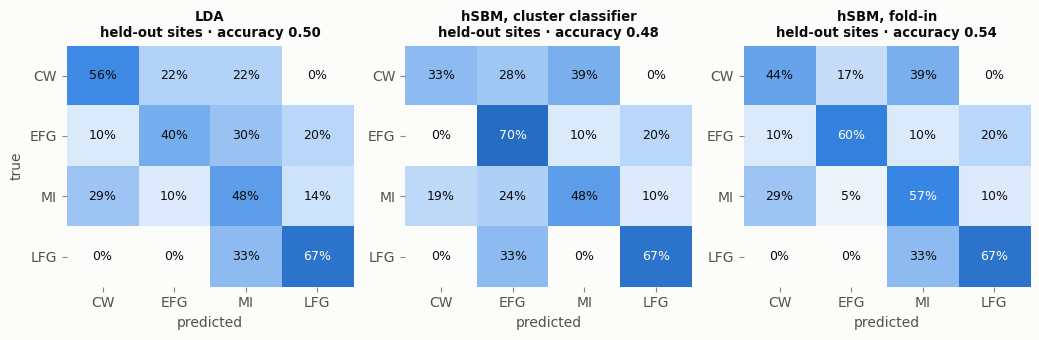

In [30]:
topic_models = ["LDA"] + (["hSBM, cluster classifier", "hSBM, fold-in"] if RUN_SBM else [])
held, insample = R.table("held-out sites"), R.table("in-sample (legacy protocol)")
lda_mix = p_topic_culture_lda @ lda_model.topic_word_dist                  # LDA's Σ_k p(w|k) p(k|c)
comparison = {"LDA": {
    "number of topics": "4 (fixed)", "document groups": "none (mixtures)",
    "NMI(pseudo-document clusters, culture)": nmi_lda,
    "mean JS, model vs empirical p(w | c) (bits)": np.mean([tm.js_divergence(e, m) for e, m in zip(empirical, lda_mix)]),
    "held-out accuracy": held.loc[("LDA", "held-out sites"), "accuracy"],
    "held-out balanced accuracy": held.loc[("LDA", "held-out sites"), "balanced_acc"],
    "held-out log-loss": held.loc[("LDA", "held-out sites"), "log_loss"],
    "in-sample accuracy (legacy protocol)": insample.loc[("LDA", "in-sample (legacy protocol)"), "accuracy"]}}
if RUN_SBM:
    h0 = sbm.hierarchy(hsbm)[0]
    for name in topic_models[1:]:
        comparison[name] = {
            "number of topics": f"{h0['word_groups']} (inferred, level 0)",
            "document groups": f"{h0['doc_groups']} (level 0)",
            "NMI(pseudo-document clusters, culture)": sbm.agreement(sbm.doc_partition(hsbm), corpus_culture)["NMI"],
            "mean JS, model vs empirical p(w | c) (bits)": np.mean(js_sbm),
            "held-out accuracy": held.loc[(name, "held-out sites"), "accuracy"],
            "held-out balanced accuracy": held.loc[(name, "held-out sites"), "balanced_acc"],
            "held-out log-loss": held.loc[(name, "held-out sites"), "log_loss"],
            "in-sample accuracy (legacy protocol)": insample.loc[(name, "in-sample (legacy protocol)"), "accuracy"]}
display(pd.DataFrame(comparison))
fig = pl.confusion_panel(R, [(m, "held-out sites") for m in topic_models]); plt.show()

On the same corpus and the same test vessels:
- **Structure.** The hSBM infers 26 topics and 11 document groups (4 at level 1) where LDA is given 4 topics; its document clusters match the cultures better (NMI 0.72, and 0.92 at level 1, against 0.64), and its implied triplet distributions are much closer to the empirical ones (JS 0.006 vs 0.042 bits).
- **Attribution.** On 52 held-out vessels the three classifiers score 0.48–0.54, within noise of each other and 8–11 points below their in-sample scores.
- **Probabilities.** LDA's are the best calibrated (log-loss 1.23 vs 1.55 and 2.07).

Better description does not mean better attribution: the extra structure the hSBM finds lies mostly *within* cultures.

## 7 · How solid are these results?

The held-out set of Sections 4–6 is one split of 52 vessels (3 of them late FBW), so single numbers there are noisy. Five questions: does the bootstrap create the structure it finds (7.1)? What does the hSBM find without it, and does the overlapping model help (7.2)? What do the full pipelines achieve under cross-validation, compared with simple baselines (7.3)? How sensitive are they to the legacy choices (7.4)? How much of it is vessel form (7.5)?

### 7.1 The bootstrap: a permutation control
Pseudo-documents pool $g$ vessels **of the same label**, so the label is written into the data before the unsupervised model sees it. Control: build the pseudo-documents with the same function from **randomly permuted labels** (the "cultures" become meaningless mixtures) and measure how well LDA and hSBM clusters recover those labels (NMI). Anything above 0 in the permuted case is produced by the procedure. Training vessels, legacy settings (LDA with 100 iterations), 3 seeds.

In [31]:
rows = []
for g in [1, 3, 7, 15]:
    for kind in ["true labels", "permuted labels"]:
        for s in range(3):
            docs_s = train_c
            if kind == "permuted labels":
                shuffled = np.random.default_rng(100 + s).permutation([d["culture"] for d in train_c])
                docs_s = [{**d, "culture": c} for d, c in zip(train_c, shuffled)]
            pdocs = tm.create_resampled_documents(docs_s, g, 100, seed=s)
            labels_s = [d["culture"] for d in pdocs]
            Xs, _ = tm.build_dtm_with_external_vocab(pdocs, vocab_index)
            m = tm.LDA_manual(4, 1, 1, n_iter=100, random_state=s).fit(Xs, vocabulary)
            rows.append({"g": g, "labels": kind, "model": "LDA", "seed": s,
                         "NMI": sbm.agreement(m.doc_topic_dist.argmax(1), labels_s)["NMI"]})
            if RUN_SBM:
                h = sbm.fit_hsbm([d["triplets"] for d in pdocs], seed=s, refine_sweeps=50)
                rows.append({"g": g, "labels": kind, "model": "hSBM", "seed": s,
                             "NMI": sbm.agreement(sbm.doc_partition(h), labels_s)["NMI"]})
boot = pd.DataFrame(rows)
boot.groupby(["model", "labels", "g"])["NMI"].agg(["mean", "std"]).unstack("g")

mean                         std                     
g                         1      3      7      15     1      3      7      15
model labels                                                                 
LDA   permuted labels  0.026  0.047  0.193  0.513  0.010  0.007  0.026  0.071
      true labels      0.171  0.375  0.651  0.899  0.014  0.026  0.028  0.006
hSBM  permuted labels  0.100  0.138  0.319  0.644  0.013  0.004  0.025  0.062
      true labels      0.233  0.378  0.751  0.867  0.045  0.022  0.039  0.059

**How to read it.**
- *Shown:* the NMI between the clusters a topic model finds on the pseudo-documents and the labels used to build them. It is given as mean and standard deviation over 3 seeds, for true labels and for randomly permuted labels; $g$ is the number of vessels per pseudo-document.
- *Numbers (LDA / hSBM):*
  - with permuted, meaningless labels the NMI rises from 0.03 / 0.10 at $g=1$ to 0.19 / 0.32 at $g=7$ and 0.51 / 0.64 at $g=15$;
  - with true labels it rises from 0.17 / 0.23 to 0.65 / 0.75 and 0.90 / 0.87.
- *Evidence:* the permuted curve is pure artefact of pooling. The real signal is the gap between the two curves: 0.13–0.15 at $g=1$, and 0.22–0.46 for $g=3$–15. The seeds agree (std ≤ 0.07).
- *Caveat:* NMI on the training pseudo-documents says nothing about held-out accuracy (7.3).

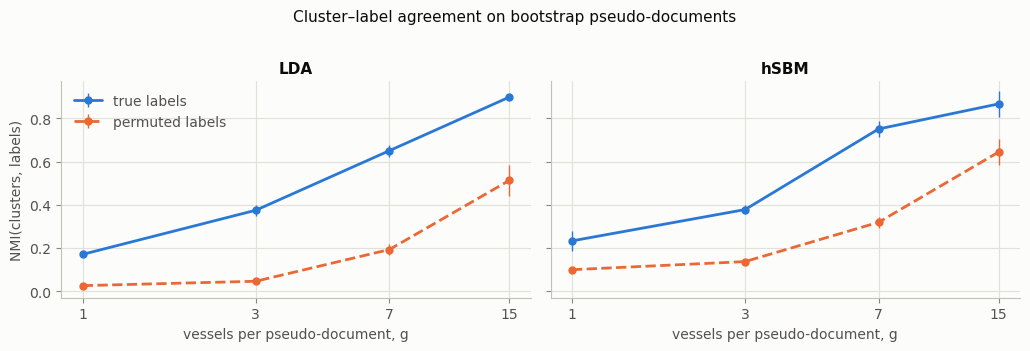

,CW,EFG,MI,LFG
training vessels,71.0,52.0,74.0,27.0
expected copies of each vessel (g = 7),9.9,13.5,9.5,25.9


In [32]:
models_run = boot["model"].unique()
fig, axes = plt.subplots(1, len(models_run), figsize=(5.2 * len(models_run), 3.4), sharey=True, squeeze=False)
for ax, name in zip(axes[0], models_run):
    for kind, color, ls in [("true labels", pl.COLORS["CW"], "-"), ("permuted labels", pl.COLORS["EFG"], "--")]:
        s = boot[(boot["model"] == name) & (boot["labels"] == kind)].groupby("g")["NMI"]
        ax.errorbar(s.mean().index, s.mean(), yerr=s.std(), color=color, ls=ls, marker="o", ms=5,
                    capsize=0, elinewidth=1, label=kind)
    ax.set_xscale("log", base=2); ax.set_xticks([1, 3, 7, 15], [1, 3, 7, 15])
    ax.set_xlabel("vessels per pseudo-document, g"); ax.set_title(name)
axes[0][0].set_ylabel("NMI(clusters, labels)"); axes[0][0].legend(loc="upper left")
fig.suptitle("Cluster–label agreement on bootstrap pseudo-documents", y=1.02, fontsize=11)
fig.tight_layout(); pl.save(fig, "bootstrap_bias"); plt.show()
counts = pd.Series([d["culture"] for d in train_c]).value_counts().reindex(BOKS)
pd.DataFrame({"training vessels": counts, "expected copies of each vessel (g = 7)": 100 * 7 / counts}).round(1).T

**Which biases does the bootstrap introduce?**
1. **Label leakage into an unsupervised model.** Pooling vessels of one label makes each pseudo-document look like its label's average, so even meaningless labels are "recovered" (table above). Only the gap between the two curves reflects real differences between BoKs, and without pooling that gap is small.
2. **Variance shrinks, information does not grow.** Resampling cannot create triplets the sample lacks; the distributions converge to the *sample* distribution.
3. **Unequal replication.** With 100 pseudo-documents per BoK, each late-FBW vessel is copied about 26 times, each middle-FBW or CW vessel about 10 times; small BoKs and their idiosyncratic vessels are amplified and the prior over BoKs becomes uniform.
4. **Pseudo-replication.** Pseudo-documents share vessels, so they are not independent; tests on them, and tests of vessels contained in them, are invalid.

Better uses: bootstrap *statistics* for confidence intervals (resampling vessels or whole sites), build pseudo-documents only inside training folds (as here), and prefer explicit Bayesian smoothing for sparse counts.

### 7.2 The hSBM on single vessels, and the overlapping model
Without pooling, each vessel is its own document. Two models of the same network: the non-overlapping hSBM (best of 5 starts, refined) and the **overlapping** hSBM of legacy cell 36, in which each edge (token) chooses its own group, so nodes can belong to several groups. On the bootstrap corpus the overlapping fit needs one node per token (≈ 13 000) and did not finish within 15 minutes — the likely reason the legacy cell failed. On the 2 326 tokens of the real vessels it takes seconds. Both models describe the same multigraph, so their description lengths are directly comparable: the lower one is the better model.

In [33]:
if RUN_SBM:
    single = [d["triplets"] for d in all_docs]
    fits = {"non-overlapping (5 starts, refined)": sbm.fit_hsbm(single, seed=SEED, n_init=5, refine_sweeps=50),
            "overlapping": sbm.fit_hsbm(single, seed=SEED, overlap=True)}
    rows = []
    for name, m in fits.items():
        for h in sbm.hierarchy(m):
            if h["doc_groups"] == 1 and h["level"] > 0:
                continue
            part = sbm.doc_partition(m, h["level"])
            rows.append({"model": name, "description length (nats)": m.mdl, **h,
                         "NMI with BoK": sbm.agreement(part, y_bok)["NMI"],
                         "NMI with culture": sbm.agreement(part, df["culture"])["NMI"]})
    display(pd.DataFrame(rows).set_index(["model", "level"]))

description length (nats)  \
model                               level                              
non-overlapping (5 starts, refined) 0                       5139.377   
                                    1                       5139.377   
overlapping                         0                       6091.855   

                                           doc_groups  word_groups  \
model                               level                            
non-overlapping (5 starts, refined) 0              10           16   
                                    1               4            7   
overlapping                         0               1            1   

                                           NMI with BoK  NMI with culture  
model                               level                                  
non-overlapping (5 starts, refined) 0             0.148             0.125  
                                    1             0.140             0.156  
overlapping                         0             0.000             0.000

The overlapping model collapses to a single group and needs about 950 nats more than the non-overlapping one: MDL rejects mixed membership for these data. The non-overlapping hSBM on single vessels finds 10 vessel groups and 16 topics, only weakly related to BoK or culture (NMI ≈ 0.15): the clean separation of Section 5.2 requires the pooling.

### 7.3 Cross-validation with baselines
**What is done: repeated, site-grouped 5-fold cross-validation.**
- *One round (one seed $r$).* The 88 sites are dealt into 5 folds (Section 3). For each fold $f=1,\dots,5$, every model is refitted from scratch on the training vessels $\mathcal T_f$ — vocabulary, stop triplets, pseudo-documents, topics, partitions — and then predicts the test vessels $\mathcal D_f$. After the 5 folds each vessel $i$ has exactly one out-of-fold prediction $\hat p^{(r)}(\cdot\mid x_i)$, made by a model that never saw its site.
- *"5 folds × 3 seeds".* The round is repeated with 3 seeds. A seed changes the assignment of sites to folds, the bootstrap draws and the samplers. The $3\times276=828$ predictions are pooled:
$$\mathrm{accuracy}=\frac{1}{828}\sum_{r=0}^{2}\sum_{i=1}^{276}\mathbf 1\Big[\arg\max_c\hat p^{(r)}(c\mid x_i)=c_i\Big],\qquad \text{log-loss}=-\frac{1}{828}\sum_{r,i}\ln\hat p^{(r)}(c_i\mid x_i).$$
- *Why.*
  - The single split of Sections 4–6 tests 52 vessels, so one standard error is ≈ 0.07.
  - Cross-validation tests every vessel, and the 3 seeds average over the arbitrary choice of folds; they move accuracies by only ≈ 0.01.
  - The uncertainty that remains — which sites happen to be in the data — is ± 0.04–0.05, computed at the end of this section.
- *Two protocols.*
  - "CV, sites": folds of whole sites, the honest test for a vessel from a new excavation.
  - "CV, vessels": folds of single vessels, stratified by BoK, so site-mates can sit in training. It is shown for comparison.

The models are the three topic-model pipelines exactly as in Sections 4–5 (asserted there) and four simple baselines. All are refitted in every fold on the training vessels only:

| model | idea |
|---|---|
| majority | always the largest BoK |
| vessel form only | $p(\text{BoK}\mid\text{form})$ – no technique information |
| naive Bayes, triplets | supervised bag of triplets (= labelled LDA, one topic per BoK), no bootstrap |
| Markov order 1 | $p(\text{BoK}\mid\text{chain})\propto p(\text{BoK})\,p(\text{chain}\mid\text{BoK})$ (Section 10) |
| LDA · hSBM, cluster classifier · hSBM, fold-in | the pipelines of Sections 4–5 |

In [34]:
def make_models(seed):
    m = {"majority": lambda: clf.Majority(),
         "vessel form only": lambda: clf.ColumnPrior("vessel_type"),
         "naive Bayes, triplets": lambda: clf.NaiveBayesNgram(),
         "Markov order 1": lambda: clf.MarkovClassifier(1, beta=2.0, grammar=grammar),
         "LDA": lambda: clf.LDAPipeline(remove_top=STOP_K, seed=seed)}
    if RUN_SBM:
        m["hSBM, cluster classifier"] = lambda: clf.SBMPipeline("clusters", remove_top=STOP_K, seed=seed)
        m["hSBM, fold-in"] = lambda: clf.SBMPipeline("fold-in", remove_top=STOP_K, seed=seed)
    return m

tables, pooled = [], {}
for seed in range(3):
    t, p = ev.compare(df, make_models(seed), n_splits=5, seed=seed, verbose=False)
    tables.append(t.assign(seed=seed))
    for (name, split), proba in p.items():
        pooled.setdefault((name, split), []).append(proba)
cv = pd.concat(tables)
for (name, split), probas in pooled.items():
    R.add(name, f"CV, {'sites' if split == 'site' else 'vessels'}", np.tile(y_bok, 3), np.vstack(probas))
cv_models = list(make_models(0))
R.table("CV, sites", cv_models)

,,n,accuracy,balanced_acc,macro_F1,log_loss,brier,ECE
model,protocol,,,,,,,
majority,"CV, sites",828,0.344,0.250,0.128,1.329,0.721,4.404e-04
vessel form only,"CV, sites",828,0.560,0.457,0.427,1.068,0.601,4.023e-02
"naive Bayes, triplets","CV, sites",828,0.501,0.433,0.431,1.417,0.699,2.451e-01
Markov order 1,"CV, sites",828,0.537,0.459,0.456,1.292,0.605,1.282e-01
LDA,"CV, sites",828,0.510,0.524,0.486,1.180,0.632,8.520e-02
"hSBM, cluster classifier","CV, sites",828,0.517,0.518,0.503,2.330,0.707,2.606e-01
"hSBM, fold-in","CV, sites",828,0.517,0.518,0.496,1.643,0.675,2.253e-01


**How to read it.** These are the scores with whole sites held out, pooled over 5 folds × 3 seeds ($n$ = 828); the columns are those of Section 3.
- *Accuracy:* every model that uses the chain lands at 0.50–0.54, vessel form alone at 0.56, the majority rule at 0.34.
- *Balanced accuracy:* the topic-model pipelines reach 0.52 and the supervised chain models 0.43–0.46. The pipelines' balanced pseudo-documents act as a uniform prior, which favours small BoKs (auxiliary notebook, 2.4).
- *Log-loss:* below the majority rule's 1.33, probabilities are informative. Naive Bayes (1.42) and both hSBM classifiers (1.64, 2.33) are *worse* than the majority rule on this score, i.e. over-confident.
- *Evidence:* see the site bootstrap at the end of 7.3. No two chain models differ beyond noise.

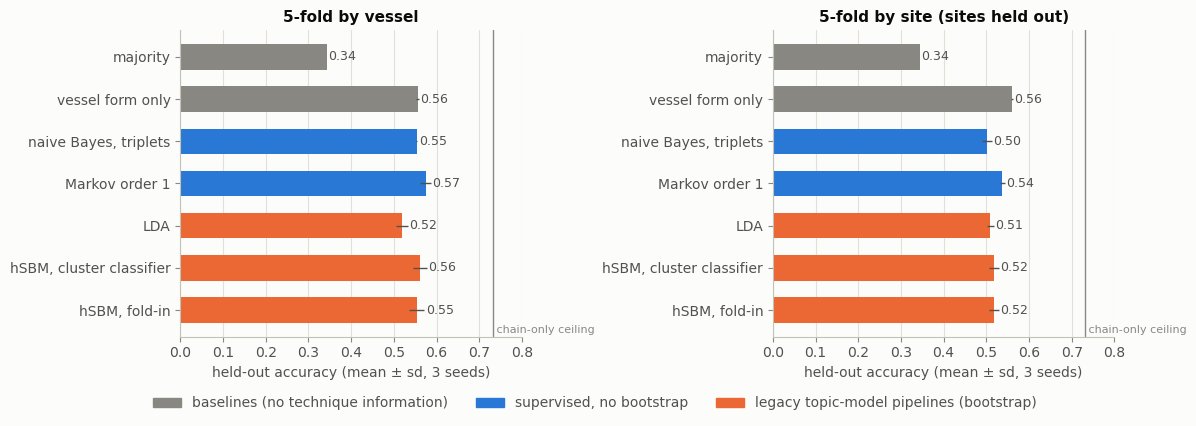

,,n,accuracy,balanced_acc,macro_F1,log_loss,brier,ECE
model,protocol,,,,,,,
majority,"CV, vessels",828,0.344,0.250,0.128,1.309,0.715,5.664e-06
vessel form only,"CV, vessels",828,0.556,0.452,0.422,1.046,0.591,3.210e-02
"naive Bayes, triplets","CV, vessels",828,0.553,0.529,0.531,1.235,0.604,1.816e-01
Markov order 1,"CV, vessels",828,0.575,0.540,0.544,1.139,0.559,6.961e-02
LDA,"CV, vessels",828,0.519,0.536,0.499,1.158,0.622,4.511e-02
"hSBM, cluster classifier","CV, vessels",828,0.562,0.563,0.550,2.205,0.662,2.189e-01
"hSBM, fold-in","CV, vessels",828,0.553,0.558,0.539,1.552,0.638,1.928e-01


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
colors = [pl.INK["muted"]] * 2 + [pl.COLORS["CW"]] * 2 + [pl.COLORS["EFG"]] * (len(cv_models) - 4)
for ax, split, title in zip(axes, ["stratified", "site"], ["5-fold by vessel", "5-fold by site (sites held out)"]):
    s = cv[cv["split"] == split].groupby("model")["accuracy"]
    pl.hbars(ax, cv_models, s.mean().reindex(cv_models).values, colors, xerr=s.std().reindex(cv_models).values,
             ref=ceiling["BoK (4 classes)"], ref_label="chain-only ceiling")
    ax.set_title(title); ax.set_xlabel("held-out accuracy (mean ± sd, 3 seeds)"); ax.set_xlim(0, 0.8)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=pl.INK["muted"], label="baselines (no technique information)"),
                    Patch(color=pl.COLORS["CW"], label="supervised, no bootstrap"),
                    Patch(color=pl.COLORS["EFG"], label="legacy topic-model pipelines (bootstrap)")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout(); pl.save(fig, "cv_accuracy"); plt.show()
R.table("CV, vessels", cv_models)

**How to read it.**
- *Shown:* the same models when vessels, not sites, are held out, so a test vessel's site-mates can be in the training data. The figure compares both protocols.
- *Numbers:* accuracies rise by 0–5 points (Markov 0.54 → 0.58, hSBM cluster classifier 0.52 → 0.56) and log-losses fall. The gain is what the site-mates give away.
- *Caveat:* for a vessel from a new excavation, the site-held-out numbers are the honest ones.

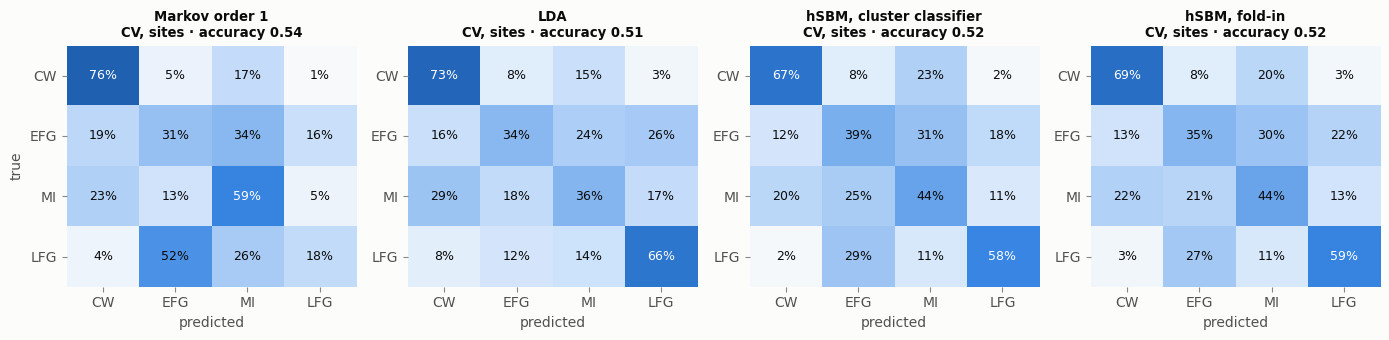

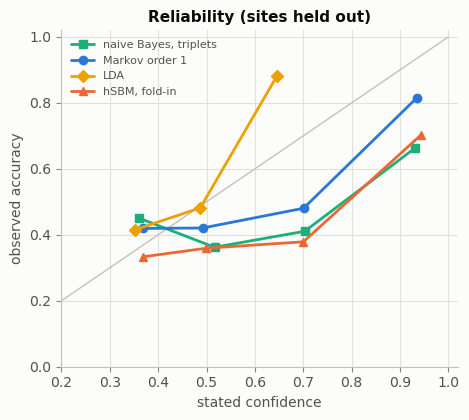

In [36]:
fig = pl.confusion_panel(R, [(m, "CV, sites") for m in ["Markov order 1"] + topic_models]); plt.show()
fig, ax = plt.subplots(figsize=(4.8, 4.3))
ax.plot([0, 1], [0, 1], color=pl.INK["axis"], lw=1)
for name, color, marker in [("naive Bayes, triplets", pl.COLORS["MI"], "s"), ("Markov order 1", pl.COLORS["CW"], "o"),
                            ("LDA", pl.COLORS["LFG"], "D")] + ([("hSBM, fold-in", pl.COLORS["EFG"], "^")] if RUN_SBM else []):
    y, p = R.proba[(name, "CV, sites")]
    conf, correct = p.max(1), p.argmax(1) == np.array([BOKS.index(v) for v in y])
    bins = np.clip((conf * 5).astype(int), 0, 4)
    keep = [b for b in range(5) if (bins == b).sum() >= 10]
    ax.plot([conf[bins == b].mean() for b in keep], [correct[bins == b].mean() for b in keep],
            color=color, marker=marker, ms=6, label=name)
ax.set_xlabel("stated confidence"); ax.set_ylabel("observed accuracy"); ax.set_xlim(0.2, 1.02); ax.set_ylim(0, 1.02)
ax.legend(loc="upper left", fontsize=8); ax.set_title("Reliability (sites held out)")
fig.tight_layout(); plt.show()

**How to read it.**
- *Confusion matrices:* rows are the true BoK, columns the predicted BoK; each row sums to 100 %, and the diagonal is each BoK's recall.
  - CW is recognised best (67–76 %). Middle FBW is called CW in 20–29 % of cases.
  - The FBW phases are confused with each other: early FBW is right only 31–39 % of the time.
  - The Markov model, whose prior follows the BoK sizes, sends 52 % of late-FBW vessels to early FBW (recall 18 %). The topic models, trained on balanced pseudo-documents, recall late FBW at 58–66 %.
- *Reliability diagram:* predictions binned by stated confidence (x) against the observed accuracy in the bin (y); the diagonal is perfect calibration.
  - Naive Bayes and the hSBM state 0.93–0.94 but are right 0.66–0.70 of the time, so they are over-confident.
  - The Markov model states 0.93 and is right 0.81 of the time.
  - LDA's highest bin states 0.65 and is right 0.88 of the time, so it is under-confident.

**Why LDA's "observed accuracy" looks so high.** The reliability diagram does not show overall accuracy; LDA's is 0.51. It sorts the 828 predictions by their *stated confidence* (the largest probability) into bins of width 0.2. For each bin with at least 10 predictions it plots the mean confidence (x) against the share of correct predictions (y).
- *LDA's three bins:*
  - 260 predictions at confidence ≈ 0.35, right 42 % of the time;
  - 467 at ≈ 0.49, right 48 %;
  - 101 at ≈ 0.65, right 88 %.

  The last point is the "high" one: when LDA is most confident it is right 88 % of the time, but it only *says* 65 %.
- *Why it cannot say more.* LDA's fold-in gives a vessel with $N$ known triplet tokens the topic mixture $\theta_k=(n_k+\alpha)/(N+K\alpha)$, with $\sum_k n_k=N$ (4.1). Even if every token points to the same topic, $n_k=N$, and
$$\max_c\hat p(c\mid x)\;\le\;\frac{N+\alpha}{N+K\alpha}=\frac{N+1}{N+4}\qquad(\alpha=1,\ K=4).$$
  A test vessel has $N\approx5$ known triplets (median 5, at most 10), so LDA's confidence is capped near $6/9\approx0.67$, and never above $11/14\approx0.79$. The four pseudo-counts of the Dirichlet prior weigh almost as much as the vessel's own evidence, and pull every prediction toward $1/4$. All 828 predictions obey the bound; the largest is 0.73.
- *So:* LDA is **under-confident**, not unusually accurate. Its low ECE hides this, because only 12 % of its predictions fall in the confident bin. Recalibrating its probabilities on the training folds (e.g. with a temperature) would sharpen them without changing its decisions; a smaller $\alpha$ changes the fit itself (4.6).

**In short.**
- The three legacy topic-model pipelines are **not better than supervised baselines that need no bootstrap**. The hSBM fold-in and cluster classifiers perform alike; the fold-in's advantage on the single split of 5.5 was within noise.
- Naive Bayes and both hSBM classifiers are over-confident, the expected result of counting overlapping triplets as independent evidence (Section 2). LDA has the lowest log-loss and ECE, but errs the other way: it is under-confident (next cell).
- The errors are mostly among the FBW phases, and the class balance decides which phase is favoured: the Markov model, with the BoK frequencies as prior, rarely predicts late FBW; the topic models, trained on balanced pseudo-documents, often do.

**How large is the noise?** Vessels of one site resemble each other, so the honest uncertainty of these scores comes from resampling *sites*. We draw the sites with replacement 2000 times and recompute every score; the spread of the recomputed values is the standard error (se). For a difference between two models, both are scored on the same draws, which removes the variation they share. $z$ = difference / se; $|z|\gtrsim2$ is a difference beyond noise.

In [37]:
def site_bootstrap(models, pairs=(), protocol="CV, sites", B=2000, seed=SEED):
    """Uncertainty of cross-validated scores when whole sites are resampled with replacement (the vessels of a site
    move together). Each vessel's hit (0/1) and −ln p(true BoK) are first averaged over the 3 seeds. Paired
    differences use the same draws for both models."""
    names = list(dict.fromkeys(list(models) + [m for pair in pairs for m in pair]))
    y_idx = np.array([BOKS.index(c) for c in y_bok])
    hit, nll = {}, {}
    for m in names:
        p = R.proba[(m, protocol)][1].reshape(-1, len(df), len(BOKS))          # seeds × vessels × BoKs
        hit[m] = (p.argmax(2) == y_idx).mean(0)
        nll[m] = -np.log(np.clip(p[:, np.arange(len(df)), y_idx], 1e-6, 1)).mean(0)
    sites = list(df.groupby("site_id").indices.values())
    rng = np.random.default_rng(seed)
    draws = [np.concatenate([sites[k] for k in rng.integers(len(sites), size=len(sites))]) for _ in range(B)]
    se = lambda v: np.std([v[d].mean() for d in draws])
    single = pd.DataFrame({("accuracy", "mean"): {m: hit[m].mean() for m in models},
                           ("accuracy", "se"): {m: se(hit[m]) for m in models},
                           ("log-loss", "mean"): {m: nll[m].mean() for m in models},
                           ("log-loss", "se"): {m: se(nll[m]) for m in models}})
    paired = pd.DataFrame({f"{a}  −  {b}": {("Δ accuracy", "mean"): (hit[a] - hit[b]).mean(),
                                             ("Δ accuracy", "se"): se(hit[a] - hit[b]),
                                             ("Δ accuracy", "z"): (hit[a] - hit[b]).mean() / se(hit[a] - hit[b]),
                                             ("Δ log-loss", "mean"): (nll[a] - nll[b]).mean(),
                                             ("Δ log-loss", "se"): se(nll[a] - nll[b])} for a, b in pairs}).T
    return single, paired

pairs = [("LDA", "Markov order 1"), ("hSBM, fold-in", "LDA"), ("Markov order 1", "vessel form only"),
         ("Markov order 1", "majority"), ("vessel form only", "majority")]
single, paired = site_bootstrap(cv_models, [p for p in pairs if set(p) <= set(cv_models)])
print(f"{df['site_id'].nunique()} sites, 2000 bootstrap draws")
display(single.round(3))
paired.round(3)

88 sites, 2000 bootstrap draws


accuracy        log-loss       
                             mean     se     mean     se
majority                    0.344  0.082    1.329  0.073
vessel form only            0.560  0.049    1.068  0.060
naive Bayes, triplets       0.501  0.041    1.417  0.116
Markov order 1              0.537  0.044    1.292  0.135
LDA                         0.510  0.041    1.180  0.051
hSBM, cluster classifier    0.517  0.033    2.330  0.271
hSBM, fold-in               0.517  0.035    1.643  0.168

Δ accuracy               Δ log-loss       
                                          mean     se      z       mean     se
LDA  −  Markov order 1                  -0.028  0.054 -0.511     -0.112  0.121
hSBM, fold-in  −  LDA                    0.007  0.022  0.326      0.464  0.142
Markov order 1  −  vessel form only     -0.023  0.039 -0.592      0.224  0.117
Markov order 1  −  majority              0.193  0.078  2.482     -0.037  0.118
vessel form only  −  majority            0.216  0.096  2.246     -0.261  0.059

**How to read it.**
- *First table:* each model's cross-validated accuracy and log-loss, with its site-bootstrap standard error (88 sites). The chain models' accuracies carry ± 0.03–0.04. The majority rule carries ± 0.08, because the class mix changes from site to site.
- *Second table:* paired differences.
  - No model that uses the chain beats another, or beats form alone: LDA vs Markov −0.03 ± 0.05; Markov vs form −0.02 ± 0.04; hSBM fold-in vs LDA +0.01 ± 0.02.
  - Markov and form beat the majority rule by 0.19–0.22 ($z$ ≈ 2.2–2.5): real, but each by only about two standard errors.
  - The calibration differences are real: the hSBM's log-loss is 0.46 ± 0.14 worse than LDA's ($z$ ≈ 3.3).
- *Caveat:* sites are treated as independent. Neighbouring sites may share more than that, so these standard errors are, if anything, too small.

### 7.4 Sensitivity to the legacy choices
First the pseudo-document size $g$ ($g=1$: no pooling) and stop-triplet removal, for LDA and the hSBM fold-in classifier (sites held out, seed 0). Then the deletion rule itself: frequency or information (4.1).

In [38]:
rows = []
for g, k in [(1, 5), (3, 5), (7, 5), (15, 5), (7, 0)]:
    cand = {"LDA": lambda g=g, k=k: clf.LDAPipeline(g=g, remove_top=k, seed=SEED)}
    if RUN_SBM:
        cand["hSBM, fold-in"] = lambda g=g, k=k: clf.SBMPipeline("fold-in", g=g, remove_top=k, seed=SEED)
    for name, mk in cand.items():
        p = ev.cross_val_proba(df, mk, "site", 5, SEED)
        rows.append({"model": name, "stop triplets removed": k, "g": g, **ev.scores(y_bok, p)})
pd.DataFrame(rows).set_index(["model", "stop triplets removed", "g"])[["accuracy", "balanced_acc", "log_loss", "ECE"]]

,,,accuracy,balanced_acc,log_loss,ECE
model,stop triplets removed,g,,,,
LDA,5,1,0.428,0.436,1.322,0.087
"hSBM, fold-in",5,1,0.467,0.458,1.415,0.083
LDA,5,3,0.446,0.458,1.243,0.084
"hSBM, fold-in",5,3,0.464,0.472,1.423,0.129
LDA,5,7,0.511,0.527,1.176,0.102
"hSBM, fold-in",5,7,0.522,0.527,1.614,0.229
LDA,5,15,0.489,0.506,1.164,0.148
"hSBM, fold-in",5,15,0.518,0.535,2.021,0.264
LDA,0,7,0.496,0.516,1.157,0.086


**How to read it.**
- *Shown:* site-held-out scores (one seed) as the pseudo-document size $g$ and the number of removed stop triplets vary; $g=1$ means no pooling.
- *Evidence:* with ± 0.04–0.05 per accuracy, the rise from $g=1$ (0.43–0.47) to $g=7$ (0.51–0.52) is about one to two standard errors. All other differences are within noise.

Pooling helps both unsupervised pipelines up to $g\approx7$ and not beyond; it lets them reach the level that supervised models reach without any resampling — in these pipelines the bootstrap is a roundabout way of supervising. Larger $g$ makes the hSBM more over-confident (log-loss 1.4 → 2.0). Removing the five stop triplets changes accuracy by 0.01–0.02.

**Frequency or information?** The same LDA pipeline with five deletion rules, each decided on the training vessels of every fold:
- nothing removed;
- the 5 most frequent triplets removed (legacy);
- the 10, or the 30, triplets with the least information about the BoK removed (MI − chance, 4.1);
- only the informative triplets kept ($q<0.05$).

Sites held out, 3 × 5-fold; each rule is compared with "nothing removed" by the paired site bootstrap of 7.3.

In [ ]:
class LDASelect(clf.LDAPipeline):
    """The LDA pipeline of Section 4 with a different deletion rule, decided on the training vessels of each fold:
    an integer k removes the k triplets with the least information about the BoK (MI − chance, 4.1);
    "informative only" keeps just the triplets with q < 0.05."""
    def __init__(self, rule, seed=0):
        super().__init__(remove_top=0, seed=seed)
        self.rule = rule

    def fit(self, df):
        docs = tm.load_pottery_data(df)
        info = triplet_information(docs, seed=self.seed)
        if self.rule == "informative only":
            self.removed = list(info.index[info["q"] >= 0.05])
        else:
            self.removed = list(info.sort_values("MI − chance (bits)").index[:self.rule])
        drop = set(self.removed)
        docs = [{**d, "triplets": [t for t in d["triplets"] if t not in drop]} for d in docs]
        self.vocabulary, _ = tm.extract_vocabulary(docs)
        pdocs = tm.create_resampled_documents(docs, self.g, self.n_per_class, self.seed)
        X_, _ = tm.build_dtm_with_external_vocab(pdocs, {w: i for i, w in enumerate(self.vocabulary)})
        self.lda = tm.LDA_manual(len(self.classes), self.alpha, self.beta, self.n_iter, self.seed).fit(X_, self.vocabulary)
        emp = tm.get_empirical_word_distribution(docs, self.vocabulary, self.classes)
        self.mapping, _ = tm.matching_empirical(emp, self.lda.topic_word_dist, self.classes)
        return self

deletion = {"LDA, nothing removed": lambda s: LDASelect(0, s),
            "LDA, 5 most frequent removed (legacy)": lambda s: clf.LDAPipeline(remove_top=5, seed=s),
            "LDA, 10 least informative removed": lambda s: LDASelect(10, s),
            "LDA, 30 least informative removed": lambda s: LDASelect(30, s),
            "LDA, informative triplets only": lambda s: LDASelect("informative only", s)}
for name, make in deletion.items():
    probas = [ev.cross_val_proba(df, lambda: make(seed), "site", 5, seed) for seed in range(3)]
    R.add(name, "CV, sites", np.tile(y_bok, 3), np.vstack(probas))
display(R.table("CV, sites", list(deletion))[["accuracy", "balanced_acc", "macro_F1", "log_loss", "ECE"]])
_, paired_del = site_bootstrap([], [(name, "LDA, nothing removed") for name in list(deletion)[1:]])
paired_del.round(3)

,,accuracy,balanced_acc,macro_F1,log_loss,ECE
model,protocol,,,,,
"LDA, nothing removed","CV, sites",0.499,0.518,0.471,1.167,0.074
"LDA, 5 most frequent removed (legacy)","CV, sites",0.510,0.524,0.486,1.180,0.085
"LDA, 10 least informative removed","CV, sites",0.522,0.536,0.496,1.157,0.058
"LDA, 30 least informative removed","CV, sites",0.504,0.521,0.480,1.173,0.074
"LDA, informative triplets only","CV, sites",0.452,0.483,0.434,1.205,0.094


Δ accuracy  \
                                                                     mean   
LDA, 5 most frequent removed (legacy)  −  LDA, nothing removed      0.011   
LDA, 10 least informative removed  −  LDA, nothing removed          0.023   
LDA, 30 least informative removed  −  LDA, nothing removed          0.005   
LDA, informative triplets only  −  LDA, nothing removed            -0.047   

                                                                              \
                                                                   se      z   
LDA, 5 most frequent removed (legacy)  −  LDA, nothing removed  0.010  1.082   
LDA, 10 least informative removed  −  LDA, nothing removed      0.008  2.931   
LDA, 30 least informative removed  −  LDA, nothing removed      0.012  0.395   
LDA, informative triplets only  −  LDA, nothing removed         0.021 -2.218   

                                                               Δ log-loss  \
                                                                     mean   
LDA, 5 most frequent removed (legacy)  −  LDA, nothing removed      0.013   
LDA, 10 least informative removed  −  LDA, nothing removed         -0.009   
LDA, 30 least informative removed  −  LDA, nothing removed          0.006   
LDA, informative triplets only  −  LDA, nothing removed             0.039   

                                                                       
                                                                   se  
LDA, 5 most frequent removed (legacy)  −  LDA, nothing removed  0.010  
LDA, 10 least informative removed  −  LDA, nothing removed      0.005  
LDA, 30 least informative removed  −  LDA, nothing removed      0.009  
LDA, informative triplets only  −  LDA, nothing removed         0.022

**How to read it.**
- *First table:* the five rules, with the scores of Section 3. *Second table:* each rule minus "nothing removed", paired over the same site resamples.
- *Numbers:*
  - nothing removed: 0.50;
  - legacy (5 most frequent removed): 0.51 (+0.01 ± 0.01);
  - 10 least informative removed: 0.52 (+0.02 ± 0.01, $z$ = 2.9);
  - 30 least informative removed: 0.50 (+0.005 ± 0.012);
  - informative triplets only: 0.45 (−0.05 ± 0.02, $z$ = −2.2).
- *What it means:*
  - Removing the 10 least informative triplets (in the split of 4.1: 6 with no evidence of information and 4 rare ones) is a small but consistent gain.
  - Removing 30 reaches into the rare triplets and gains nothing.
  - Keeping only the 27 significant triplets throws away the 46 rare ones. No test can judge them one by one, but together they carry information: with few vessels, "not significant" does not mean "uninformative".
- *So:* delete only what is clearly uninformative, decide it inside the training data, and expect a point or two at most. The deletion rule is not what limits LDA. To keep every triplet everywhere in this notebook, set `STOP_K = 0` in the setup cell.

### 7.5 Vessel form
**CW vs FBW.** The cultural question of the thesis is the two-class one:

In [39]:
two = ["CW", "FBW"]
t2, _ = ev.compare(df, {
    "majority": lambda: clf.Majority(two, "culture"),
    "vessel form only": lambda: clf.ColumnPrior("vessel_type", two, "culture"),
    "naive Bayes, triplets": lambda: clf.NaiveBayesNgram(classes=two, label="culture"),
    "Markov order 1": lambda: clf.MarkovClassifier(1, 2.0, grammar=grammar, classes=two, label="culture"),
    "Markov order 1 + form prior": lambda: clf.MarkovClassifier(1, 2.0, grammar=grammar, classes=two,
                                                                label="culture", prior_column="vessel_type"),
}, classes=two, label="culture", seed=SEED, verbose=False)
print(f"chain-only ceiling: {ceiling['culture (CW vs FBW)']:.3f}")
t2.pivot(index="model", columns="split", values=["accuracy", "balanced_acc"])

chain-only ceiling: 0.888


accuracy            balanced_acc           
split                           site stratified         site stratified
model                                                                  
Markov order 1                 0.808      0.804        0.773      0.761
Markov order 1 + form prior    0.822      0.826        0.822      0.819
majority                       0.678      0.678        0.500      0.500
naive Bayes, triplets          0.801      0.822        0.779      0.789
vessel form only               0.804      0.804        0.835      0.835

**How to read it.**
- *Shown:* the two-class problem, CW vs the union of the FBW phases. Accuracy and balanced accuracy, with sites held out ("site") and vessels held out ("stratified").
- *Numbers:* majority 0.68; chain models 0.80–0.82; form alone 0.80, with the highest balanced accuracy (0.84); chain + form 0.82 and 0.82.
- *Evidence:* the differences among the non-trivial models (≤ 0.03 in accuracy) are within noise. All are far above the majority rule.

In these data "beaker or not" says as much about CW as the whole chaîne opératoire, and adding the chain to the form improves accuracy only slightly.

**Does the chain add anything beyond vessel form?** Replace the prior $p(\text{BoK})$ by $p(\text{BoK}\mid\text{form})$ and compare with form alone; the gain is the information the chaîne opératoire carries *given* the form.

In [40]:
t3, _ = ev.compare(df, {
    "vessel form only": lambda: clf.ColumnPrior("vessel_type"),
    "Markov order 1": lambda: clf.MarkovClassifier(1, 2.0, grammar=grammar),
    "Markov order 1 + form prior": lambda: clf.MarkovClassifier(1, 2.0, grammar=grammar, prior_column="vessel_type"),
}, seed=SEED, verbose=False)
t3.pivot(index="model", columns="split", values=["accuracy", "balanced_acc", "log_loss"])

accuracy            balanced_acc             \
split                           site stratified         site stratified   
model                                                                     
Markov order 1                 0.533      0.576        0.455      0.550   
Markov order 1 + form prior    0.580      0.616        0.547      0.610   
vessel form only               0.562      0.551        0.457      0.447   

                            log_loss             
split                           site stratified  
model                                            
Markov order 1                 1.288      1.079  
Markov order 1 + form prior    1.198      1.019  
vessel form only               1.064      1.048

**How to read it.**
- *Shown:* four BoKs. The Markov model with its usual prior $p(\text{BoK})$, the same model with the prior replaced by $p(\text{BoK}\mid\text{form})$, and form alone.
- *Numbers (chain + form vs form alone, sites / vessels held out):*
  - accuracy +0.02 / +0.07;
  - balanced accuracy +0.09 / +0.16;
  - log-loss +0.13 (worse) / −0.03.
- *Evidence:* the accuracy gain with sites held out is within noise; the gain in balanced accuracy, which comes from the FBW phases, is the clearer signal.
- *Caveat:* on unseen sites the combined probabilities are worse than form alone (log-loss 1.20 vs 1.06). The Markov likelihood is over-confident, and multiplying it in sharpens wrong predictions too.

So **the chaîne opératoire carries information beyond vessel form**, visible mainly in balanced accuracy, i.e. in separating the FBW phases. (Treating chain and form as independent given the BoK is an approximation; a joint model is a natural next step.)

## 8 · Topic models with richer data

Bootstrapping reshuffles the same information; it cannot add any. What *can* be added is other information about each vessel: its form, where it was found, and what kind of site it came from. The simplest way to give this to a topic model is as more words.

*Survival and selection, $P(X\mid S=1)$ (formerly this section), together with missing steps, geography and maximum entropy, are now in the auxiliary notebook [`new_attempts_experiments.ipynb`](new_attempts_experiments.ipynb).*

- **LDA.** Each vessel's document gets metadata tokens next to its triplets: `form=Beaker`, `region=Drenthe`, `cell=52.75N,6.50E` (a 0.25° grid cell, about 28 km north–south by 17 km east–west) and, optionally, `site type=megalith`. The legacy pipeline then runs unchanged: stop triplets, $g=7$ pseudo-documents, Gibbs LDA, Hungarian matching, fold-in.
- **hSBM.** Triplets and metadata are different kinds of thing, so they become different kinds of node. The result is a *tripartite* network, vessel – triplet – metadata (Hyland et al. 2021). graph-tool's `clabel`/`pclabel` keep the three kinds in separate groups at every level, and edges carry counts. A new vessel is placed by fold-in, as in 5.5: add it with its triplet and metadata edges, and choose the document group that costs the least description length.
- **Baseline.** Putting metadata into a topic model is worth something only if the model beats the metadata alone. So we also fit naive Bayes on the same metadata.
- **Caveat.** Site type is the find context. If phases were assigned partly by context, predicting them from it is circular (auxiliary notebook, 2.5). Results are reported with and without it.

All models are scored with whole sites held out (3 × 5-fold), as in 7.3.

**How the metadata enter, in formulas.** Vessel $i$ has triplets $w_{i1},\dots,w_{iN_i}$ and metadata tokens $m_{i1},\dots,m_{iM_i}$: form, region and grid cell, plus site type when it is used. After stop-triplet removal a vessel has on average $N_i\approx4.8$ triplets, and $M_i\approx3.0$ metadata tokens (4.0 with site type), so the metadata are about 3 of its 8 tokens.

- **Metadata alone (naive Bayes, the baseline).** One categorical distribution per field $f$ and BoK, Laplace-smoothed:
$$p(c\mid m_i)\propto\pi_c\prod_f\hat p_f(m_{if}\mid c),\qquad \hat p_f(v\mid c)=\frac{n_{f,v,c}+1}{n_{f,c}+V_f},$$
  where $n_{f,v,c}$ counts training vessels of BoK $c$ with value $v$, $n_{f,c}$ those with field $f$ recorded, and $V_f$ is the number of values of the field.
- **LDA.** The vocabulary becomes $\mathcal V=\mathcal V_T\cup\mathcal V_M$, and each topic is *one* distribution over both, $\sum_{w\in\mathcal V_T}\phi_k(w)+\sum_{v\in\mathcal V_M}\phi_k(v)=1$:
$$p(w_i,m_i\mid\theta_i,\phi)=\prod_{n=1}^{N_i}\sum_k\theta_{ik}\,\phi_k(w_{in})\;\prod_{j=1}^{M_i}\sum_k\theta_{ik}\,\phi_k(m_{ij}).$$
  One topic mixture $\theta_i$ explains techniques and metadata together, and a metadata token weighs exactly as much as a triplet. Pseudo-documents pool the triplets *and* the metadata of their $g=7$ vessels; a test vessel is folded in with both.
- **Tripartite hSBM.** The nodes are vessels, triplets and metadata values; $A_{iw}$ counts the occurrences of triplet $w$ in vessel $i$, and $A_{iv}=1$ if vessel $i$ has metadata value $v$.
  - A partition $b$ puts every node in a group, and every group holds nodes of one kind only, at every level (`clabel`, `pclabel`).
  - The nested degree-corrected SBM depends on the network only through the node degrees and the edge counts between groups, $e_{rs}=\sum_{ij}A_{ij}\,\delta_{b_i r}\,\delta_{b_j s}$. The partition minimises the description length $\Sigma(b)=-\ln P(A\mid b)-\ln P(b)$, as in Section 5.
  - A vessel group $r$ thus has one profile $e_{r\cdot}$ over the triplet groups (the topics) *and* the metadata groups. The metadata values are themselves grouped (8.1).
  - Fold-in, as in 5.5: $P(r\mid i)\propto e^{-\Delta\Sigma_r(i)}$, where $\Delta\Sigma_r(i)$ is the increase of description length when vessel $i$, with its triplet and metadata edges, joins vessel group $r$. Then $p(c\mid i)=\sum_r P(r\mid i)\,p(c\mid r)$.
- **The shared assumption.** All three treat triplets and metadata as independent given the latent class — the BoK $c$, the topic mixture $\theta_i$, or the group $r$. For place, the auxiliary notebook (5.1) finds no dependence between chain and location within a BoK; for form, the assumption is untested.

In [41]:
if RUN_SBM:
    import graph_tool.all as gt

def meta_tokens(row, fields):
    """The metadata of a vessel as extra words."""
    out = []
    if "form" in fields and isinstance(row.vessel_type, str):
        out.append(f"form={row.vessel_type}")
    if "region" in fields and isinstance(row.region, str) and row.region:
        out.append(f"region={row.region}")
    if "cell" in fields and np.isfinite(row.latitude):                  # 0.25° grid cell
        out.append(f"cell={np.floor(row.latitude / 0.25) * 0.25:.2f}N,{np.floor(row.longitude / 0.25) * 0.25:.2f}E")
    if "context" in fields and isinstance(row.site_type, str):
        out.append(f"site type={row.site_type}")
    return out

class MetaNB:
    """Baseline: naive Bayes on the metadata alone; one categorical distribution per field and culture (Laplace)."""
    def __init__(self, fields):
        self.fields = fields
    def fit(self, part):
        y = part["bok"].astype(str).to_numpy()
        toks = [meta_tokens(r, self.fields) for r in part.itertuples()]
        self.vocab = sorted({t for ts in toks for t in ts})
        n = np.ones((len(BOKS), len(self.vocab)))
        for ts, c in zip(toks, y):
            for t in ts:
                n[BOKS.index(c), self.vocab.index(t)] += 1
        field = np.array([t.split("=")[0] for t in self.vocab])
        for f in set(field):
            n[:, field == f] /= n[:, field == f].sum(1, keepdims=True)
        self.log_p = np.log(n)
        self.log_prior = np.log((pd.Series(y).value_counts().reindex(BOKS, fill_value=0).to_numpy() + 1) / (len(y) + len(BOKS)))
        return self
    def predict_proba(self, part):
        col = {t: j for j, t in enumerate(self.vocab)}
        return softmax_rows(np.array([self.log_prior + sum((self.log_p[:, col[t]] for t in meta_tokens(r, self.fields) if t in col),
                                                           np.zeros(len(BOKS))) for r in part.itertuples()]))

class RichLDA:
    """The LDA pipeline of Sections 4 and 7.3 with metadata tokens added to every vessel's document."""
    def __init__(self, fields, g=7, seed=0):
        self.fields, self.g, self.seed = fields, g, seed
    def _docs(self, part):
        return [{**d, "triplets": [t for t in d["triplets"] if t not in self.removed] + meta_tokens(r, self.fields)}
                for d, r in zip(tm.load_pottery_data(part), part.itertuples())]
    def fit(self, part):
        _, removed = tm.remove_common_triplets(tm.load_pottery_data(part), STOP_K)    # stop triplets, as before
        self.removed = set(removed)
        docs = self._docs(part)
        self.vocabulary, _ = tm.extract_vocabulary(docs)
        pseudo = tm.create_resampled_documents(docs, self.g, 100, self.seed)
        X_, _ = tm.build_dtm_with_external_vocab(pseudo, {w: i for i, w in enumerate(self.vocabulary)})
        self.lda = tm.LDA_manual(4, 1.0, 1.0, 200, self.seed).fit(X_, self.vocabulary)
        self.mapping, _ = tm.matching_empirical(tm.get_empirical_word_distribution(docs, self.vocabulary, BOKS),
                                                self.lda.topic_word_dist, BOKS)
        return self
    def predict_proba(self, part):
        return tm.lda_culture_proba(self.lda, self._docs(part), self.vocabulary, self.mapping, BOKS)

class TriSBM:
    """Tripartite hSBM, vessel – triplet – metadata (kinds 0, 1, 2 kept apart by clabel/pclabel), fitted to the g = 7
    pseudo-documents; a new vessel is placed by fold-in (least description length among the document groups)."""
    def __init__(self, fields, g=7, seed=0, sweeps=50):
        self.fields, self.g, self.seed, self.sweeps = fields, g, seed, sweeps
    def fit(self, part):
        docs = tm.load_pottery_data(part)
        meta = {d["vessel_id"]: meta_tokens(r, self.fields) for d, r in zip(docs, part.itertuples())}
        pseudo = tm.create_resampled_documents(docs, self.g, 100, self.seed)
        items = [[(1, w) for w in d["triplets"]] + [(2, m) for v in d["original_vessels"] for m in meta[v]] for d in pseudo]
        self.labels = [d["culture"] for d in pseudo]
        G = gt.Graph(directed=False); self.kind = G.new_vp("int"); self.count = G.new_ep("int")
        self.D = len(items); G.add_vertex(self.D); self.index = {}
        for d, its in enumerate(items):
            for it, c in Counter(its).items():
                if it not in self.index:
                    v = G.add_vertex(); self.kind[v] = it[0]; self.index[it] = int(v)
                self.count[G.add_edge(d, self.index[it])] = c
        self.G = G
        gt.openmp_set_num_threads(1); gt.seed_rng(self.seed + 1); np.random.seed(self.seed)   # seed_rng(0) would be random
        self.state = gt.minimize_nested_blockmodel_dl(G, state_args=dict(clabel=self.kind, pclabel=self.kind, eweight=self.count))
        for _ in range(self.sweeps):
            self.state.multiflip_mcmc_sweep(beta=np.inf, niter=10)
        b0 = np.asarray(self.state.get_bs()[0])[:self.D]
        self.groups = np.unique(b0)
        M_ = np.zeros((len(self.groups), len(BOKS)))
        for r, y in zip(b0, self.labels):
            M_[np.searchsorted(self.groups, r), BOKS.index(y)] += 1
        self.p_culture = M_ / M_.sum(1, keepdims=True)                    # p(culture | document group)
        return self
    def predict_proba(self, part):
        bs, out = [np.asarray(b) for b in self.state.get_bs()], []
        for toks, r in zip(data.documents(part), part.itertuples()):
            known = Counter(it for it in [(1, w) for w in toks] + [(2, m) for m in meta_tokens(r, self.fields)] if it in self.index)
            G = self.G.copy(); kind = G.copy_property(self.kind); count = G.copy_property(self.count)
            v = G.add_vertex(); kind[v] = 0
            for it, c in known.items():
                count[G.add_edge(v, self.index[it])] = c
            st = gt.NestedBlockState(G, bs=[np.append(bs[0], self.groups[0])] + bs[1:],
                                     state_args=dict(clabel=kind, pclabel=kind, eweight=count))
            dS = np.array([0.0] + [st.levels[0].virtual_vertex_move(int(v), int(g)) for g in self.groups[1:]])
            p = np.exp(-(dS - dS.min())); out.append(p / p.sum() @ self.p_culture)
        return np.array(out)

In [42]:
rich = {"metadata only: form, region, cell": lambda s: MetaNB(("form", "region", "cell")),
        "LDA + form, region, cell": lambda s: RichLDA(("form", "region", "cell"), seed=s),
        "metadata only: + site type": lambda s: MetaNB(("form", "region", "cell", "context")),
        "LDA + form, region, cell, site type": lambda s: RichLDA(("form", "region", "cell", "context"), seed=s)}
if RUN_SBM:
    rich["hSBM + form, region, cell"] = lambda s: TriSBM(("form", "region", "cell"), seed=s)
    rich["hSBM + form, region, cell, site type"] = lambda s: TriSBM(("form", "region", "cell", "context"), seed=s)
for name, make in rich.items():
    probas = [ev.cross_val_proba(df, lambda: make(seed), "site", 5, seed) for seed in range(3)]
    R.add(name, "CV, sites", np.tile(y_bok, 3), np.vstack(probas))
rich_table = ["majority", "vessel form only", "LDA"] + (["hSBM, fold-in"] if RUN_SBM else []) + list(rich)
R.table("CV, sites", rich_table)[["accuracy", "balanced_acc", "macro_F1", "log_loss", "ECE"]]

,,accuracy,balanced_acc,macro_F1,log_loss,ECE
model,protocol,,,,,
majority,"CV, sites",0.344,0.250,0.128,1.329,4.404e-04
vessel form only,"CV, sites",0.560,0.457,0.427,1.068,4.023e-02
LDA,"CV, sites",0.510,0.524,0.486,1.180,8.520e-02
"hSBM, fold-in","CV, sites",0.517,0.518,0.496,1.643,2.253e-01
"metadata only: form, region, cell","CV, sites",0.558,0.435,0.422,1.336,1.900e-01
"LDA + form, region, cell","CV, sites",0.528,0.459,0.451,1.070,5.533e-02
metadata only: + site type,"CV, sites",0.725,0.572,0.568,0.923,1.695e-01
"LDA + form, region, cell, site type","CV, sites",0.629,0.531,0.531,0.954,1.352e-01
"hSBM + form, region, cell","CV, sites",0.600,0.516,0.516,2.610,2.883e-01


**How to read it.** These are scores with sites held out (3 × 5-fold, $n$ = 828); the columns are those of Section 3. The first four rows repeat 7.3 for reference. "Metadata only" is naive Bayes on the metadata tokens alone; rows with "+" add those tokens to the topic models. The paired test after the reading below says which differences are real.

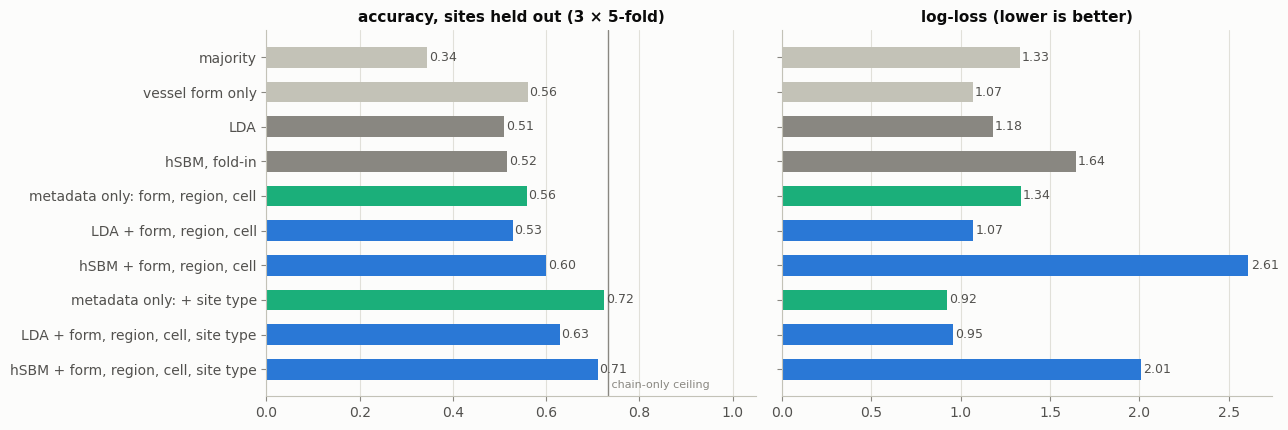

In [43]:
t = R.table("CV, sites", rich_table).droplevel("protocol")
order = ["majority", "vessel form only", "LDA"] + (["hSBM, fold-in"] if RUN_SBM else []) + \
        ["metadata only: form, region, cell", "LDA + form, region, cell"] + (["hSBM + form, region, cell"] if RUN_SBM else []) + \
        ["metadata only: + site type", "LDA + form, region, cell, site type"] + (["hSBM + form, region, cell, site type"] if RUN_SBM else [])
colors = [pl.INK["axis"]] * 2 + [pl.INK["muted"]] * (2 if RUN_SBM else 1) + \
         ([pl.COLORS["MI"]] + [pl.COLORS["CW"]] * (2 if RUN_SBM else 1)) * 2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
pl.hbars(axes[0], order, t.loc[order, "accuracy"].values, colors, ref=ceiling["BoK (4 classes)"], ref_label="chain-only ceiling")
pl.hbars(axes[1], order, t.loc[order, "log_loss"].values, colors)
axes[0].set_xlim(0, 1.05); axes[0].set_title("accuracy, sites held out (3 × 5-fold)")
axes[1].set_title("log-loss (lower is better)"); axes[1].set_yticklabels([])
fig.tight_layout(); plt.show()

**Reading.**
- **LDA barely uses the metadata.** Form, region and cell lift it from 0.51 to 0.53 and improve its log-loss (1.18 → 1.07), but it stays below the metadata alone (0.56). The metadata are not too few — about 3 of a vessel's 8 tokens (formulas above) — so a likely reason is that LDA fits its topics to explain which tokens co-occur in the pooled pseudo-documents, not to separate the BoKs.
- **The tripartite hSBM uses them better than LDA.** It rises from 0.52 to 0.60, above the metadata alone and above every chain-only model of 7.3, but these gains are only 1–1.5 standard errors (paired test below). Metadata nodes form their own groups, and an edge to a culture-specific metadata group (8.1) is strong evidence. Its probabilities are badly over-confident, though (log-loss 2.6): fold-in picks one document group almost deterministically.
- **With the site type**, the metadata alone (0.72) clearly beat LDA (0.63) and match the hSBM (0.71). When one variable is this informative, mixing it with weak triplet evidence in an unsupervised model only adds noise.
- **The lesson.** Richer data help, where bootstrapping did not. But a topic model is not the best way to combine different kinds of evidence for attribution. The maximum-entropy classifier of the auxiliary notebook (Part 6) reaches 0.69 with transitions, location and form, and 0.77 with the site type as well, with calibrated probabilities. The topic models remain the better *description* (8.1).

**Which of these differences are real?** Paired site-bootstrap of the accuracy and log-loss differences (as in 7.3).

In [44]:
pairs8 = [("LDA + form, region, cell", "LDA"), ("LDA + form, region, cell", "metadata only: form, region, cell"),
          ("hSBM + form, region, cell", "hSBM, fold-in"), ("hSBM + form, region, cell", "metadata only: form, region, cell"),
          ("metadata only: + site type", "LDA + form, region, cell, site type"),
          ("metadata only: + site type", "hSBM + form, region, cell, site type")]
_, paired8 = site_bootstrap([], [p for p in pairs8 if set(p) <= set(rich_table)])
paired8.round(3)

Δ accuracy  \
                                                                          mean   
LDA + form, region, cell  −  LDA                                         0.018   
LDA + form, region, cell  −  metadata only: form, region, cell          -0.030   
hSBM + form, region, cell  −  hSBM, fold-in                              0.083   
hSBM + form, region, cell  −  metadata only: form, region, cell          0.042   
metadata only: + site type  −  LDA + form, region, cell, site type       0.095   
metadata only: + site type  −  hSBM + form, region, cell, site type      0.014   

                                                                            \
                                                                        se   
LDA + form, region, cell  −  LDA                                     0.052   
LDA + form, region, cell  −  metadata only: form, region, cell       0.047   
hSBM + form, region, cell  −  hSBM, fold-in                          0.058   
hSBM + form, region, cell  −  metadata only: form, region, cell      0.043   
metadata only: + site type  −  LDA + form, region, cell, site type   0.033   
metadata only: + site type  −  hSBM + form, region, cell, site type  0.033   

                                                                            \
                                                                         z   
LDA + form, region, cell  −  LDA                                     0.349   
LDA + form, region, cell  −  metadata only: form, region, cell      -0.639   
hSBM + form, region, cell  −  hSBM, fold-in                          1.426   
hSBM + form, region, cell  −  metadata only: form, region, cell      0.985   
metadata only: + site type  −  LDA + form, region, cell, site type   2.854   
metadata only: + site type  −  hSBM + form, region, cell, site type  0.436   

                                                                    Δ log-loss  \
                                                                          mean   
LDA + form, region, cell  −  LDA                                        -0.110   
LDA + form, region, cell  −  metadata only: form, region, cell          -0.266   
hSBM + form, region, cell  −  hSBM, fold-in                              0.967   
hSBM + form, region, cell  −  metadata only: form, region, cell          1.274   
metadata only: + site type  −  LDA + form, region, cell, site type      -0.031   
metadata only: + site type  −  hSBM + form, region, cell, site type     -1.084   

                                                                            
                                                                        se  
LDA + form, region, cell  −  LDA                                     0.041  
LDA + form, region, cell  −  metadata only: form, region, cell       0.247  
hSBM + form, region, cell  −  hSBM, fold-in                          0.602  
hSBM + form, region, cell  −  metadata only: form, region, cell      0.388  
metadata only: + site type  −  LDA + form, region, cell, site type   0.257  
metadata only: + site type  −  hSBM + form, region, cell, site type  0.330

**How to read it.** Paired differences with sites held out ($z$ = difference / se).
- *LDA:* the metadata change accuracy by +0.02 ± 0.05 (no effect) but improve the log-loss by 0.11 ± 0.04 ($z$ ≈ −2.7): better probabilities, not better decisions. LDA + metadata does not differ from the metadata alone (−0.03 ± 0.05).
- *hSBM:* +0.08 ± 0.06 over the hSBM on triplets ($z$ = 1.4), and +0.04 ± 0.04 over the metadata alone ($z$ = 1.0): suggestive, not proven. Its log-loss is worse than the metadata alone by 1.3 ± 0.4.
- *With site type:* the metadata alone beat LDA (+0.10 ± 0.03, $z$ = 2.9) and match the hSBM (+0.01 ± 0.03).
- *What is solid:* the metadata improve LDA's probabilities, and no topic model beats the metadata alone in accuracy.

### 8.1 What the tripartite hSBM puts together
We fit the hSBM to the training vessels of Section 3, with form, region and grid cell as metadata. The table shows the metadata groups at level 0, and for each group the share of its edges that comes from each culture's pseudo-documents.

In [45]:
if RUN_SBM:
    tri = TriSBM(("form", "region", "cell"), seed=SEED).fit(train_df)          # training vessels of Section 3
    b0, kind = np.asarray(tri.state.get_bs()[0]), tri.kind.a
    tokens, share = {}, {}
    for (layer, w), v in tri.index.items():
        if layer == 2:
            tokens.setdefault(b0[v], []).append(w)
    for s, t_, c in tri.G.get_edges([tri.count]):
        d, m = (s, t_) if s < tri.D else (t_, s)
        if kind[m] == 2:
            share.setdefault(b0[m], np.zeros(len(BOKS)))[BOKS.index(tri.labels[d])] += c
    meta_groups = pd.DataFrame([{**dict(zip(BOKS, share[r] / share[r].sum())), "metadata in the group": ", ".join(sorted(tokens[r]))}
                                for r in tokens]).sort_values(BOKS, ascending=False, ignore_index=True)
    n_groups = [len(set(b0[np.asarray(kind) == k])) for k in (0, 1, 2)]
    print(f"level 0: {n_groups[0]} document groups, {n_groups[1]} triplet groups, {n_groups[2]} metadata groups; "
          f"share of each group's edges coming from the pseudo-documents of each culture:")
    display(meta_groups.style.format(precision=2).background_gradient(cmap=pl.SEQ, subset=BOKS, vmin=0, vmax=1))

level 0: 4 document groups, 25 triplet groups, 16 metadata groups; share of each group's edges coming from the pseudo-documents of each culture:


,CW,EFG,MI,LFG,metadata in the group
0,0.98,0.02,0.00,0.00,"cell=51.75N,5.50E, cell=52.00N,5.00E, cell=52.00N,5.50E, cell=52.25N,5.50E, cell=52.25N,5.75E, cell=52.25N,6.00E, cell=53.00N,6.00E, cell=53.00N,6.75E, region=Ede, region=Ermelo, region=Gelderland, region=Groningen, region=Noord-Holland"
1,0.71,0.00,0.29,0.00,"cell=53.00N,6.50E"
2,0.60,0.14,0.25,0.00,form=Beaker
3,0.50,0.50,0.00,0.00,"cell=52.00N,5.75E"
4,0.28,0.00,0.20,0.52,"cell=52.75N,6.00E"
5,0.24,0.00,0.53,0.23,"cell=52.75N,6.50E"
6,0.22,0.16,0.41,0.21,region=Drenthe
7,0.16,0.13,0.51,0.21,"cell=52.75N,6.75E"
8,0.06,0.50,0.21,0.23,form=Amphora-like
9,0.03,0.22,0.24,0.51,form=Bowl


**How to read it.**
- *Shown:* the 16 groups the hSBM forms from the metadata nodes (grid cells, regions, forms). For each group: the share of its edges coming from each culture's pseudo-documents, and its members.
- *Caveat:* these shares describe the training pseudo-documents, not the vessels. The bootstrap gives every culture the same weight, and pooling 7 vessels per document makes rare metadata look more culture-bound than they are.

The metadata sort themselves by culture:
- the cells and regions where only Corded Ware was found (Gelderland, Noord-Holland, Groningen, …) form one group whose edges come almost only from CW pseudo-documents (98 %);
- beakers form a group of their own (60 % CW, 25 % middle FBW);
- bowls lean to late FBW, and amphora-like vessels to early FBW;
- collared flasks and shouldered vessels, together with one grid cell, are early FBW (91 %);
- buckets, jugs and biberons are middle FBW (79 %);
- Drenthe, where all four occur, is shared by all.

This is what the hSBM does well: one picture shows which metadata and which technique groups go with which culture.

## 9 · From triplets to n-grams in the topic models

The words so far are triplets. For a chain $x_1\dots x_T$ and $n\ge1$, the $n$-grams are $g_t=(x_t,\dots,x_{t+n-1})$, $t=1,\dots,T-n+1$: $n=1$ single techniques, $n=2$ transitions (Kroon's edges), $n=3$ triplets, $n=4$ tetragrams, and so on. This section repeats the topic-model pipelines for $n=1,\dots,5$.

**Lemma (a bag of n-grams, n ≥ 2, determines the chain).** Kroon's grammar forbids repeating a technique within a chain, and every chain here satisfies it. Then for every $n\ge2$ the bag of $n$-grams determines the chain.

*Proof.* Without repeated techniques, no $(n-1)$-gram occurs twice in a chain. The leading $(n-1)$-gram of $g_t$, $t\ge2$, equals the trailing $(n-1)$-gram of $g_{t-1}$ and of no other $n$-gram; the leading $(n-1)$-gram $(x_1,\dots,x_{n-1})$ of $g_1$ is the trailing $(n-1)$-gram of none, since that would repeat $x_1$. So $g_1$ is the unique $n$-gram whose head is nobody's tail, and each successor is the unique $n$-gram whose head is the current tail. $\square$

For $n=1$ the bag is the *set* of techniques and forgets their order.

**Overcounting grows with n.** An interior step lies in $n$ different $n$-grams, so a bag-of-$n$-grams likelihood (naive Bayes, the SBM classifiers, the $\tau=1$ Bayes rules) counts each step up to $n$ times — a composite likelihood whose over-confidence should grow with $n$. LDA's fold-in $\theta$ is a normalised mixture, not a product over tokens, and should suffer less.

In [46]:
def ngram_docs(part, n):
    """Documents in the legacy format; the legacy key 'triplets' holds the n-gram tokens."""
    return [{"vessel_id": v, "culture": str(b), "triplets": t, "num_triplets": len(t)}
            for v, b, t in zip(part["vessel_id"], part["bok"], data.documents(part, n))]

assert all(len(set(s)) == len(s) for s in df["steps"])        # no technique repeats within a chain
site_folds_0 = ev.splits(df, "site", 5, SEED)
rows = []
for n in range(1, 6):
    toks = data.documents(df, n)
    vessels_per_token = Counter(w for d in toks for w in set(d))
    unseen = []
    for tr, te in site_folds_0:
        seen = {w for i in tr for w in toks[i]}
        unseen += [w not in seen for i in te for w in toks[i]]
    rows.append({"n": n, "vocabulary V_n": len(vessels_per_token), "tokens per vessel": np.mean([len(d) for d in toks]),
                 "share of n-grams found in one vessel only": np.mean([v == 1 for v in vessels_per_token.values()]),
                 "distinct bags": len({tuple(sorted(d)) for d in toks}),
                 "held-out tokens unseen in training (sites)": np.mean(unseen)})
ngram_stats = pd.DataFrame(rows).set_index("n")
assert (ngram_stats.loc[2:, "distinct bags"] == df["chain"].nunique()).all()      # the Lemma, for n = 2..5
ngram_stats

,vocabulary V_n,tokens per vessel,share of n-grams found in one vessel only,distinct bags,held-out tokens unseen in training (sites)
n,,,,,
1,20,10.428,0.050,88,3.475e-04
2,52,9.428,0.192,101,3.843e-03
3,96,8.428,0.229,101,1.247e-02
4,164,7.428,0.335,101,3.317e-02
5,235,6.428,0.421,101,7.046e-02


**How to read it.** For each window length $n$ the columns give:
- the number of distinct $n$-grams $V_n$ (all vessels);
- the mean number of $n$-grams per vessel (chain length − $n$ + 1);
- the share of $n$-grams found in one vessel only;
- the number of distinct bags of $n$-grams;
- the share of held-out tokens never seen in training (sites held out).

The third and last columns measure the price of long windows: at $n=5$, 42 % of the $n$-grams are unique to one vessel, and 7 % of held-out tokens are unknown to the model.

With $n=1$, 101 chains collapse into 88 bags; for $n\ge2$ every chain keeps its own bag (Lemma).

The same pipelines as before, with $n$-gram tokens: the legacy LDA pipeline (Section 4) and the hSBM with fold-in by description length (Section 5), both without stop-word removal so that all $n$ are treated alike; naive Bayes on $n$-grams; and the sequence model with the same statistics — a Markov chain of order $n-1$, whose sufficient statistics are exactly the $n$-gram counts. With $n=3$ and the legacy stop triplets, the $n$-gram classes reproduce the pipelines of Sections 4–5 exactly (asserted). Sites held out, seed 0.

In [47]:
class NgramLDA:
    """Legacy LDA pipeline (Section 4) on n-gram tokens; NgramLDA(3, remove_top=5) is clf.LDAPipeline."""
    def __init__(self, n, g=7, seed=SEED, n_iter=200, alpha=1.0, beta=1.0, remove_top=0):
        self.n, self.g, self.seed, self.n_iter = n, g, seed, n_iter
        self.alpha, self.beta, self.remove_top = alpha, beta, remove_top
    def fit(self, part):
        docs = ngram_docs(part, self.n)
        docs, self.removed = tm.remove_common_triplets(docs, self.remove_top) if self.remove_top else (docs, [])
        self.vocabulary, _ = tm.extract_vocabulary(docs)
        pdocs = tm.create_resampled_documents(docs, self.g, 100, self.seed)
        X_, _ = tm.build_dtm_with_external_vocab(pdocs, {w: i for i, w in enumerate(self.vocabulary)})
        self.lda = tm.LDA_manual(len(BOKS), self.alpha, self.beta, self.n_iter, self.seed).fit(X_, self.vocabulary)
        self.empirical = tm.get_empirical_word_distribution(docs, self.vocabulary, BOKS)
        self.mapping, _ = tm.matching_empirical(self.empirical, self.lda.topic_word_dist, BOKS)
        return self
    def predict_proba(self, part):
        drop = set(self.removed)
        docs = [{**d, "triplets": [t for t in d["triplets"] if t not in drop]} for d in ngram_docs(part, self.n)]
        return tm.lda_culture_proba(self.lda, docs, self.vocabulary, self.mapping, BOKS)

class NgramSBM:
    """Legacy hSBM pipeline with fold-in by description length (Section 5) on n-gram tokens."""
    def __init__(self, n, g=7, seed=SEED, remove_top=0):
        self.n, self.g, self.seed, self.remove_top = n, g, seed, remove_top
    def fit(self, part):
        docs = ngram_docs(part, self.n)
        docs, self.removed = tm.remove_common_triplets(docs, self.remove_top) if self.remove_top else (docs, [])
        pdocs = tm.create_resampled_documents(docs, self.g, 100, self.seed)
        tokens_, self.labels = [d["triplets"] for d in pdocs], [d["culture"] for d in pdocs]
        self.model = sbm.fit_hsbm(tokens_, seed=self.seed, refine_sweeps=50)
        self.clf = sbm.SBMFoldInClassifier().fit(tokens_, self.labels, BOKS, model=self.model)
        return self
    def predict_proba(self, part):
        drop = set(self.removed)
        return self.clf.predict_proba([[t for t in d if t not in drop] for d in data.documents(part, self.n)])

# with n = 3 and the legacy stop triplets these are exactly the pipelines of Sections 4-5
assert np.allclose(NgramLDA(3, remove_top=STOP_K).fit(train_df).predict_proba(test_df), p_lda)
if RUN_SBM:
    assert np.allclose(NgramSBM(3, remove_top=STOP_K).fit(train_df).predict_proba(test_df), p_fi)

rows = []
for n in range(1, 6):
    cand = {"naive Bayes": lambda n=n: clf.NaiveBayesNgram(n=n),
            "Markov, order n − 1": lambda n=n: clf.MarkovClassifier(n - 1, beta=8.0, grammar=grammar),
            "LDA": lambda n=n: NgramLDA(n)}
    if RUN_SBM:
        cand["hSBM, fold-in"] = lambda n=n: NgramSBM(n)
    for name, make in cand.items():
        rows.append({"n": n, "model": name, **ev.scores(y_bok, ev.cross_val_proba(df, make, "site", 5, SEED))})
ngram_cv = pd.DataFrame(rows)
ngram_cv.pivot(index="n", columns="model", values=["accuracy", "balanced_acc", "log_loss"]).round(3)

accuracy                                               balanced_acc  \
model      LDA Markov, order n − 1 hSBM, fold-in naive Bayes          LDA   
n                                                                           
1        0.453               0.457         0.373       0.482        0.417   
2        0.464               0.540         0.471       0.504        0.442   
3        0.496               0.522         0.500       0.493        0.516   
4        0.518               0.529         0.529       0.511        0.533   
5        0.504               0.518         0.522       0.500        0.520   

                                                    log_loss  \
model Markov, order n − 1 hSBM, fold-in naive Bayes      LDA   
n                                                              
1                   0.410         0.314       0.376    1.252   
2                   0.458         0.496       0.431    1.198   
3                   0.440         0.527       0.426    1.157   
4                   0.496         0.536       0.439    1.153   
5                   0.486         0.530       0.433    1.166   

                                                     
model Markov, order n − 1 hSBM, fold-in naive Bayes  
n                                                    
1                   1.115         1.308       1.084  
2                   1.218         1.321       1.188  
3                   1.321         1.616       1.407  
4                   1.440         2.042       1.586  
5                   1.573         2.416       1.759

**How to read it.**
- *Shown:* accuracy, balanced accuracy and log-loss of four models as the window $n$ grows (sites held out, seed 0, all 276 vessels).
- *Evidence:* with one seed and ± 0.04–0.05 per accuracy, only the hSBM's drop at $n=1$ (0.37) is clearly real. From $n=2$ to 5 all models stay within 0.46–0.54.
- *Log-loss:* the trends are clearer than for accuracy. Naive Bayes goes 1.08 → 1.76 and the hSBM 1.31 → 2.42, steadily, while LDA stays at 1.15–1.25.

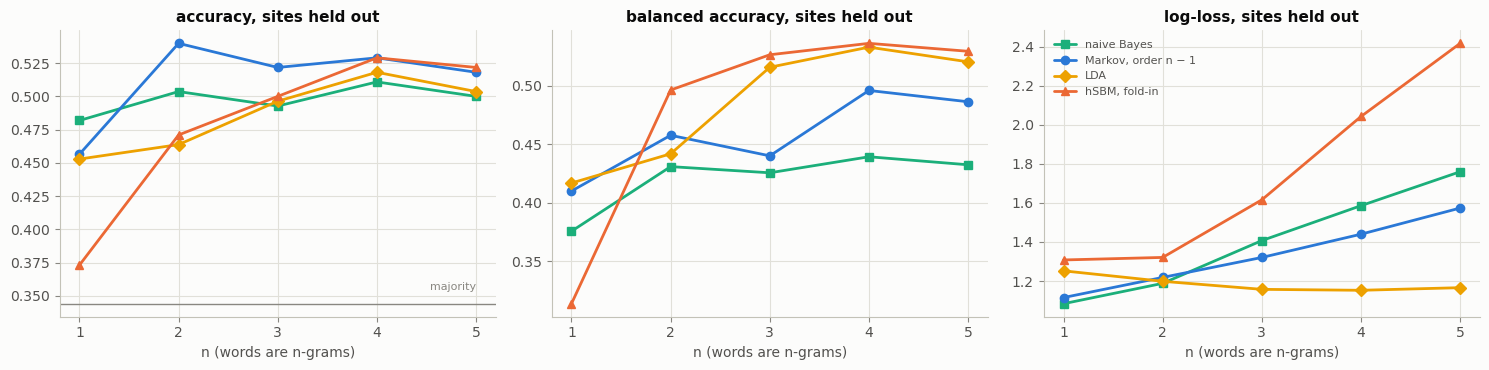

In [48]:
styles_n = {"naive Bayes": (pl.COLORS["MI"], "s"), "Markov, order n − 1": (pl.COLORS["CW"], "o"),
            "LDA": (pl.COLORS["LFG"], "D"), "hSBM, fold-in": (pl.COLORS["EFG"], "^")}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric, title in zip(axes, ["accuracy", "balanced_acc", "log_loss"], ["accuracy", "balanced accuracy", "log-loss"]):
    for name, part in ngram_cv.groupby("model", sort=False):
        color, marker = styles_n[name]
        ax.plot(part["n"], part[metric], color=color, marker=marker, ms=6, label=name)
    ax.set_xticks(range(1, 6)); ax.set_xlabel("n (words are n-grams)"); ax.set_title(f"{title}, sites held out")
axes[0].axhline(majority["BoK (4 classes)"], color=pl.INK["muted"], lw=1)
axes[0].text(5, majority["BoK (4 classes)"] + 0.01, "majority", ha="right", color=pl.INK["muted"], fontsize=8)
axes[2].legend(fontsize=8); fig.tight_layout(); plt.show()

- **Order matters, a little.** Unigrams ($n=1$, order lost) are clearly worst; from $n=2$ on, accuracy stays within a few points (≈ 0.46–0.54), below the variation between seeds and splits seen in Section 7. No window length is clearly best, and none approaches the ceiling.
- **Overcounting.** As predicted, the log-loss of naive Bayes and of the hSBM classifier grows steadily with $n$ — each step is counted $n$ times — while LDA's stays flat.
- **Sparsity.** Larger $n$ means more specific but rarer words (table above); the sequence model with the same statistics (Markov order $n-1$) does as well as any bag model, with far fewer assumptions.

How the fitted models themselves change with $n$ (training split of Section 3): the fit of LDA's matched topics to the empirical distributions, and the structure the hSBM infers.

In [49]:
rows, lda_by_n = [], {}
for n in range(1, 6):
    m = NgramLDA(n).fit(train_df); lda_by_n[n] = m
    phi_n = m.lda.topic_word_dist[[m.mapping[c] for c in BOKS]]
    row = {"n": n, "V_n (training)": len(m.vocabulary),
           "LDA: mean JS(matched φ, empirical) (bits)": np.mean([tm.js_divergence(e, f) for e, f in zip(m.empirical, phi_n)])}
    if RUN_SBM:
        h = NgramSBM(n).fit(train_df)
        levels = [lv for lv in sbm.hierarchy(h.model) if lv["doc_groups"] > 1]
        row.update({"hSBM topics, level 0": levels[0]["word_groups"], "hSBM document groups, level 0": levels[0]["doc_groups"],
                    "hSBM NMI(level-0 groups, culture)": sbm.agreement(sbm.doc_partition(h.model), h.labels)["NMI"],
                    "hSBM levels": len(levels)})
    rows.append(row)
pd.DataFrame(rows).set_index("n")

,V_n (training),"LDA: mean JS(matched φ, empirical) (bits)","hSBM topics, level 0","hSBM document groups, level 0","hSBM NMI(level-0 groups, culture)",hSBM levels
n,,,,,,
1,20,0.009,5,2,0.561,1
2,51,0.031,14,3,0.787,1
3,93,0.032,24,5,0.775,1
4,152,0.038,36,22,0.620,3
5,212,0.048,42,52,0.502,3


LDA's matched topics fit the empirical distributions a little worse as the vocabulary grows. The hSBM infers more topics as $n$ grows (5 → 42), and its pseudo-document groups match the cultures best for pairs and triplets (NMI ≈ 0.78); for $n\ge4$ the sparse words split each culture into many small groups.

The legacy overlay (Section 4.3) for single techniques ($n=1$) and pairs ($n=2$): empirical distribution of each culture vs its matched LDA topic.

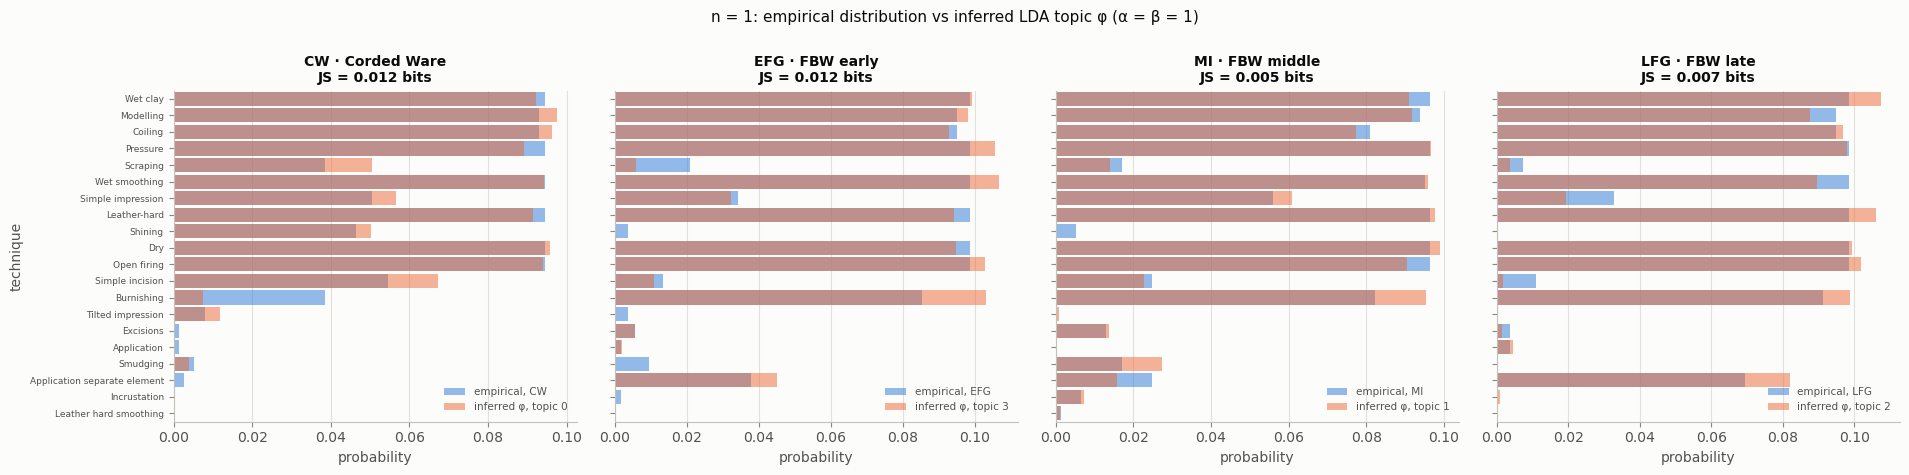

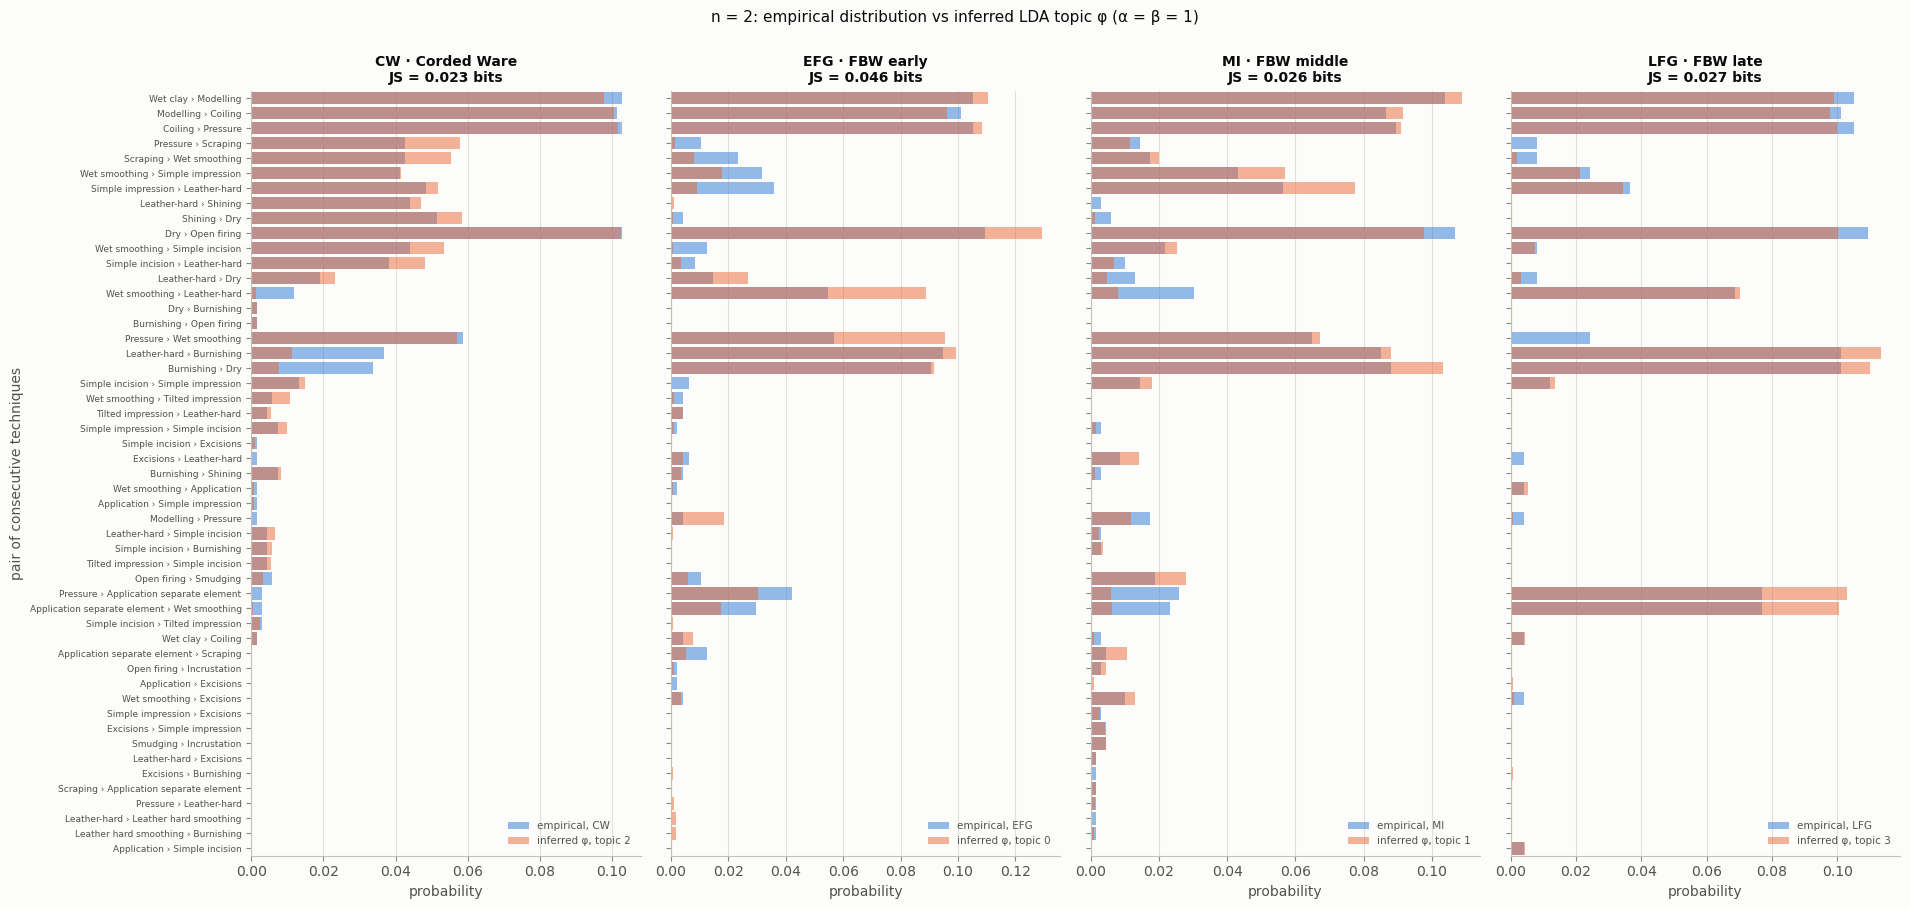

In [50]:
for n, token in [(1, "technique"), (2, "pair of consecutive techniques")]:
    m = lda_by_n[n]
    phi_n = m.lda.topic_word_dist[[m.mapping[c] for c in BOKS]]
    fig = overlay_distributions(m.empirical, phi_n, m.vocabulary, BOKS,
                                [f"inferred φ, topic {m.mapping[c]}" for c in BOKS],
                                f"n = {n}: empirical distribution vs inferred LDA topic φ (α = β = 1)",
                                js=[tm.js_divergence(e, f) for e, f in zip(m.empirical, phi_n)], token=token)
    plt.show()

## 10 · Networks, n-gram networks and sequences

Bags of n-grams ignore the order of the n-grams. Networks and sequence models keep it and give a probability to every whole chain, which is also what reconstruction needs.

### 10.1 The technique network of each BoK
Nodes are techniques ordered left to right by their average position in the chains; an arrow's width is the share of chains using that transition; grey nodes are not used by the BoK.

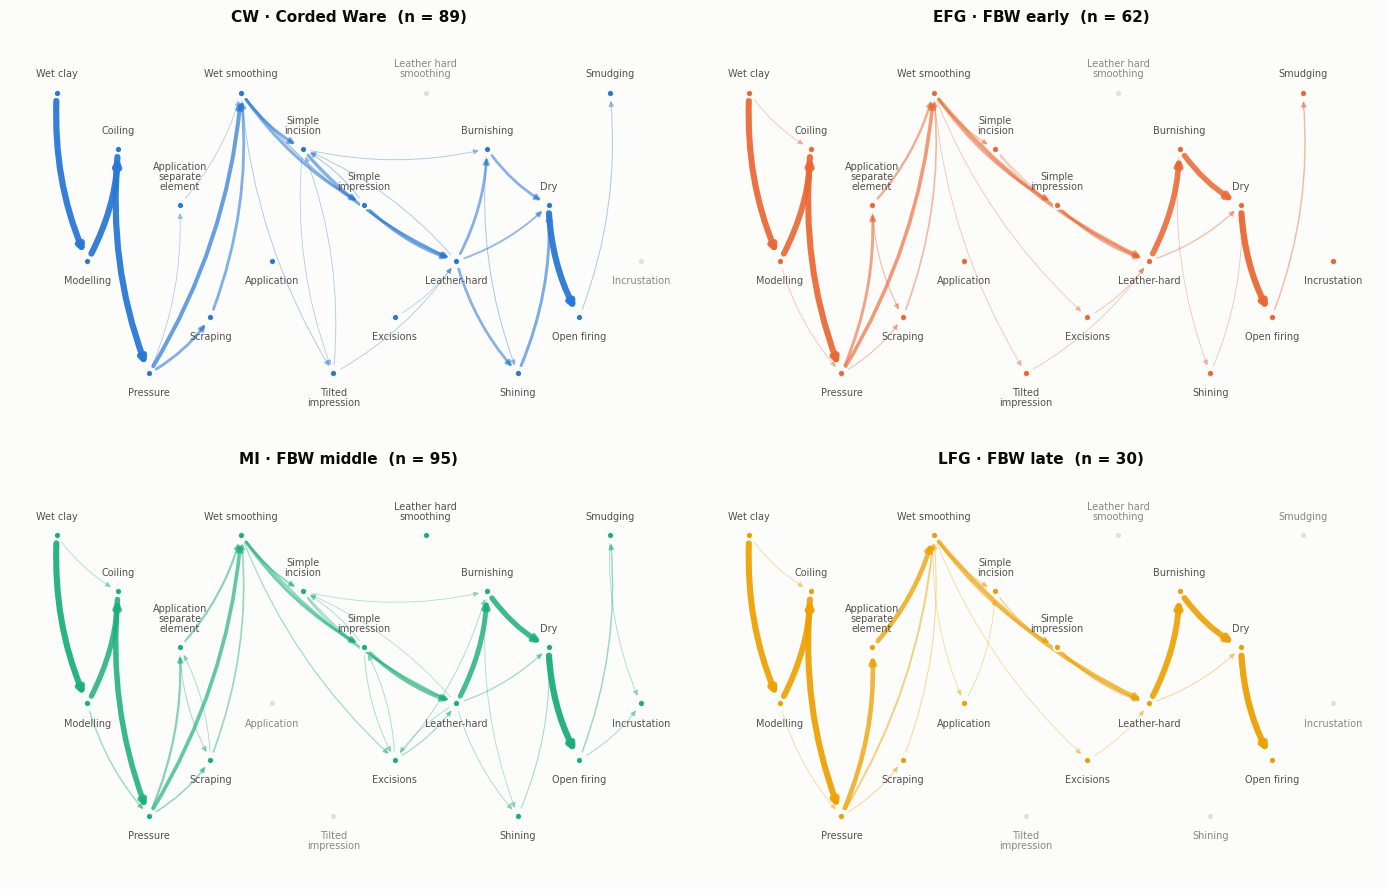

In [51]:
layout = pl.technique_layout(df["steps"])
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, b in zip(axes.flat, BOKS):
    chains = df.loc[df["bok"] == b, "steps"]
    pl.transition_graph(ax, chains, layout, pl.COLORS[b], title=f"{pl.label(b)}  (n = {len(chains)})")
fig.tight_layout(); pl.save(fig, "technique_networks"); plt.show()

### 10.2 Kroon's comparison and what it measures
Pathfinder (Kroon 2024, `module_compare_boks.py`) computes, for each of the 573 links of the technique network, the percentage of chains using it, and compares two BoKs with `scipy.stats.wasserstein_distance(weights_A, weights_B)`. Scipy reads the two lists as **samples of values**: the distance compares the *histograms* of edge usage and ignores **which** edge carries which weight. Relabelling the edges of one BoK leaves it unchanged:

In [52]:
links = pd.read_csv(ROOT / "data/clean/technique_links.csv")
edges = list(zip(links["source"], links["target"]))
groups = {b: list(df.loc[df["bok"] == b, "steps"]) for b in BOKS}
u, v = distances.edge_usage(groups["CW"], edges), distances.edge_usage(groups["MI"], edges)
from scipy.stats import wasserstein_distance
print(f"W(CW, MI)                        = {wasserstein_distance(u, v):.4f}")
print(f"W(CW, MI with edges relabelled)  = {wasserstein_distance(u, np.random.default_rng(1).permutation(v)):.4f}")

W(CW, MI)                        = 0.4392
W(CW, MI with edges relabelled)  = 0.4392


Next to it, two **edge-aware** statistics, each with a permutation test (labels shuffled between the two BoKs, 200 times): the Jensen–Shannon divergence between the two distributions over transitions (bits), and the symmetrised log-likelihood ratio of first-order Markov models fitted to each BoK — a plug-in estimate of the KL divergence between the two chain distributions (nats per chain).

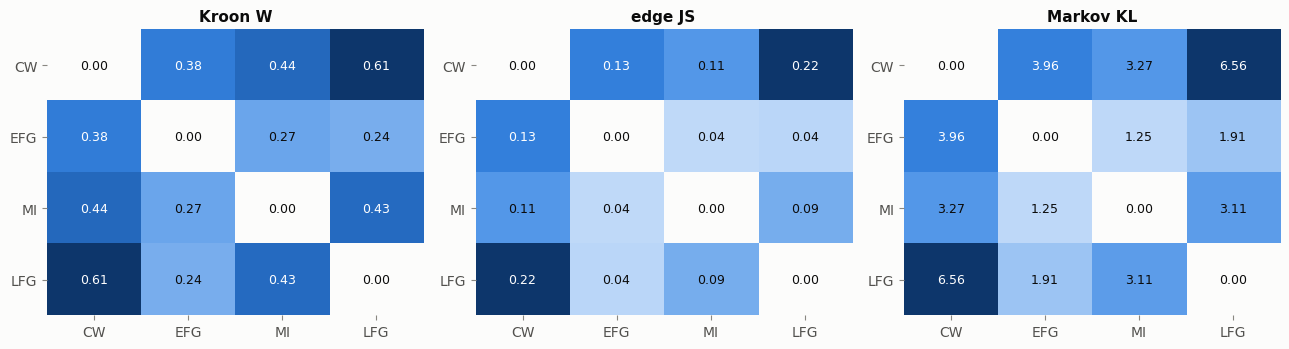

statistic,Kroon W,Markov KL,edge JS
pair,,,
CW–EFG,0.005,0.005,0.005
CW–LFG,0.005,0.005,0.005
CW–MI,0.005,0.005,0.005
EFG–LFG,0.030,0.015,0.055
EFG–MI,0.005,0.005,0.005
MI–LFG,0.005,0.005,0.005


In [53]:
make_markov = lambda chains: markov.MarkovChain(1, beta=2.0, vocab=vocab).fit(chains)
stats = {"Kroon W": lambda a, b: distances.kroon_wasserstein(a, b, edges),
         "edge JS": lambda a, b: distances.edge_js(a, b, edges),
         "Markov KL": lambda a, b: distances.markov_divergence(a, b, make_markov)}
rows = []
for i, a in enumerate(BOKS):
    for b in BOKS[i + 1:]:
        for name, stat in stats.items():
            obs, null, p = distances.permutation_test(stat, groups[a], groups[b], n_perm=200, seed=SEED)
            rows.append({"pair": f"{a}–{b}", "statistic": name, "value": obs, "p": p})
dist_table = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, name in zip(axes, stats):
    M = pd.DataFrame(0.0, index=BOKS, columns=BOKS)
    for r in dist_table[dist_table["statistic"] == name].itertuples():
        a, b = r.pair.split("–")
        M.loc[a, b] = M.loc[b, a] = r.value
    pl.heatmap(ax, M.values, BOKS, BOKS, fmt="{:.2f}"); ax.set_title(name)
fig.tight_layout(); pl.save(fig, "bok_distances"); plt.show()
dist_table.pivot(index="pair", columns="statistic", values="p").round(3)

**How to read it.**
- *Figure:* the three distances for each pair of BoKs.
- *Table:* the permutation p-value of each distance: the share of 200 random relabellings of the two BoKs' vessels giving a distance at least as large, computed as $(1+\#)/(1+200)$. The smallest possible value is $1/201=0.005$, so 0.005 means "never reached by chance in 200 tries".
- *Numbers:* every pair differs under every statistic except early vs late FBW under edge JS (p = 0.055).
- *Caveat:* the permutation shuffles vessels, not sites. Vessels of one site resemble each other, so for the FBW phases (7–14 sites) the p-values are somewhat optimistic.

The statistics agree on the ordering: **CW is farthest from late FBW, and the FBW phases are closest to each other**.

### 10.3 From the technique network to n-gram networks
**Definition.** For $n\ge1$, the *$n$-gram network* $G_n$ has the observed $n$-grams as nodes and an edge $g\to g'$ whenever $g'$ follows $g$ in some chain (the two overlap in $n-1$ steps). Its weight $N(g\to g')$ counts these occurrences, i.e. the $(n+1)$-gram that $g$ and $g'$ form. A start weight $N_{\rm start}(g)$ counts chains beginning with $g$, an end weight $N_{\rm end}(g)$ chains ending with it, and $N_{\rm out}(g)=\sum_{g'}N(g\to g')+N_{\rm end}(g)$. $G_1$ is Kroon's technique network; $G_2$ has pairs as nodes; $G_3$ is the "clustered" triplet graph of the legacy network notebook.

**Proposition 4 (walks on $G_n$ are order-$n$ Markov chains).** Consider the random walk that starts at $g$ with probability $N_{\rm start}(g)/M$ ($M$ chains), moves $g\to g'$ with probability $N(g\to g')/N_{\rm out}(g)$, and stops at $g$ with probability $N_{\rm end}(g)/N_{\rm out}(g)$. It gives every chain the probability of the maximum-likelihood Markov chain of order $n$, with contexts padded by a START symbol.

*Proof.* After emitting $x_t$ the walk is at $g=(x_{t-n+1},\dots,x_t)$. Every occurrence of $g$ is followed either by a step or by END, so $N_{\rm out}(g)$ is the count of the context $g$, and $N(g\to g')/N_{\rm out}(g)=N(x_{t-n+1}\dots x_{t+1})/N(x_{t-n+1}\dots x_t\,\cdot)=\hat p(x_{t+1}\mid x_{t-n+1},\dots,x_t)$ is the order-$n$ estimate; likewise for END. For the first $n$ steps, the count of the padded context $({\rm START}^{\,n-t+1},x_1,\dots,x_{t-1})$ is the number of chains beginning with $x_1\dots x_{t-1}$, so $\prod_{t=1}^{n}\hat p(x_t\mid{\rm START}^{\,n-t+1},x_{1:t-1})$ telescopes to $N_{\rm start}(x_1\dots x_n)/M$. $\square$

**Consequences.** Kroon's edge weights ($G_1$) define the first-order chain; a model of triplet *counts* is second order (walks on $G_2$); count-weighted walks on the legacy triplet graph $G_3$ are **third**-order chains. (With `type_edge_weight='probability'` the legacy code instead gave the $G_3$ edges the first-order weight $p(D\mid C)$.) By the Maximum-Caliber argument (auxiliary notebook, Part 3), walks on $G_n$ are also the Maximum-Caliber models constrained by $(n+1)$-gram counts. The proposition is checked below for $n=1,\dots,5$ on every chain, together with the structure of $G_n$ and of the walk it defines.

In [54]:
def ngram_graph(chains, n):
    """Weights of the n-gram network G_n: start, edge (= (n+1)-gram), end and out-weights."""
    start, edge, end = Counter(), Counter(), Counter()
    for s in chains:
        g = data.ngrams(s, n)
        start[g[0]] += 1; end[g[-1]] += 1
        edge.update(zip(g[:-1], g[1:]))
    out = Counter(end)
    for (a, _), c in edge.items():
        out[a] += c
    return {"start": start, "edge": edge, "end": end, "out": out, "M": len(chains)}

def walk_logprob(G, s, n):
    g = data.ngrams(s, n)
    lp = np.log(G["start"][g[0]] / G["M"]) + np.log(G["end"][g[-1]] / G["out"][g[-1]])
    return lp + sum(np.log(G["edge"][e] / G["out"][e[0]]) for e in zip(g[:-1], g[1:]))

observed_chains = set(map(tuple, df["steps"]))
rows = []
for n in range(1, 6):
    G = ngram_graph(df["steps"], n)
    mle = markov.MarkovChain(n, beta=0.0, alpha=0.0).fit(df["steps"])       # unsmoothed order-n chain
    gap = max(abs(walk_logprob(G, s, n) - mle.logprob(s)) for s in df["steps"])
    assert gap < 1e-9                                                       # Proposition 4
    successors = Counter(a for a, _ in G["edge"]) + Counter(G["end"].keys())    # distinct continuations (incl. END)
    paths, mass = markov.enumerate_paths(mle, max_len=30, min_prob=1e-9)
    rows.append({"n": n, "nodes": len(G["out"]), "edges": len(G["edge"]),
                 "mean continuations per node": np.mean(list(successors.values())),
                 "share of nodes with one continuation": np.mean([v == 1 for v in successors.values()]),
                 "distinct chains the walk produces (p > 1e-9)": len(paths),
                 "walk probability on the 101 observed chains": sum(p for s, p in paths if tuple(s) in observed_chains),
                 "max |log p_walk − log p_Markov|": gap})
pd.DataFrame(rows).set_index("n")

,nodes,edges,mean continuations per node,share of nodes with one continuation,distinct chains the walk produces (p > 1e-9),walk probability on the 101 observed chains,max |log p_walk − log p_Markov|
n,,,,,,,
1,20,52,2.750,0.200,171122,0.658,1.776e-15
2,52,96,1.942,0.538,3799,0.732,1.776e-15
3,96,164,1.781,0.562,1163,0.794,1.776e-15
4,164,235,1.518,0.689,472,0.856,1.776e-15
5,235,292,1.353,0.766,209,0.909,1.776e-15


**How to read it.** One row per $n$-gram network $G_n$. The columns give:
- the numbers of nodes and edges;
- the mean number of continuations per node;
- the share of nodes with a single continuation (no choice);
- how many distinct chains the walk can produce with probability above $10^{-9}$;
- the walk's total probability on the 101 observed chains;
- the largest difference between the walk's and the order-$n$ Markov chain's log-probabilities over all observed chains.

That last value, $1.8\times10^{-15}$, is zero to machine precision (Proposition 4).

Proposition 4 holds to machine precision for every chain and every $n$. As $n$ grows, $G_n$ gains nodes but loses branching: more nodes have a single continuation, and the walk concentrates on the observed chains. From 171 000 producible chains (66 % of the probability on the observed ones) at $n=1$, it falls to about 200 (91 %) at $n=5$ — the walk moves from *generalising* to *memorising*. The networks for CW and MI with techniques, pairs and triplets as nodes (edges used by at least 3 % of the chains; common layout per $n$):

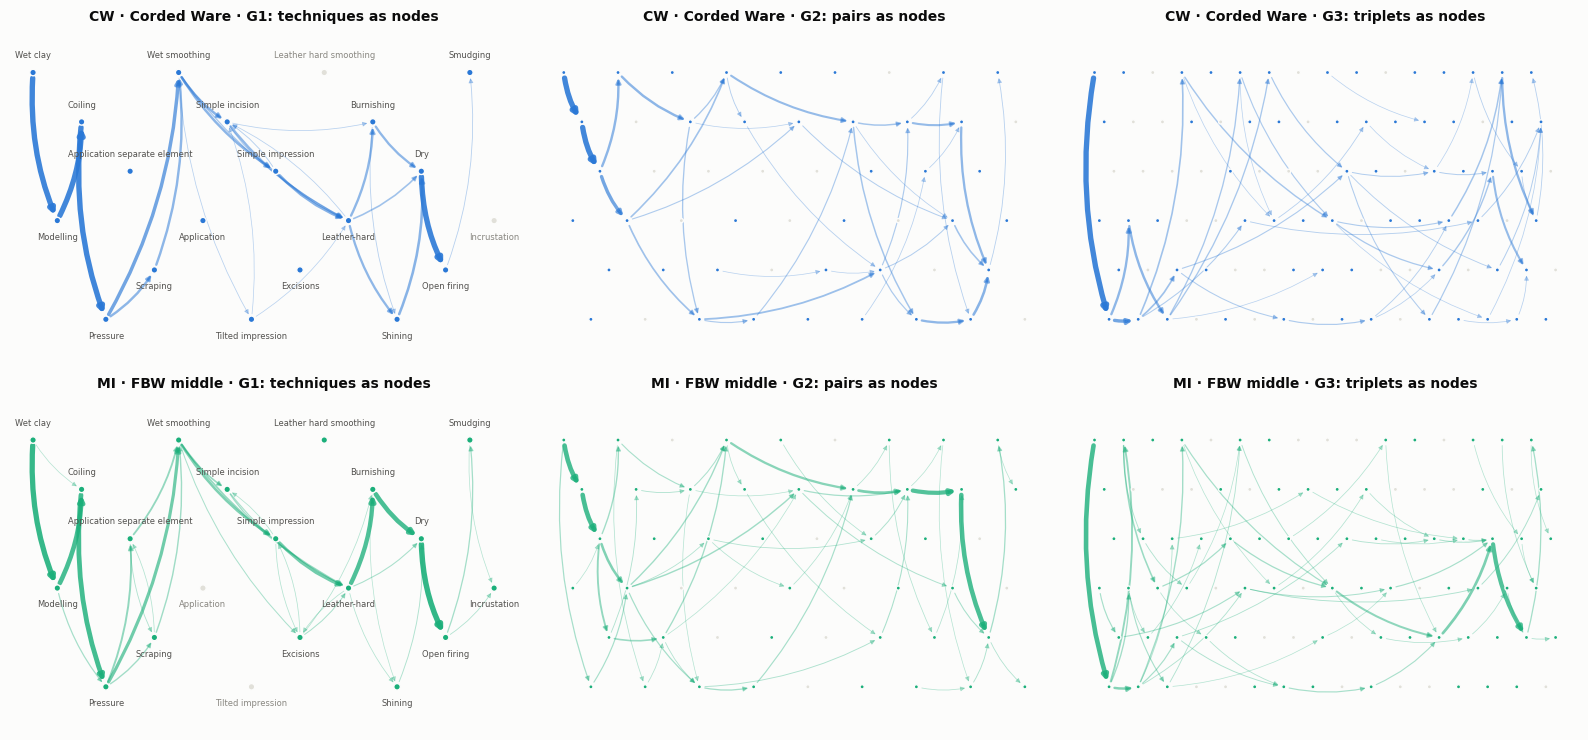

In [55]:
def draw_ngram_graph(ax, chains, layout, n, color, title, min_share=0.03):
    seqs = [data.ngrams(s, n) for s in chains]
    counts = Counter(e for g in seqs for e in zip(g[:-1], g[1:]))
    used = {x for g in seqs for x in g}
    ax.set_axis_off()
    for (a, b), c in counts.items():
        share = c / len(chains)
        if share >= min_share:
            (x0, y0), (x1, y1) = layout[a], layout[b]
            ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                        arrowprops=dict(arrowstyle="-|>", color=color, lw=0.4 + 3.5 * share, alpha=0.3 + 0.6 * share,
                                        shrinkA=4, shrinkB=4, connectionstyle="arc3,rad=0.12", mutation_scale=7))
    keys = list(layout)
    ax.scatter([layout[k][0] for k in keys], [layout[k][1] for k in keys], s=22 if n == 1 else 9, zorder=3,
               color=[color if k in used else pl.INK["grid"] for k in keys], edgecolor=pl.INK["surface"], linewidth=1)
    if n == 1:
        for k in keys:
            x, y = layout[k]
            ax.text(x, y + (0.1 if y >= 0 else -0.1), k[0], ha="center", va="bottom" if y >= 0 else "top",
                    fontsize=6, color=pl.INK["secondary"] if k in used else pl.INK["muted"])
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-1.35, 1.35); ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for j, (n, word) in enumerate([(1, "techniques"), (2, "pairs"), (3, "triplets")]):
    layout_n = pl.technique_layout([data.ngrams(s, n) for s in df["steps"]])
    for i, b in enumerate(["CW", "MI"]):
        draw_ngram_graph(axes[i, j], groups[b], layout_n, n, pl.COLORS[b], f"{pl.label(b)} · G{n}: {word} as nodes")
fig.tight_layout(); plt.show()

**Entropy rate: memorisation vs structure.** Order $k$ corresponds to walks on $G_k$ ($k=0$: techniques drawn independently). The in-sample (plug-in) entropy rate $\hat h_k=-\frac1T\sum\log_2\hat p_k(x_t\mid\text{context})$ over all $T$ predicted symbols (END included) cannot increase with $k$. Under the empirical measure, with START padding, the order-$(k+1)$ context refines the order-$k$ context on the same positions, and conditioning cannot increase entropy (Cover & Thomas 2006, Thm 2.6.5). So $\hat h_k$ measures memorisation. The honest measure is the held-out cross-entropy (5-fold, smoothing $\beta$ chosen per order), without and with Kroon's grammar. The same held-out log-likelihoods give the paired comparison between orders in nats per chain.

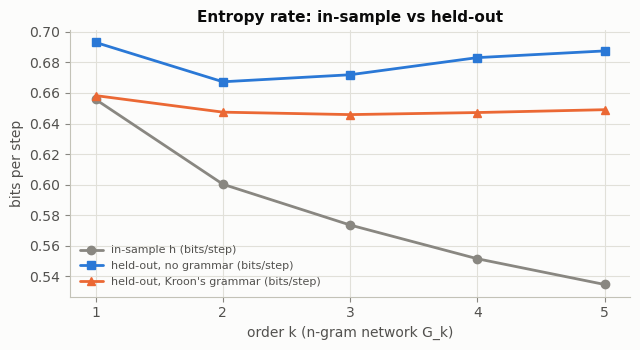

,in-sample h (bits/step),"held-out, no grammar (bits/step)","held-out, Kroon's grammar (bits/step)"
order k (walk on G_k),,,
0,3.864,3.867,1.294
1,0.656,0.693,0.658
2,0.600,0.667,0.647
3,0.574,0.672,0.646
4,0.551,0.683,0.647
5,0.535,0.688,0.649


,best beta,held-out log-lik / chain (nats),difference vs order 1,se of difference
order,,,,
0,0.5,-10.247,-5.033,0.135
1,8.0,-5.214,0.000,0.000
2,32.0,-5.128,0.086,0.026
3,32.0,-5.116,0.099,0.042
4,32.0,-5.126,0.088,0.054
5,32.0,-5.141,0.073,0.065


In [56]:
folds = ev.splits(df, "stratified", 5, SEED)
T_sym = sum(len(s) + 1 for s in df["steps"])                 # predicted symbols, END included
heldout = {}                                                  # (order, grammar?, beta) -> held-out log-lik of every vessel
for k in range(0, 6):
    for use_grammar in (False, True):
        for beta in [0.5, 2, 8, 32, 128]:
            ll = np.zeros(len(df))
            for tr, te in folds:
                m = markov.MarkovChain(k, beta, grammar=grammar if use_grammar else None, vocab=vocab).fit(df["steps"].iloc[tr])
                ll[te] = [m.logprob(s) for s in df["steps"].iloc[te]]
            heldout[(k, use_grammar, beta)] = ll
best_beta = {(k, g_): max((b for (kk, gg, b) in heldout if (kk, gg) == (k, g_)), key=lambda b: heldout[(k, g_, b)].mean())
             for k in range(6) for g_ in (False, True)}
bits = lambda ll: -ll.sum() / T_sym / np.log(2)
h_in = [-sum(markov.MarkovChain(k, beta=0.0, alpha=0.0).fit(df["steps"]).logprob(s) for s in df["steps"]) / T_sym / np.log(2)
        for k in range(6)]
assert np.all(np.diff(h_in) <= 1e-12)                          # in-sample entropy rate is non-increasing in k
entropy = pd.DataFrame({"in-sample h (bits/step)": h_in,
                        "held-out, no grammar (bits/step)": [bits(heldout[(k, False, best_beta[(k, False)])]) for k in range(6)],
                        "held-out, Kroon's grammar (bits/step)": [bits(heldout[(k, True, best_beta[(k, True)])]) for k in range(6)]},
                       index=pd.Index(range(6), name="order k (walk on G_k)"))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for col, color, marker in zip(entropy.columns, [pl.INK["muted"], pl.COLORS["CW"], pl.COLORS["EFG"]], ["o", "s", "^"]):
    ax.plot(entropy.index[1:], entropy[col].iloc[1:], color=color, marker=marker, ms=6, label=col)
ax.set_xticks(range(1, 6)); ax.set_xlabel("order k (n-gram network G_k)"); ax.set_ylabel("bits per step")
ax.set_title("Entropy rate: in-sample vs held-out"); ax.legend(fontsize=8); fig.tight_layout(); plt.show()
ref = heldout[(1, True, best_beta[(1, True)])]
paired = pd.DataFrame([{"order": k, "best beta": best_beta[(k, True)],
                        "held-out log-lik / chain (nats)": heldout[(k, True, best_beta[(k, True)])].mean(),
                        "difference vs order 1": (heldout[(k, True, best_beta[(k, True)])] - ref).mean(),
                        "se of difference": (heldout[(k, True, best_beta[(k, True)])] - ref).std() / np.sqrt(len(df))}
                       for k in range(6)]).set_index("order")
display(entropy.round(4))
paired

The in-sample entropy rate falls monotonically, as it must, from 3.86 bits for independent techniques to 0.53 bits at order 5. The held-out cross-entropy instead has a minimum. Without the grammar it is lowest at order 2 (walks on $G_2$, triplet statistics); with Kroon's grammar, which already removes impossible continuations, orders 2–5 are indistinguishable (0.646–0.649 bits per step). In the paired comparison they gain 0.07–0.10 nats per chain over order 1, but only order 2 clearly so (0.086 ± 0.026, 3.3 standard errors); the uncertainty grows with the order. **Pairs capture most of the sequential structure, triplets add a little, longer windows only memorise.**

**Separation between BoKs as the window grows.** Divergence between the BoKs' transition distributions on $G_n$ (edge JS, as in 10.2), with a permutation null (labels shuffled, 200 times). Raw divergences grow with $n$ for every pair — including under the null, because the edges become sparser — so the comparison is made through the $z$-score $(\mathrm{JS}-\overline{\mathrm{JS}}_{\rm null})/\mathrm{sd}_{\rm null}$.

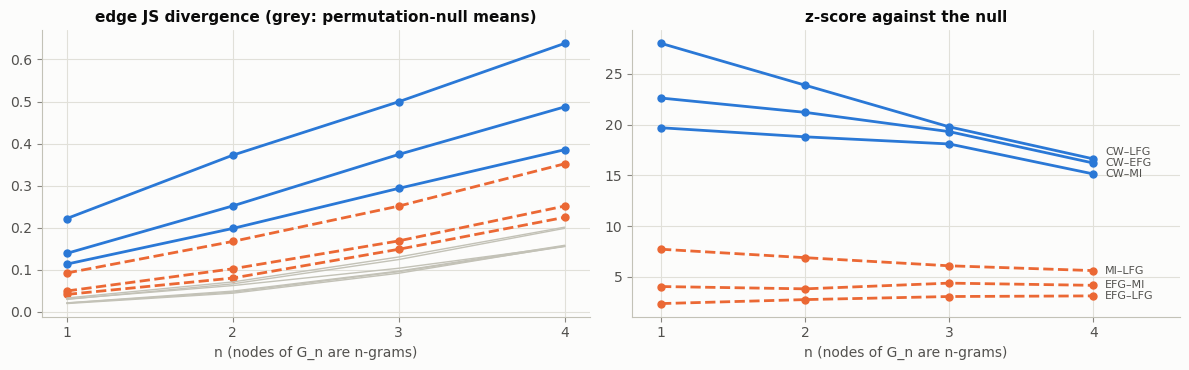

n,1,2,3,4
pair,,,,
CW–EFG,0.005,0.005,0.005,0.005
CW–LFG,0.005,0.005,0.005,0.005
CW–MI,0.005,0.005,0.005,0.005
EFG–LFG,0.025,0.010,0.005,0.005
EFG–MI,0.005,0.010,0.010,0.010
MI–LFG,0.005,0.005,0.005,0.005


In [57]:
rows = []
for n in range(1, 5):
    seqs = {b: [data.ngrams(s, n) for s in groups[b]] for b in BOKS}
    E = sorted({e for b in BOKS for g in seqs[b] for e in zip(g[:-1], g[1:])}, key=str)
    for i, a in enumerate(BOKS):
        for b in BOKS[i + 1:]:
            obs_js, null, p = distances.permutation_test(lambda A, B: distances.edge_js(A, B, E), seqs[a], seqs[b], 200, SEED)
            rows.append({"n": n, "pair": f"{a}–{b}", "JS (bits)": obs_js, "null mean": null.mean(),
                         "z": (obs_js - null.mean()) / null.std(), "p": p})
separation = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
label_y = {}
for pair, part in separation.groupby("pair", sort=False):
    fbw_internal = "CW" not in pair
    style = dict(color=pl.COLORS["EFG"] if fbw_internal else pl.COLORS["CW"], ls="--" if fbw_internal else "-", marker="o", ms=5)
    axes[0].plot(part["n"], part["JS (bits)"], **style)
    axes[0].plot(part["n"], part["null mean"], color=pl.INK["axis"], lw=1)
    axes[1].plot(part["n"], part["z"], **style)
    label_y[pair] = part["z"].iloc[-1]
placed = []                                                    # direct labels, spaced so they do not collide
for pair, y in sorted(label_y.items(), key=lambda kv: kv[1]):
    y = max(y, placed[-1] + 1.1) if placed else y
    placed.append(y)
    axes[1].text(4.08, y, pair, fontsize=8, va="center", color=pl.INK["secondary"])
axes[0].set_title("edge JS divergence (grey: permutation-null means)"); axes[1].set_title("z-score against the null")
for ax in axes:
    ax.set_xticks(range(1, 5)); ax.set_xlabel("n (nodes of G_n are n-grams)")
axes[1].set_xlim(0.8, 4.6); fig.tight_layout(); plt.show()
separation.pivot(index="pair", columns="n", values="p")

**How to read it.**
- *Left figure:* the edge-JS divergence of each pair of BoKs (blue solid: CW vs an FBW phase; orange dashed: two FBW phases) and the means of its permutation null (grey).
- *Right figure:* the separation $z$ of each pair, in standard deviations of its null.
- *Table:* the permutation p-values, as in 10.2 (0.005 = never reached in 200 permutations).
- *Numbers:* every pair is significant at every $n$ (largest p = 0.025, early vs late FBW at $n=1$). The CW pairs fall from $z$ = 20–28 to 15–17; the FBW pairs stay at 2.4–7.8.

Raw divergences grow with $n$, but so does the null. Against the null, the separation of CW from the FBW phases is strongest for single transitions and *decreases* with $n$, while the FBW phases stay weakly separated at every $n$. Longer windows do not reveal sharper cultural contrasts; they spread the same evidence over sparser edges.

### 10.4 Posterior predictive check
Walks from the fitted models, with an explicit `END` symbol and Kroon's grammar (the legacy walks stopped with the unconditional share of chains ending at a node, inverted in one version):

order 1: 70% of simulated chains were observed; 657 distinct simulated chains
order 2: 72% of simulated chains were observed; 581 distinct simulated chains


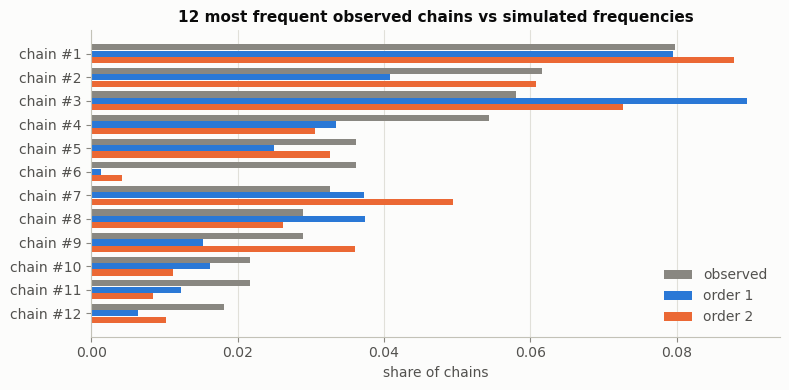

In [58]:
rng = np.random.default_rng(SEED)
emp = df["chain"].value_counts(normalize=True)
sim = {}
for order, beta in [(1, 2.0), (2, 8.0)]:
    m = markov.MarkovChain(order, beta, grammar=grammar, vocab=vocab).fit(df["steps"])
    walks = pd.Series([" > ".join(m.sample(rng)) for _ in range(5000)])
    sim[f"order {order}"] = walks.value_counts(normalize=True)
    print(f"order {order}: {walks.isin(set(df['chain'])).mean():.0%} of simulated chains were observed; "
          f"{walks.nunique()} distinct simulated chains")
top_chains = emp.index[:12]
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(top_chains))
ax.barh(y - 0.27, emp[top_chains], height=0.26, color=pl.INK["muted"], label="observed")
ax.barh(y, sim["order 1"].reindex(top_chains).fillna(0), height=0.26, color=pl.COLORS["CW"], label="order 1")
ax.barh(y + 0.27, sim["order 2"].reindex(top_chains).fillna(0), height=0.26, color=pl.COLORS["EFG"], label="order 2")
ax.set_yticks(y, [f"chain #{i + 1}" for i in range(len(top_chains))]); ax.invert_yaxis()
ax.set_xlabel("share of chains"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("12 most frequent observed chains vs simulated frequencies"); fig.tight_layout(); plt.show()

**How to read it.**
- *Printed lines:* 5000 chains sampled from the Markov models fitted to all vessels, within Kroon's grammar. 70 % (order 1) and 72 % (order 2) of them are chains that were actually observed; the rest are new but grammatical combinations.
- *Figure:* the 12 most frequent observed chains (grey) and how often each model produces them. Both models get most of the frequent chains roughly right. Chain #6 is almost never produced (0.1–0.4 %, against 3.6 % observed): its transitions are individually rare even though the whole chain is common.
- *Caveat:* this is an in-sample check, since the models were fitted on these chains.

### 10.5 Attribution from fragments
A Markov model scores an unfinished chain by marginalising over its continuations (`logprob(steps, complete=False)`). Accuracy when only the first $t$ steps are known (sites held out, order 1):

In [59]:
site_folds = ev.splits(df, "site", 5, SEED)
rows = []
for t in [3, 4, 5, 6, 7, 8, None]:
    pred = np.zeros((len(df), len(BOKS)))
    for tr, te in site_folds:
        m = clf.MarkovClassifier(1, 2.0, grammar=grammar).fit(df.iloc[tr])
        part = df.iloc[te].copy()
        if t is not None:
            part["steps"] = part["steps"].map(lambda s: s[:t])
        pred[te] = m.predict_proba(part, complete=t is None)
    rows.append({"known steps": "all" if t is None else t, "accuracy": ev.scores(y_bok, pred)["accuracy"]})
pd.DataFrame(rows).set_index("known steps").T

known steps,3,4,5,6,7,8,all
accuracy,0.366,0.37,0.417,0.464,0.489,0.514,0.533


**How to read it.**
- *Shown:* accuracy when only the first $t$ steps of each held-out vessel are known (sites held out, seed 0, order-1 Markov model).
- *Numbers:* 0.37 with 3–4 steps (the majority rule gives 0.34), rising steadily to 0.51 with 8 steps and 0.53 with the whole chain.
- *Evidence:* with ± 0.04–0.05 per value the trend is clear, but the step-to-step differences are not.

The first three or four steps (wet clay, modelling, coiling, pressure) are shared by everyone and give the majority baseline; accuracy grows as finishing, decoration and surface treatment become known.

### 10.6 Reconstructing incomplete chains (Question 2)
Given the steps before and after a gap, the most probable fillers are found exactly by uniform-cost search (`MarkovChain.complete`), within Kroon's grammar (extended with the one observed transition absent from his link list, `Application separate element → Scraping`, 12 vessels). Masking experiment: for each held-out vessel (5-fold CV) hide a random block of $m=1,2,3$ steps and check whether the true block is the top-1 or among the top-3 proposals. Baseline: the most frequent training chains matching the known prefix and suffix.

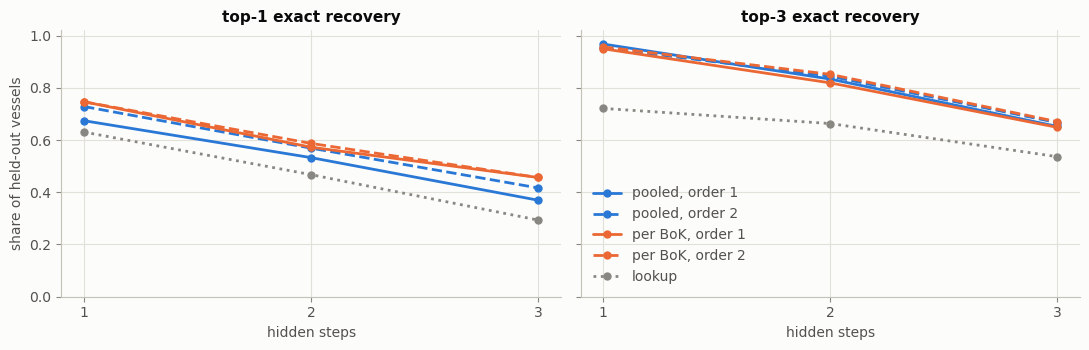

gap                   1             2             3       
metric            top-1  top-3  top-1  top-3  top-1  top-3
model                                                     
lookup            0.630  0.721  0.467  0.663  0.293  0.536
per BoK, order 1  0.746  0.949  0.572  0.819  0.457  0.649
per BoK, order 2  0.746  0.957  0.587  0.851  0.457  0.670
pooled, order 1   0.674  0.967  0.533  0.833  0.370  0.652
pooled, order 2   0.728  0.953  0.569  0.844  0.417  0.667

In [60]:
gaps = reconstruction.gap_experiment(df, grammar, ev.splits(df, "stratified", 5, SEED), gap_sizes=(1, 2, 3), k=3, seed=SEED)
gap_table = reconstruction.summarise_gaps(gaps)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
styles = {"pooled, order 1": (pl.COLORS["CW"], "-"), "pooled, order 2": (pl.COLORS["CW"], "--"),
          "per BoK, order 1": (pl.COLORS["EFG"], "-"), "per BoK, order 2": (pl.COLORS["EFG"], "--"),
          "lookup": (pl.INK["muted"], ":")}
for ax, metric in zip(axes, ["top-1", "top-3"]):
    for name, (color, ls) in styles.items():
        ax.plot([1, 2, 3], gap_table.xs(metric, axis=1, level="metric").loc[name].values,
                color=color, ls=ls, marker="o", ms=5, label=name)
    ax.set_xticks([1, 2, 3]); ax.set_xlabel("hidden steps"); ax.set_title(f"{metric} exact recovery")
axes[0].set_ylabel("share of held-out vessels"); axes[0].set_ylim(0, 1.02); axes[1].legend(loc="lower left")
fig.tight_layout(); pl.save(fig, "reconstruction"); plt.show()
gap_table

**How to read it.**
- *Shown:* for held-out vessels (5-fold by vessel, seed 0), a random block of 1, 2 or 3 consecutive steps is hidden.
  - *top-1:* the model's best proposal is exactly the hidden block;
  - *top-3:* the hidden block is among the three best proposals.

  Rows: the lookup of matching training chains, and Markov models of order 1 and 2, either per BoK (true BoK known) or pooled.
- *Numbers:*
  - one hidden step: the Markov models score 0.67–0.75 top-1 and 0.95–0.97 top-3, against 0.63 / 0.72 for the lookup;
  - three hidden steps: 0.37–0.46 top-1 and 0.65–0.67 top-3.
- *Caveat:* vessels (not sites) are held out, so site-mates are in the training data. "Per BoK" uses the true BoK, an optimistic assumption for a new find.

In [61]:
# Worked example: a CW vessel whose decoration and surface treatment are hidden
v = df[df["bok"] == "CW"].iloc[1]
s = list(v["steps"])
i, j = s.index("Wet smoothing") + 1, s.index("Dry")
m_cw = markov.MarkovChain(1, 2.0, grammar=grammar, vocab=vocab).fit(
    df.loc[(df["bok"] == "CW") & (df["vessel_id"] != v["vessel_id"]), "steps"])
print("known  :", " > ".join(s[:i]), "> [ ? ] >", " > ".join(s[j:]))
print("hidden :", " > ".join(s[i:j]))
print("top-5 fillers from a CW model fitted without this vessel (probabilities renormalised over the 5):")
fills = m_cw.complete(s[:i], s[j:], k=5)
z = sum(np.exp(lp) for _, lp in fills)
for fill, lp in fills:
    print(f"  {np.exp(lp) / z:.2f}  {' > '.join(fill)}{'   <- true' if fill == s[i:j] else ''}")

known  : Wet clay > Modelling > Coiling > Pressure > Scraping > Wet smoothing > [ ? ] > Dry > Open firing
hidden : Simple impression > Leather-hard > Shining
top-5 fillers from a CW model fitted without this vessel (probabilities renormalised over the 5):
  0.23  Simple impression > Leather-hard > Shining   <- true
  0.21  Simple impression > Leather-hard > Burnishing
  0.21  Simple incision > Leather-hard > Shining
  0.19  Simple incision > Leather-hard > Burnishing
  0.15  Simple impression > Leather-hard


Knowing the BoK improves the first guess; order 2 adds little over order 1. All Markov models beat the lookup of matching training chains, which cannot propose unseen combinations. In practice: attribute first (Section 7), then complete with that BoK's model, or average over the BoK posterior.

### 10.7 Influence between the cultures, and time
**What "influence" would mean.** Take a technique $\tau$ typical of FBW, for example burnishing (88 % of FBW vessels, 43 % of CW). "FBW potters influenced CW potters" means that a CW vessel is more likely to carry $\tau$ when its makers were in contact with FBW potters:
$$\operatorname{logit}P(\tau_i=1\mid c_i=\mathrm{CW})=a+b\,E_i,\qquad H_0:\ b=0.$$
The *exposure* $E_i$ measures contact: FBW potters living at the same time and nearby. For example,
$$E_i=\sum_{j\in\mathrm{FBW}}K\!\left(d_{ij}/h\right)\,\mathbf 1\big[\,|t_i-t_j|<\Delta\,\big],$$
with $d_{ij}$ the distance between find spots, $t$ the date, $K$ a kernel of width $h$ and $\Delta$ a time window.

**Why similarity is not enough.** CW and FBW share chains (1.2) and topics (5.3). But write the CW practice as a mixture,
$$p_{\rm CW}=(1-\varepsilon)\,p^0_{\rm CW}+\varepsilon\,p_{\rm FBW},$$
where $p^0_{\rm CW}$ — CW without contact — is unknown. Then any $\varepsilon$ fits the data for a suitable $p^0_{\rm CW}$. As with survival (auxiliary notebook, Prop. 3), the effect is identified only against a reference without contact: earlier, or farther away. Shared function (beakers) and shared inheritance also produce similarity.

**Is time in the metadata?** Not per vessel.
- Relative time is only in the labels: EFG → MI → LFG are successive FBW phases, and CW is not subdivided.
- Kroon's Appendix A (`data/source/dans/Appendices/Appendix_A_Radiocarbon_dates/`) has 62 radiocarbon dates from 35 sites (16 CW, 44 FBW, 2 AOO). They are tied to sites and typochronological horizons, not to our vessels, and only 7 of their site names match ours exactly. Building $t_i$ means dating the sites, from these dates and the typochronology.

**What the data allow now: space only.** With $\Delta=\infty$, the exposure reduces to the distance from a CW vessel's site to the nearest FBW site. We use either all FBW phases, or late FBW only — the phase that co-existed with CW (Kroon et al. 2025, *Parallel societies*). For five techniques, the test correlates their presence in CW vessels with nearness (Spearman), and judges the correlation against 999 random reassignments of the CW site locations (site-level permutation).

In [ ]:
from scipy.stats import spearmanr

def haversine(lat1, lon1, lat2, lon2):
    """Great-circle distance in km."""
    r = np.pi / 180
    a = np.sin((lat2 - lat1) * r / 2) ** 2 + np.cos(lat1 * r) * np.cos(lat2 * r) * np.sin((lon2 - lon1) * r / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

geo = df.dropna(subset=["latitude"])
cw = geo[geo["bok"] == "CW"]
rows, rng = [], np.random.default_rng(SEED)
for target, mask in [("any FBW site", geo["bok"] != "CW"), ("late-FBW site", geo["bok"] == "LFG")]:
    fbw = geo[mask].drop_duplicates("site_id")
    nearness = pd.Series([-haversine(la, lo, fbw["latitude"].values, fbw["longitude"].values).min()
                          for la, lo in zip(cw["latitude"], cw["longitude"])], index=cw.index)    # − km to the nearest
    per_site = nearness.groupby(cw["site_id"]).first()
    for tech in ["Burnishing", "Application separate element", "Scraping", "Shining", "Smudging"]:
        has = cw["steps"].map(lambda s, t=tech: t in s).astype(int)
        rho = spearmanr(has, nearness).correlation
        null = []
        for _ in range(999):                                      # shuffle locations between CW sites
            moved = dict(zip(per_site.index, rng.permutation(per_site.values)))
            null.append(spearmanr(has, cw["site_id"].map(moved)).correlation)
        rows.append({"technique": tech, "in CW": has.mean(),
                     "in FBW": df.loc[df["bok"] != "CW", "steps"].map(lambda s, t=tech: t in s).mean(),
                     "nearness to": target, "ρ": rho, "p": (1 + np.sum(np.array(null) >= rho)) / 1000})
influence = pd.DataFrame(rows).pivot(index=["technique", "in CW", "in FBW"], columns="nearness to", values=["ρ", "p"])
print(f"{len(cw)} CW vessels at {cw['site_id'].nunique()} sites; ρ > 0: the technique is more frequent closer to FBW")
influence.round(3)

86 CW vessels at 62 sites; ρ > 0: the technique is more frequent closer to FBW


ρ                \
nearness to                               any FBW site late-FBW site   
technique                    in CW in FBW                              
Application separate element 0.023 0.412         0.109         0.187   
Burnishing                   0.430 0.877         0.076         0.094   
Scraping                     0.395 0.187        -0.104        -0.182   
Shining                      0.430 0.048        -0.045        -0.106   
Smudging                     0.058 0.123        -0.090         0.034   

                                                     p                
nearness to                               any FBW site late-FBW site  
technique                    in CW in FBW                             
Application separate element 0.023 0.412         0.172         0.054  
Burnishing                   0.430 0.877         0.263         0.173  
Scraping                     0.395 0.187         0.815         0.938  
Shining                      0.430 0.048         0.673         0.785  
Smudging                     0.058 0.123         0.784         0.403

**How to read it.** One row per technique, with its share among CW vessels and among FBW vessels. $\rho$ is the rank correlation between "the CW vessel has the technique" and the nearness of its site to an FBW site; $p$ is the one-sided permutation p-value (a $\rho$ at least this large by chance).
- *Evidence:* no correlation is beyond chance. The smallest p, 0.05, is for separately applied elements near late-FBW sites — a technique found in only 2 of the 86 CW vessels, and one of 10 tests.
- *Direction:* the signs are those that influence would predict, but this is suggestive, not evidence.
  - The FBW-typical techniques (applied elements, burnishing) are slightly more frequent in CW vessels near FBW sites ($\rho$ = +0.08 to +0.19).
  - The CW-typical ones (scraping, shining) are slightly less frequent there ($\rho$ = −0.05 to −0.18).
- *Limits:*
  - There is no time: an early or middle FBW site nearby may be centuries older than the CW vessel.
  - The sample is 86 vessels at 62 sites.
  - Form and context are not controlled.

  A real test needs dated sites ($t_i$), a contact-free reference, and vessel form in the model.


## 11 · Critical assessment

Issues found in the legacy notebooks, their effect, and where they are addressed.

| # | Legacy function / step | Issue | Effect | Here |
|---|---|---|---|---|
| 1 | `create_resampled_documents` (cell 5) | pools vessels of the same label; unseeded | label information enters an unsupervised model; results change every run | seeded; built from training vessels only; permutation control (7.1) |
| 2 | evaluation (cells 29, 83–85) | tested on vessels inside the training pseudo-documents; no site grouping | optimistic, irreproducible accuracy | held-out sites (3) and cross-validation (7.3) |
| 3 | `remove_common_triplets` (cell 3) | computed on all vessels; edited documents in place — the two held-out vessels per culture kept the stop triplets; deletes the most frequent triplets, which are informative | leakage; train and test featurised differently; signal deleted | computed on training vessels; copies returned; information of every triplet (4.1); deletion by frequency vs information (7.4) |
| 4 | empirical distributions (cells 11, 18, 61, 80) | recomputed four times over three vocabulary orders, including held-out vessels | inconsistent comparisons | `get_empirical_word_distribution`, one vocabulary |
| 5 | `matching_empirical` (cell 24) | independent argmin per culture | two cultures on one topic | one-to-one Hungarian matching (4.3) |
| 6 | `classify_new_vessel` (cell 29) | mapping looked up the wrong way round | always returned "Topic_k" | fixed (4.7) |
| 7 | `LDA_manual.transform` (cell 14) | random Dirichlet start | predictions changed between calls | uniform start |
| 8 | `sbmtm.fit` only (cell 35) | one start, no refinement | a sub-optimal partition read as the result | several starts + merge-split refinement (5.1) |
| 9 | "combination of topics" (cells 64–69) | compared 0/1 group memberships with binarised word sets, greedy search | not a probabilistic comparison | $p(w\mid c)=\sum_t p(w\mid t)p(t\mid c)$ (5.3) |
| 10 | soft memberships (cell 44), overlapping SBM (cell 36) | hard partition read as membership; overlapping fit failed | no uncertainty | posterior marginals (5.4); overlapping model on single vessels + MDL comparison (7.2) |
| 11 | `infer_new_doc_membership` (cell 86) | edited the fitted graph in place; wrong state size; never run | — | fold-in by description length (5.5), tested against full recomputation |
| 12 | `classify_vessel_simple` (cell 84) | overlapping triplets as independent evidence | over-confident ("High, 100 %") | calibration reported (7.3) |
| 13 | seeds | `gt.seed_rng(0)` means *random* in graph-tool; global numpy seeds | irreproducible fits | seed offset in `fit_hsbm`; local generators; tests |
| 14 | `cluster_nodes` (network notebook) | with `'probability'` weights the triplet graph carries the first-order $p(D\mid C)$; with count weights its walks are *third*-order chains | the "triplet" model is not of the order it appears to be | walks on $G_n$ = order-$n$ chains, proved and verified (10.3) |
| 15 | random walks (network notebook) | unconditional end frequencies, inverted in one version | wrong path distribution | END symbol and grammar (10.4) |
| 16 | "transfer entropy" (network notebook) | not a transfer entropy | — | edge-JS and Markov KL with permutation tests (10.2) |
| 17 | Kroon's Wasserstein | invariant to relabelling edges | cannot tell which techniques differ | edge-aware distances (10.2) |
| 18 | labels | BoK confounded with vessel form and burial context | accuracy may reflect form or context | form baselines (7.5); context as a selection model, with its assumptions (auxiliary notebook, 2.4–2.5); form, place and context as extra words in the topic models (8) |
| 19 | class-balanced bootstrap + symmetric Dirichlet | discards the survivor proportions $p(c\mid S=1)$; implicitly optimises balanced accuracy | lower accuracy; selection ignored | selection-consistent priors, prior shift, find context (auxiliary notebook, Part 2) |
| 20 | triplets only | window length never examined | — | n = 1…5 in the topic models (9) and n-gram networks (10.3) |
| 21 | records as complete chains | eroded steps read as never made | biased practice estimates; weaker attribution of eroded vessels | deletion channel, survival per site by EM (auxiliary notebook, Part 4) |

**Limits no method removes.** 276 vessels and 101 distinct chains; identical chains across BoKs cap accuracy at about 73 % (4 classes) and 89 % (CW vs FBW); FBW phase is confounded with burial context; chains are recorded macroscopically; survival and selection cannot be identified from the survivors alone (auxiliary notebook, Prop. 3 and Cor. 5).

## 12 · Conclusions, next steps, data and references

1. **Replication.** Once seeded and fitted on training vessels only, the legacy procedures run consistently and reproduce the legacy in-sample figures (hSBM 0.64 vs 0.65). The corrected functions and the graph-tool workflow (several starts, refinement, posterior sampling, fold-in by description length) make the hSBM results reproducible and interpretable.
2. **Solidity.** Moving from in-sample to held-out sites costs 7–12 points under cross-validation; pooled pseudo-documents produce a large part of the cultural separation the topic models display (7.1); single vessels show only weak cultural structure (7.2).
3. **Attribution works, modestly.** ≈ 0.5 accuracy for four BoKs and ≈ 0.8 for CW vs FBW on unseen sites, close to what vessel form alone gives; the chain adds information beyond form, mainly within FBW. Report baselines (majority, form, ceiling) and leave-sites-out results with every attribution claim.
4. **Which model for what.** For attribution, a supervised sequence model (Markov) is as accurate as the topic models and needs no bootstrap; LDA gives the best-calibrated probabilities. The hSBM is the better *description*: it infers the number of topics, shows which technique groups are shared or specific, and quantifies the uncertainty of its partition.
5. **Survival and selection** (auxiliary notebook, Part 2). A survival probability depending on the chain cancels from attribution (Prop. 1) and, token-wise, is absorbed exactly by the topics (Theorem 2.3): no survival model can raise the best accuracy for vessels selected like the training ones, and survival is not identifiable from survivors (Prop. 3). LDA improves when the selection is *used* rather than discarded — survivor proportions a little, the find context as a selection model a lot — under stated assumptions.
6. **Window length.** For n ≥ 2 a bag of n-grams determines the chain (Lemma 9); accuracy hardly depends on n, while bag-of-n-gram likelihoods grow more over-confident with n. Walks on n-gram networks are order-n Markov chains (Prop. 4); held-out, pairs and triplets suffice and longer windows memorise.
7. **Pairs are (almost) enough, and reconstruction works.** First-order Markov chains — Kroon's edge weights, and the MaxCal model constrained by transition counts — capture nearly all the sequential structure; the true completion of a short gap is usually among the top three proposals.
8. **Richer data, not more resampling.** Metadata as extra words help the tripartite hSBM (0.52 → 0.60 with sites held out) more than LDA (0.51 → 0.53). With the site type, the metadata alone (0.72) beat LDA and match the hSBM; the topic models' gains are within noise. For attribution, different kinds of evidence are best combined in a log-linear (maximum-entropy) model: 0.69 with chain, location and form (auxiliary notebook, Part 6).
9. **Which triplets to delete.** The five legacy "stop" triplets all carry information about the BoK; two of them are the strongest CW-vs-FBW signal. A triplet without information cannot change an attribution (Lemma, 4.1). Deleting the 10 least informative gains 2 points; keeping only the significant ones loses 5 (7.4).
10. **Influence between cultures** is a statement about contact in time and space, not about similarity: shared traits are equally explained by shared function or inheritance unless a contact-free reference exists. The metadata carry no time per vessel. In space alone, no FBW-typical technique is significantly more frequent in CW vessels near FBW sites (10.7). Dating the sites (Appendix A) is the next step.

**Next steps.** (i) fit the tripartite hSBM of Section 8 to single vessels, or a layered SBM, instead of pooled pseudo-documents; (ii) join petrography and radiocarbon dates from Kroon's deposit; (iii) model vessel form jointly with the chain; (iv) a hierarchical model CW / FBW → phases sharing strength between phases; (v) MaxCal with feature constraints, phase trajectories and a CW–FBW interaction term (auxiliary notebook, Part 3); (vi) validate chain → group inference on ethnographic data where group identity is known.

### Richer data
- **Kroon (2024) full deposit** – [doi:10.17026/AR/FAXIOW](https://doi.org/10.17026/AR/FAXIOW): radiocarbon dates, site coordinates, petrography (fabric recipes: an independent line of evidence), photographs, simulated sister/out-groups (Vlaardingen, Odisha).
- *Parallel societies: evidence for the co-existence of Late Funnel Beaker West and Early Corded Ware communities* (2025) – [Leiden University repository](https://scholarlypublications.universiteitleiden.nl/access/item:4247653/download).
- **Dolbunova et al. (2023)**, *Nature Human Behaviour* 7: 171–183 – hunter-gatherer pottery technology, morphology and decoration with sites and dates; [Zenodo 6619101](https://zenodo.org/records/6619101) (CC-BY). Attribute vectors rather than full sequences.
- **Manem (2020)**, *J. Archaeol. Method Theory* 27: 992–1039 – Bronze Age chaînes opératoires coded for phylogenetics ([article](https://link.springer.com/article/10.1007/s10816-019-09434-w)).
- **Ceramics & Society project** (Gosselain, ULB / AfricaMuseum) – ethnographic chaînes of about 1000 potters in about 100 linguistic groups with *known* group identity: the best test of chain → group inference (on request).
- Portals: DANS Data Station Archaeology, Archaeology Data Service, Open Context, tDAR, [open-archaeo](https://open-archaeo.info/).

### References
- Blei, Ng & Jordan (2003). Latent Dirichlet allocation. *JMLR* 3: 993–1022.
- Gerlach, Peixoto & Altmann (2018). A network approach to topic models. *Science Advances* 4: eaaq1360.
- Griffiths & Steyvers (2004). Finding scientific topics. *PNAS* 101: 5228–5235.
- Cover & Thomas (2006). *Elements of Information Theory*, 2nd ed. Wiley.
- Hyland, Tao, Azizi, Gerlach, Peixoto & Altmann (2021). Multilayer networks for text analysis with multiple data types. *EPJ Data Science* 10. doi:10.1140/epjds/s13688-021-00288-5
- Horvitz & Thompson (1952). A generalization of sampling without replacement from a finite universe. *JASA* 47: 663–685.
- Jaynes (1980). The minimum entropy production principle. *Annu. Rev. Phys. Chem.* 31: 579–601.
- Kroon (2024). *Serial Learners.* Sidestone Press, Leiden. doi:10.59641/4e367hq
- Lindsay (1988). Composite likelihood methods. *Contemporary Mathematics* 80: 221–239.
- MacKay & Peto (1995). A hierarchical Dirichlet language model. *Natural Language Engineering* 1: 289–308.
- Patil & Rao (1978). Weighted distributions and size-biased sampling with applications to wildlife populations and human families. *Biometrics* 34: 179–189.
- Peixoto (2014). Hierarchical block structures and high-resolution model selection in large networks. *Phys. Rev. X* 4: 011047.
- Peixoto (2017). Nonparametric Bayesian inference of the microcanonical stochastic block model. *Phys. Rev. E* 95: 012317.
- Peixoto (2020). Merge-split Markov chain Monte Carlo for community detection. *Phys. Rev. E* 102: 012305.
- Peixoto (2021). Revealing consensus and dissensus between network partitions. *Phys. Rev. X* 11: 021003.
- Pressé, Ghosh, Lee & Dill (2013). Principles of maximum entropy and maximum caliber in statistical physics. *Rev. Mod. Phys.* 85: 1115–1141.
- Roux (2019). *Ceramics and Society: A Technological Approach to Archaeological Assemblages.* Springer.
- Saerens, Latinne & Decaestecker (2002). Adjusting the outputs of a classifier to new a priori probabilities: a simple procedure. *Neural Computation* 14: 21–41.
- Varin, Reid & Firth (2011). An overview of composite likelihood methods. *Statistica Sinica* 21: 5–42.